Финальная работа: анализ сайта «СберАвтоподписка»
Цель исследования

Провести разведочный анализ данных сайта «СберАвтоподписка», оценить качество и структуру данных, исследовать поведение пользователей и проверить выдвинутые статистические гипотезы.

В рамках работы необходимо:

провести предварительную обработку данных;

выполнить разведочный анализ данных (EDA);

определить целевые действия пользователей;

рассчитать Conversion Rate (CR);

проверить три статистические гипотезы;

определить наиболее целевой трафик по источникам, устройствам и локациям;

проанализировать спрос на автомобили;

оценить эффективность трафика из социальных сетей;

сформулировать бизнес-выводы и рекомендации на основании полученных данных.

In [1]:
import pandas as pd
import numpy as np

# Загружаем данные
sessions = pd.read_csv('ga_sessions.csv')
hits = pd.read_csv('ga_hits.csv')

# Выводим размеры таблиц
print('Размер таблицы ga_sessions:', sessions.shape)
print('Размер таблицы ga_hits:', hits.shape)

# Выводим первые 5 строк
display(sessions.head())
display(hits.head())

# Выводим информацию о таблицах
print('\nИнформация о ga_sessions:')
sessions.info()

print('\nИнформация о ga_hits:')
hits.info()


C:\Users\User\AppData\Local\Temp\ipykernel_20260\3639582825.py:5: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  sessions = pd.read_csv('ga_sessions.csv')


Размер таблицы ga_sessions: (1860042, 18)
Размер таблицы ga_hits: (15726470, 11)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,9055434745589932991.1637753792.1637753792,2108382700.163776,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust
1,905544597018549464.1636867290.1636867290,210838531.163687,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.164065,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.162225,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.162225,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow


,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,NaN
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,NaN
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,NaN
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,NaN
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,NaN



Информация о ga_sessions:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 18 columns):
 #   Column                    Dtype 
---  ------                    ----- 
 0   session_id                object
 1   client_id                 object
 2   visit_date                object
 3   visit_time                object
 4   visit_number              int64 
 5   utm_source                object
 6   utm_medium                object
 7   utm_campaign              object
 8   utm_adcontent             object
 9   utm_keyword               object
 10  device_category           object
 11  device_os                 object
 12  device_brand              object
 13  device_model              object
 14  device_screen_resolution  object
 15  device_browser            object
 16  geo_country               object
 17  geo_city                  object
dtypes: int64(1), object(17)
memory usage: 255.4+ MB

Информация о ga_hits:
<class 'pandas.core.fram

## Шаг 2. Проверяем пропуски и дубликаты

In [2]:
# Проверяем количество пропущенных значений
sessions_missing = (
    sessions.isna()
    .sum()
    .to_frame('Количество пропусков')
)

sessions_missing['Доля пропусков, %'] = (
    sessions_missing['Количество пропусков']
    / len(sessions) * 100
).round(2)

print('Пропуски в ga_sessions:')
display(sessions_missing.sort_values('Количество пропусков', ascending=False))


hits_missing = (
    hits.isna()
    .sum()
    .to_frame('Количество пропусков')
)

hits_missing['Доля пропусков, %'] = (
    hits_missing['Количество пропусков']
    / len(hits) * 100
).round(2)

print('Пропуски в ga_hits:')
display(hits_missing.sort_values('Количество пропусков', ascending=False))


Пропуски в ga_sessions:


,Количество пропусков,"Доля пропусков, %"
device_model,1843704,99.12
utm_keyword,1082061,58.17
device_os,1070138,57.53
device_brand,367178,19.74
utm_adcontent,335615,18.04
utm_campaign,219603,11.81
utm_source,97,0.01
geo_country,0,0.00
device_browser,0,0.00
device_screen_resolution,0,0.00


Пропуски в ga_hits:


,Количество пропусков,"Доля пропусков, %"
event_value,15726470,100.00
hit_time,9160322,58.25
hit_referer,6274804,39.90
event_label,3760184,23.91
session_id,0,0.00
hit_date,0,0.00
hit_number,0,0.00
hit_type,0,0.00
hit_page_path,0,0.00
event_category,0,0.00


In [3]:
# Проверяем полные дубликаты строк
print('Количество полных дубликатов в ga_sessions:',
      sessions.duplicated().sum())

print('Количество полных дубликатов в ga_hits:',
      hits.duplicated().sum())


# Проверяем дубликаты session_id
print('\nКоличество строк с повторяющимся session_id:')
print('ga_sessions:',
      sessions['session_id'].duplicated().sum())

print('ga_hits:',
      hits['session_id'].duplicated().sum())


Количество полных дубликатов в ga_sessions: 0
Количество полных дубликатов в ga_hits: 0

Количество строк с повторяющимся session_id:
ga_sessions: 0
ga_hits: 13991860


In [4]:
# Проверяем уникальность session_id в таблице сессий

sessions_unique = sessions['session_id'].nunique()

print('Всего строк в ga_sessions:', len(sessions))
print('Уникальных session_id:', sessions_unique)
print('Разница:', len(sessions) - sessions_unique)

Всего строк в ga_sessions: 1860042
Уникальных session_id: 1860042
Разница: 0


In [5]:
# Проверяем, все ли session_id из ga_hits присутствуют в ga_sessions

sessions_ids = set(sessions['session_id'])
hits_ids = set(hits['session_id'])

hits_without_session = hits_ids - sessions_ids

print('Уникальных session_id в ga_hits:', len(hits_ids))
print('session_id из ga_hits, отсутствующих в ga_sessions:',
      len(hits_without_session))

Уникальных session_id в ga_hits: 1734610
session_id из ga_hits, отсутствующих в ga_sessions: 2344


## Шаг 3. Проверяем временной период и корректность ключевых полей

In [6]:
# Проверяем временной период данных

print('Период в ga_sessions:')
print('Минимальная дата:', sessions['visit_date'].min())
print('Максимальная дата:', sessions['visit_date'].max())

print('\nПериод в ga_hits:')
print('Минимальная дата:', hits['hit_date'].min())
print('Максимальная дата:', hits['hit_date'].max())

Период в ga_sessions:
Минимальная дата: 2021-05-19
Максимальная дата: 2021-12-31

Период в ga_hits:
Минимальная дата: 2021-05-19
Максимальная дата: 2021-12-31


In [7]:
# Проверяем количество уникальных значений в основных категориальных признаках

categorical_columns_sessions = [
    'utm_source',
    'utm_medium',
    'device_category',
    'device_os',
    'device_brand',
    'device_browser',
    'geo_country',
    'geo_city'
]

for column in categorical_columns_sessions:
    print(f'\n--- {column} ---')
    print('Уникальных значений:', sessions[column].nunique(dropna=False))
    print('Примеры значений:')
    print(sessions[column].value_counts(dropna=False).head(10))


--- utm_source ---
Уникальных значений: 294
Примеры значений:
utm_source
ZpYIoDJMcFzVoPFsHGJL    578290
fDLlAcSmythWSCVMvqvL    300575
kjsLglQLzykiRbcDiGcD    266354
MvfHsxITijuriZxsqZqt    186199
BHcvLfOaCWvWTykYqHVe    116320
bByPQxmDaMXgpHeypKSM    102287
QxAxdyPLuQMEcrdZWdWb     51415
aXQzDWsJuGXeBXexNHjc     31152
jaSOmLICuBzCFqHfBdRg     29241
RmEBuqrriAfAVsLQQmhk     28055
Name: count, dtype: int64

--- utm_medium ---
Уникальных значений: 56
Примеры значений:
utm_medium
banner      552272
cpc         434794
(none)      300575
cpm         242083
referral    152050
organic      63034
email        29240
push         28035
stories      10582
cpv           8022
Name: count, dtype: int64

--- device_category ---
Уникальных значений: 3
Примеры значений:
device_category
mobile     1474871
desktop     366863
tablet       18308
Name: count, dtype: int64

--- device_os ---
Уникальных значений: 14
Примеры значений:
device_os
NaN           1070138
Android        464054
iOS            207104

In [8]:
# Проверяем типы трафика

print('Уникальные значения utm_medium:')
display(
    sessions['utm_medium']
    .value_counts(dropna=False)
    .to_frame('Количество визитов')
)

Уникальные значения utm_medium:


,Количество визитов
utm_medium,
banner,552272
cpc,434794
(none),300575
cpm,242083
referral,152050
organic,63034
email,29240
push,28035
stories,10582


In [9]:
# Проверяем категории устройств

print('Категории устройств:')
display(
    sessions['device_category']
    .value_counts(dropna=False)
    .to_frame('Количество визитов')
)


Категории устройств:


,Количество визитов
device_category,
mobile,1474871
desktop,366863
tablet,18308


## Шаг 4. Проверяем отсутствующие session_id

In [10]:
# Находим события, для которых нет соответствующей сессии в таблице ga_sessions

hits_without_sessions = hits[
    ~hits['session_id'].isin(sessions['session_id'])
].copy()

print('Количество событий без соответствующей сессии:',
      len(hits_without_sessions))

print('Количество уникальных session_id:',
      hits_without_sessions['session_id'].nunique())

print('\nПримеры таких событий:')
display(hits_without_sessions.head(10))


Количество событий без соответствующей сессии: 41251
Количество уникальных session_id: 2344

Примеры таких событий:


,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
147,3462819750553839949.1640274940.1640274949,2021-12-23,7146.0,16,event,NaN,client.vkovalenko.sberauto-team.com/cars/all/r...,card_web,view_card,NaN,NaN
306,2242467517110956501.1640275124.1640275124,2021-12-23,468.0,7,event,NaN,client.saptest.sberauto-team.com/cars/all/kia/...,card_web,view_card,NaN,NaN
517,1187487192585096450.1640263001.1640263001,2021-12-23,313110.0,23,event,NaN,client.sap.sberauto-team.com/cars/all/bmw/x5/e...,card_web,view_card,NaN,NaN
1108,1014112148970046569.1640268956.1640268956,2021-12-23,77058.0,10,event,oZTHPVZECDidZIptgNuf,sberauto.com/cars/all/nissan/x-trail/0744675f?...,card_web,view_card,NaN,NaN
1109,1014112148970046569.1640268956.1640268956,2021-12-23,81276.0,23,event,oZTHPVZECDidZIptgNuf,sberauto.com/cars/all/nissan/x-trail/0744675f?...,card_web,view_card,NaN,NaN
1227,3643304133287772168.1640273158.1640273166,2021-12-23,102915.0,34,event,NaN,client.saptest.sberauto-team.com/cars/all/bmw/...,card_web,view_card,NaN,NaN
1228,3643304133287772168.1640273158.1640273166,2021-12-23,103203.0,38,event,NaN,client.saptest.sberauto-team.com/cars/all/bmw/...,card_web,view_card,NaN,NaN
1373,2539020332992992394.1640273420.1640273420,2021-12-23,9862.0,11,event,NaN,sberauto.com/cars/all/nissan/x-trail/0744675f?...,card_web,view_card,NaN,NaN
1374,2539020332992992394.1640273420.1640273420,2021-12-23,1237839.0,73,event,NaN,sberauto.com/cars/all/nissan/x-trail/0744675f?...,card_web,view_card,NaN,NaN
1377,6643866714040020856.1640269176.1640269176,2021-12-23,1829494.0,40,event,NaN,sberauto.com/cars/all/nissan/x-trail/0744675f?...,card_web,view_card,NaN,NaN


In [11]:
# Проверяем, насколько эти отсутствующие сессии представлены в данных ga_hits

missing_sessions_stats = (
    hits_without_sessions
    .groupby('session_id')
    .size()
    .describe()
)

display(missing_sessions_stats)


count    2344.000000
mean       17.598549
std        29.757917
min         1.000000
25%         3.000000
50%         8.000000
75%        19.000000
max       357.000000
dtype: float64

## Шаг 5. Проверяем целевые действия

In [12]:
target_actions = [
    'sub_car_claim_click',
    'sub_car_claim_submit_click',
    'sub_open_dialog_click',
    'sub_custom_question_submit_click',
    'sub_call_number_click',
    'sub_callback_submit_click',
    'sub_submit_success',
    'sub_car_request_submit_click'
]


In [13]:
# Список целевых действий согласно методическим указаниям

target_actions = [
    'sub_car_claim_click',
    'sub_car_claim_submit_click',
    'sub_open_dialog_click',
    'sub_custom_question_submit_click',
    'sub_call_number_click',
    'sub_callback_submit_click',
    'sub_submit_success',
    'sub_car_request_submit_click'
]

print('Количество целевых действий:', len(target_actions))
print('\nЦелевые действия:')
for action in target_actions:
    print('-', action)


Количество целевых действий: 8

Целевые действия:
- sub_car_claim_click
- sub_car_claim_submit_click
- sub_open_dialog_click
- sub_custom_question_submit_click
- sub_call_number_click
- sub_callback_submit_click
- sub_submit_success
- sub_car_request_submit_click


In [14]:
# Количество целевых событий каждого типа

target_events = hits[
    hits['event_action'].isin(target_actions)
].copy()

print('Всего целевых событий:', len(target_events))
print('Уникальных сессий с целевыми действиями:',
      target_events['session_id'].nunique())

print('\nРаспределение целевых действий:')
display(
    target_events['event_action']
    .value_counts()
    .to_frame('Количество событий')
)


Всего целевых событий: 104908
Уникальных сессий с целевыми действиями: 50760

Распределение целевых действий:


,Количество событий
event_action,
sub_car_claim_click,37928
sub_open_dialog_click,25870
sub_submit_success,18439
sub_car_claim_submit_click,12359
sub_call_number_click,3653
sub_callback_submit_click,3074
sub_car_request_submit_click,2966
sub_custom_question_submit_click,619


In [15]:
# Количество целевых действий на одну сессию

target_per_session = (
    target_events
    .groupby('session_id')
    .size()
)

print('Распределение количества целевых действий на сессию:')
display(target_per_session.describe())

print('\nСессий с 1 целевым действием:',
      (target_per_session == 1).sum())

print('Сессий с более чем 1 целевым действием:',
      (target_per_session > 1).sum())


Распределение количества целевых действий на сессию:


count    50760.000000
mean         2.066745
std          2.926700
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        474.000000
dtype: float64


Сессий с 1 целевым действием: 27406
Сессий с более чем 1 целевым действием: 23354


In [16]:
# Проверяем целевые действия среди событий, для которых отсутствует запись о визите в ga_sessions

missing_target_events = hits_without_sessions[
    hits_without_sessions['event_action'].isin(target_actions)
]

print('Целевых событий среди отсутствующих сессий:',
      len(missing_target_events))

print('Уникальных сессий с целевыми действиями:',
      missing_target_events['session_id'].nunique())

display(
    missing_target_events['event_action']
    .value_counts()
    .to_frame('Количество')
)


Целевых событий среди отсутствующих сессий: 2066
Уникальных сессий с целевыми действиями: 446


,Количество
event_action,
sub_car_claim_click,661
sub_submit_success,498
sub_open_dialog_click,378
sub_car_claim_submit_click,194
sub_car_request_submit_click,183
sub_callback_submit_click,125
sub_call_number_click,15
sub_custom_question_submit_click,12


## Шаг 6. Создаём целевой признак target

In [17]:
# Создаём признак целевого визита

target_sessions = (
    target_events[['session_id']]
    .drop_duplicates()
    .assign(target=1)
)

print('Количество уникальных сессий с target = 1:',
      len(target_sessions))

display(target_sessions.head())


Количество уникальных сессий с target = 1: 50760


,session_id,target
4016,2744563715298057088.1640258436.1640258436,1
4045,3087297479839089634.1640268774.1640268774,1
4046,3156966333326004302.1640206419.1640206800,1
4047,3750243879753098158.1640272208.1640272208,1
4048,7518333712042258254.1640258901.1640258901,1


In [18]:
# Добавляем target к таблице сессий

sessions_analytical = sessions.merge(
    target_sessions,
    on='session_id',
    how='left'
)

# Если целевого действия не было, ставим 0
sessions_analytical['target'] = (
    sessions_analytical['target']
    .fillna(0)
    .astype('int8')
)

print('Размер аналитической таблицы:',
      sessions_analytical.shape)

print('\nРаспределение target:')
display(
    sessions_analytical['target']
    .value_counts()
    .to_frame('Количество визитов')
)


Размер аналитической таблицы: (1860042, 19)

Распределение target:


,Количество визитов
target,
0,1809728
1,50314


In [19]:
# Общий Conversion Rate

total_sessions = len(sessions_analytical)
target_sessions_count = sessions_analytical['target'].sum()

cr = target_sessions_count / total_sessions

print('Всего визитов:', total_sessions)
print('Визитов с целевым действием:', target_sessions_count)
print(f'Общий CR: {cr:.2%}')


Всего визитов: 1860042
Визитов с целевым действием: 50314
Общий CR: 2.70%


In [20]:
# Проверяем корректность объединения

print('Количество строк до объединения:', len(sessions))
print('Количество строк после объединения:', len(sessions_analytical))

print('\nУникальных session_id:',
      sessions_analytical['session_id'].nunique())

print('Дубликатов session_id:',
      sessions_analytical['session_id'].duplicated().sum())

print('\nПропусков в target:',
      sessions_analytical['target'].isna().sum())


Количество строк до объединения: 1860042
Количество строк после объединения: 1860042

Уникальных session_id: 1860042
Дубликатов session_id: 0

Пропусков в target: 0


## Шаг 7. Приводим даты и время к нормальному формату

In [21]:
# Преобразуем дату и время визита в единый datetime-формат

sessions_analytical['visit_datetime'] = pd.to_datetime(
    sessions_analytical['visit_date'] + ' ' +
    sessions_analytical['visit_time'],
    errors='coerce'
)

# Проверяем результат
print('Тип visit_datetime:',
      sessions_analytical['visit_datetime'].dtype)

print('\nКоличество некорректно преобразованных значений:',
      sessions_analytical['visit_datetime'].isna().sum())

display(
    sessions_analytical[
        ['visit_date', 'visit_time', 'visit_datetime']
    ].head()
)


Тип visit_datetime: datetime64[ns]

Количество некорректно преобразованных значений: 0


,visit_date,visit_time,visit_datetime
0,2021-11-24,14:36:32,2021-11-24 14:36:32
1,2021-11-14,08:21:30,2021-11-14 08:21:30
2,2021-12-28,02:42:06,2021-12-28 02:42:06
3,2021-05-29,05:00:00,2021-05-29 05:00:00
4,2021-05-29,05:00:00,2021-05-29 05:00:00


In [22]:
# Проверяем минимальную и максимальную дату после преобразования

print('Минимальная дата и время:',
      sessions_analytical['visit_datetime'].min())

print('Максимальная дата и время:',
      sessions_analytical['visit_datetime'].max())

print('\nКоличество уникальных дат:',
      sessions_analytical['visit_datetime'].dt.date.nunique())


Минимальная дата и время: 2021-05-19 10:00:00
Максимальная дата и время: 2021-12-31 23:59:35

Количество уникальных дат: 226


In [23]:
# Создаём дополнительные признаки времени

sessions_analytical['visit_year'] = (
    sessions_analytical['visit_datetime'].dt.year
)

sessions_analytical['visit_month'] = (
    sessions_analytical['visit_datetime'].dt.month
)

sessions_analytical['visit_day'] = (
    sessions_analytical['visit_datetime'].dt.day
)

sessions_analytical['visit_weekday'] = (
    sessions_analytical['visit_datetime'].dt.day_name()
)

sessions_analytical['visit_hour'] = (
    sessions_analytical['visit_datetime'].dt.hour
)

display(
    sessions_analytical[
        [
            'visit_datetime',
            'visit_year',
            'visit_month',
            'visit_day',
            'visit_weekday',
            'visit_hour'
        ]
    ].head()
)


,visit_datetime,visit_year,visit_month,visit_day,visit_weekday,visit_hour
0,2021-11-24 14:36:32,2021,11,24,Wednesday,14
1,2021-11-14 08:21:30,2021,11,14,Sunday,8
2,2021-12-28 02:42:06,2021,12,28,Tuesday,2
3,2021-05-29 05:00:00,2021,5,29,Saturday,5
4,2021-05-29 05:00:00,2021,5,29,Saturday,5


In [24]:
# Проверяем visit_number

print('Минимальный visit_number:',
      sessions_analytical['visit_number'].min())

print('Максимальный visit_number:',
      sessions_analytical['visit_number'].max())

print('Количество значений visit_number <= 0:',
      (sessions_analytical['visit_number'] <= 0).sum())

print('\nРаспределение visit_number:')
display(
    sessions_analytical['visit_number']
    .describe()
)


Минимальный visit_number: 1
Максимальный visit_number: 564
Количество значений visit_number <= 0: 0

Распределение visit_number:


count    1.860042e+06
mean     2.712804e+00
std      1.182907e+01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      5.640000e+02
Name: visit_number, dtype: float64

## Шаг 8. Нормализуем пропуски

In [25]:
# Проверяем количество значений "(not set)" в категориальных столбцах

categorical_columns = [
    'utm_source',
    'utm_medium',
    'utm_campaign',
    'utm_adcontent',
    'utm_keyword',
    'device_category',
    'device_os',
    'device_brand',
    'device_model',
    'device_screen_resolution',
    'device_browser',
    'geo_country',
    'geo_city'
]

not_set_stats = []

for column in categorical_columns:
    count_not_set = (sessions_analytical[column] == '(not set)').sum()
    count_nan = sessions_analytical[column].isna().sum()
    
    not_set_stats.append({
        'Признак': column,
        'NaN': count_nan,
        '(not set)': count_not_set,
        'Всего отсутствующих': count_nan + count_not_set
    })

not_set_stats = pd.DataFrame(not_set_stats)

display(
    not_set_stats.sort_values(
        'Всего отсутствующих',
        ascending=False
    )
)


,Признак,NaN,(not set),Всего отсутствующих
8,device_model,1843704,0,1843704
4,utm_keyword,1082061,0,1082061
6,device_os,1070138,364,1070502
7,device_brand,367178,17545,384723
3,utm_adcontent,335615,0,335615
2,utm_campaign,219603,0,219603
12,geo_city,0,78172,78172
11,geo_country,0,1146,1146
1,utm_medium,0,480,480
0,utm_source,97,0,97


In [26]:
# Подробно анализируем признаки с большим количеством пропусков

columns_to_check = [
    'device_model',
    'utm_keyword',
    'device_os',
    'device_brand',
    'utm_adcontent',
    'utm_campaign'
]

for column in columns_to_check:
    print(f'\n========== {column} ==========')
    print('NaN:', sessions_analytical[column].isna().sum())
    print('(not set):', (sessions_analytical[column] == '(not set)').sum())
    print('Уникальных значений:',
          sessions_analytical[column].nunique(dropna=False))
    
    print('\nТоп-10 значений:')
    display(
        sessions_analytical[column]
        .value_counts(dropna=False)
        .head(10)
        .to_frame('Количество')
    )



========== device_model ==========
NaN: 1843704
(not set): 0
Уникальных значений: 105

Топ-10 значений:


,Количество
device_model,
NaN,1843704
AuMdmADEIoPXiWpTsBEj,9778
tWBQlsvNfHxRUjaPAfhd,653
cwMJxNXiWUgMUxGiCTPs,651
pTgAEPipQxDXCjPrJbHo,461
FJApgTrMAGHoxCxQVKws,372
tfPZFRbtlzEssBEesRwM,335
pcvPxfVFaAmhwFmvIeYd,325
aCLaTVQlHcXbUnQYQvIg,236



========== utm_keyword ==========
NaN: 1082061
(not set): 0
Уникальных значений: 1220

Топ-10 значений:


,Количество
utm_keyword,
NaN,1082061
puhZPIYqKXeFPaUviSjo,506819
aXQzDWsJuGXeBXexNHjc,24241
pHqgLcdBQPSLcrTpLkdr,13767
ITfrGJNwVsHBGJMAKoct,13353
hAmNSZmQkKQKAjZEGlgb,11297
UKNBOHebRIIsQRsjNKay,10946
IGUCNvHlhfHpROGclCit,7568
RkpOyeEPgcMBSDuHLQcj,6978



========== device_os ==========
NaN: 1070138
(not set): 364
Уникальных значений: 14

Топ-10 значений:


,Количество
device_os,
NaN,1070138
Android,464054
iOS,207104
Windows,88307
Macintosh,24824
Linux,5120
(not set),364
Chrome OS,83
BlackBerry,27


... (2 outputs left out)


========== utm_adcontent ==========
NaN: 335615
(not set): 0
Уникальных значений: 287

Топ-10 значений:


,Количество
utm_adcontent,
JNHcPlZPxEMWDnRiyoBf,1006599
NaN,335615
vCIpmpaGBnIQhyYNkXqp,181048
xhoenQgDQsgfEPYNPwKO,113072
PkybGvWbaqORmxjNunqZ,60316
LLfCasrxQzJIyuldcuWy,24222
TuyPWsGQruPMpKvRxeBF,18189
UxrnyMlRBSOhOjytXnMG,13583
dUuXlWzvmhDSyclWRhNP,10280



========== utm_campaign ==========
NaN: 219603
(not set): 0
Уникальных значений: 413

Топ-10 значений:


,Количество
utm_campaign,
LTuZkdKfxRGVceoWkVyg,463481
LEoPHuyFvzoNfnzGgfcd,324044
FTjNLDyTrXaWYgZymFkV,247360
NaN,219603
gecBYcKZCPMcVYdSSzKP,134042
TmThBvoCcwkCZZUWACYq,26597
XHNUiSKKGTEpSAlaVMFQ,24524
okTXSMadDkjvntEHzIjp,24511
SgIUDYUKnyWHVowUOqid,22841


In [27]:
# Анализ пропусков в utm_source

utm_source_nan = sessions_analytical[
    sessions_analytical['utm_source'].isna()
]

print('Количество визитов без utm_source:',
      len(utm_source_nan))

print('\nРаспределение utm_medium:')
display(
    utm_source_nan['utm_medium']
    .value_counts(dropna=False)
    .to_frame('Количество')
)

print('\nРаспределение target:')
display(
    utm_source_nan['target']
    .value_counts()
    .to_frame('Количество')
)


Количество визитов без utm_source: 97

Распределение utm_medium:


,Количество
utm_medium,
(not set),44
CPM,40
web_polka,11
Sbol_catalog,1
promo_sbol,1



Распределение target:


,Количество
target,
0,92
1,5


## Шаг 9. Выполняем базовую очистку

In [28]:
# Создаём копию аналитического датасета для дальнейшей очистки

df = sessions_analytical.copy()

# device_model заполнен только примерно в 0,9% случаев,
# поэтому для основной аналитики удаляем этот столбец.
df = df.drop(columns=['device_model'])

print('Размер таблицы после удаления device_model:', df.shape)


Размер таблицы после удаления device_model: (1860042, 24)


In [29]:
# Список категориальных признаков

categorical_columns = [
    'utm_source',
    'utm_medium',
    'utm_campaign',
    'utm_adcontent',
    'utm_keyword',
    'device_category',
    'device_os',
    'device_brand',
    'device_screen_resolution',
    'device_browser',
    'geo_country',
    'geo_city'
]

# Заменяем "(not set)" на NaN,
# чтобы все варианты отсутствующих значений обрабатывались одинаково.

df[categorical_columns] = df[categorical_columns].replace(
    '(not set)',
    np.nan
)

# Заполняем пропуски категорией unknown
df[categorical_columns] = df[categorical_columns].fillna('unknown')


In [30]:
# Проверяем, остались ли пропуски

missing_after_cleaning = (
    df.isna()
    .sum()
    .to_frame('Количество пропусков')
)

missing_after_cleaning['Доля, %'] = (
    missing_after_cleaning['Количество пропусков']
    / len(df) * 100
).round(2)

display(
    missing_after_cleaning[
        missing_after_cleaning['Количество пропусков'] > 0
    ]
)


,Количество пропусков,"Доля, %"


In [31]:
# Проверяем, остались ли значения "(not set)"

not_set_remaining = {}

for column in categorical_columns:
    not_set_remaining[column] = (
        df[column] == '(not set)'
    ).sum()

display(
    pd.Series(not_set_remaining)
    .to_frame('Количество "(not set)"')
)


,"Количество ""(not set)"""
utm_source,0
utm_medium,0
utm_campaign,0
utm_adcontent,0
utm_keyword,0
device_category,0
device_os,0
device_brand,0
device_screen_resolution,0
device_browser,0


## Шаг 10. Проверяем типы данных после очистки

In [32]:
# Проверяем типы данных очищенного датасета

print('Типы данных:')
display(
    df.dtypes.to_frame('Тип данных')
)


Типы данных:


,Тип данных
session_id,object
client_id,object
visit_date,object
visit_time,object
visit_number,int64
utm_source,object
utm_medium,object
utm_campaign,object
utm_adcontent,object
utm_keyword,object


In [33]:
# Проверяем размер и базовую информацию об очищенном датасете

print('Количество строк:', len(df))
print('Количество столбцов:', len(df.columns))

print('\nКоличество дубликатов:')
print(df.duplicated().sum())

print('\nКоличество дубликатов session_id:')
print(df['session_id'].duplicated().sum())


Количество строк: 1860042
Количество столбцов: 24

Количество дубликатов:
0

Количество дубликатов session_id:
0


## Шаг 11. Финальная проверка target

In [34]:
# Распределение целевого признака

target_distribution = (
    df['target']
    .value_counts()
    .sort_index()
    .to_frame('Количество визитов')
)

target_distribution['Доля, %'] = (
    target_distribution['Количество визитов']
    / len(df) * 100
).round(2)

display(target_distribution)


,Количество визитов,"Доля, %"
target,,
0,1809728,97.3
1,50314,2.7


In [35]:
# Проверяем общий CR

cr_total = df['target'].mean()

print(f'Общий Conversion Rate (CR): {cr_total:.4%}')
print(f'Общий Conversion Rate (CR): {cr_total:.2%}')


Общий Conversion Rate (CR): 2.7050%
Общий Conversion Rate (CR): 2.70%


In [36]:
# Повторно формируем список конвертированных session_id непосредственно из исходной таблицы ga_hits

target_session_ids_check = set(
    hits.loc[
        hits['event_action'].isin(target_actions),
        'session_id'
    ].dropna()
)

# Session_id, которым присвоен target=1 в df
df_target_session_ids = set(
    df.loc[df['target'] == 1, 'session_id']
)

print('Уникальных target-session_id в ga_hits:',
      len(target_session_ids_check))

print('Уникальных target-session_id в df:',
      len(df_target_session_ids))

print('\nЦелевых session_id, которые потерялись:',
      len(target_session_ids_check - df_target_session_ids))

print('Session_id с target=1 в df, которых нет в ga_hits:',
      len(df_target_session_ids - target_session_ids_check))


Уникальных target-session_id в ga_hits: 50760
Уникальных target-session_id в df: 50314

Целевых session_id, которые потерялись: 446
Session_id с target=1 в df, которых нет в ga_hits: 0


## Шаг 12. Первичный EDA: объём и CR по времени

In [37]:
# Агрегация визитов и целевых действий по месяцам

monthly_stats = (
    df.groupby('visit_month')
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

monthly_stats['CR'] = monthly_stats['CR'] * 100

display(monthly_stats)


,visit_month,visits,conversions,CR
0,5,108202,6428,5.940740
1,6,166470,6609,3.970085
2,7,185244,4887,2.638142
3,8,164155,5498,3.349274
4,9,257478,6035,2.343890
5,10,281622,7114,2.526081
6,11,297769,6444,2.164094
7,12,399102,7299,1.828856


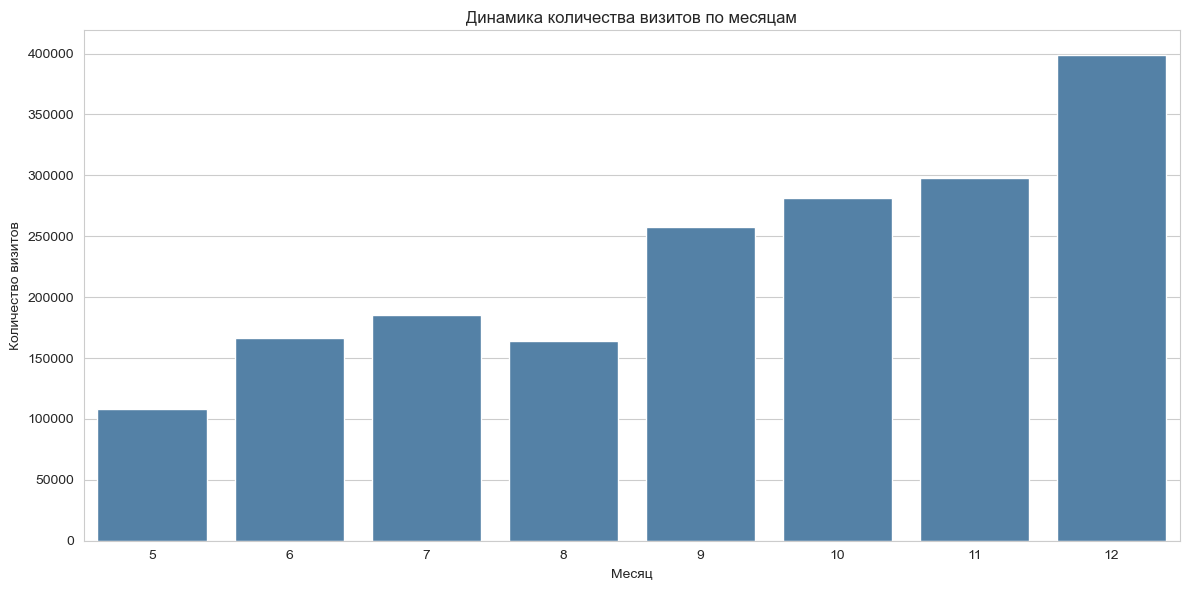

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

fig, ax1 = plt.subplots(figsize=(12, 6))

# Количество визитов
sns.barplot(
    data=monthly_stats,
    x='visit_month',
    y='visits',
    color='steelblue',
    ax=ax1
)

ax1.set_xlabel('Месяц')
ax1.set_ylabel('Количество визитов')
ax1.set_title('Динамика количества визитов по месяцам')

plt.tight_layout()
plt.show()


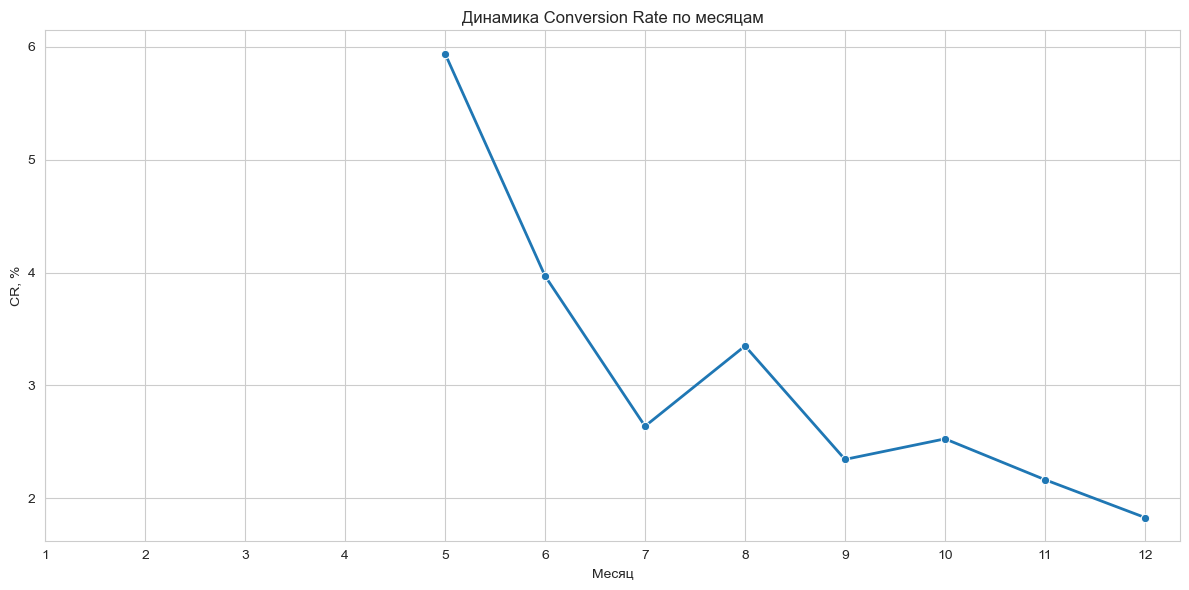

In [39]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_stats,
    x='visit_month',
    y='CR',
    marker='o',
    linewidth=2
)

plt.xlabel('Месяц')
plt.ylabel('CR, %')
plt.title('Динамика Conversion Rate по месяцам')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()


## Шаг 13. Анализ устройств

In [40]:
# Анализ трафика и CR по типу устройства

device_stats = (
    df.groupby('device_category')
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

device_stats['traffic_share_%'] = (
    device_stats['visits'] / len(df) * 100
).round(2)

device_stats['CR_%'] = (
    device_stats['CR'] * 100
).round(2)

device_stats = device_stats.sort_values(
    'visits',
    ascending=False
)

display(device_stats)


,device_category,visits,conversions,CR,traffic_share_%,CR_%
1,mobile,1474871,38379,0.026022,79.29,2.60
0,desktop,366863,11513,0.031382,19.72,3.14
2,tablet,18308,422,0.023050,0.98,2.31


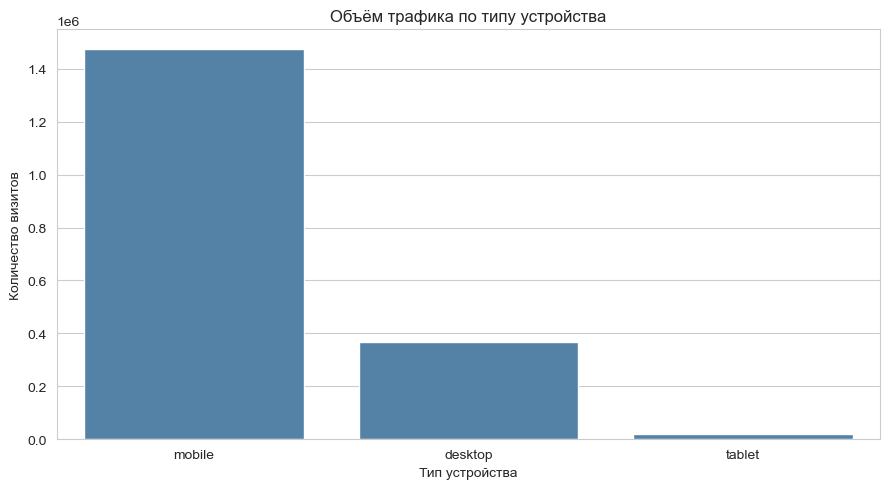

In [41]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=device_stats,
    x='device_category',
    y='visits',
    color='steelblue'
)

plt.xlabel('Тип устройства')
plt.ylabel('Количество визитов')
plt.title('Объём трафика по типу устройства')

plt.tight_layout()
plt.show()


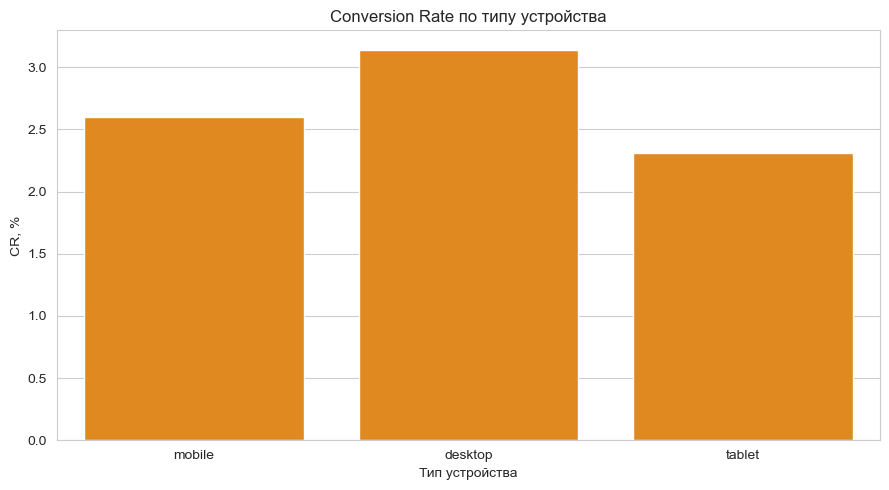

In [42]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=device_stats,
    x='device_category',
    y='CR_%',
    color='darkorange'
)

plt.xlabel('Тип устройства')
plt.ylabel('CR, %')
plt.title('Conversion Rate по типу устройства')

plt.tight_layout()
plt.show()


In [43]:
# Объединяем mobile и tablet в мобильный трафик

df['device_group'] = df['device_category'].replace({
    'mobile': 'mobile',
    'tablet': 'mobile',
    'desktop': 'desktop'
})

device_group_stats = (
    df.groupby('device_group')
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

device_group_stats['traffic_share_%'] = (
    device_group_stats['visits'] / len(df) * 100
).round(2)

device_group_stats['CR_%'] = (
    device_group_stats['CR'] * 100
).round(2)

display(device_group_stats)


,device_group,visits,conversions,CR,traffic_share_%,CR_%
0,desktop,366863,11513,0.031382,19.72,3.14
1,mobile,1493179,38801,0.025985,80.28,2.60


## Шаг 14. Анализ источников трафика

In [44]:
# Анализ трафика по типу привлечения

medium_stats = (
    df.groupby('utm_medium')
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

medium_stats['traffic_share_%'] = (
    medium_stats['visits'] / len(df) * 100
).round(2)

medium_stats['CR_%'] = (
    medium_stats['CR'] * 100
).round(2)

medium_stats = medium_stats.sort_values(
    'visits',
    ascending=False
)

display(medium_stats)


,utm_medium,visits,conversions,CR,traffic_share_%,CR_%
5,banner,552272,15107,0.027354,29.69,2.74
13,cpc,434794,9529,0.021916,23.38,2.19
0,(none),300575,10531,0.035036,16.16,3.50
14,cpm,242083,2519,0.010406,13.01,1.04
41,referral,152050,8181,0.053805,8.17,5.38
31,organic,63034,2100,0.033315,3.39,3.33
18,email,29240,401,0.013714,1.57,1.37
37,push,28035,840,0.029963,1.51,3.00
48,stories,10582,126,0.011907,0.57,1.19
15,cpv,8022,115,0.014336,0.43,1.43


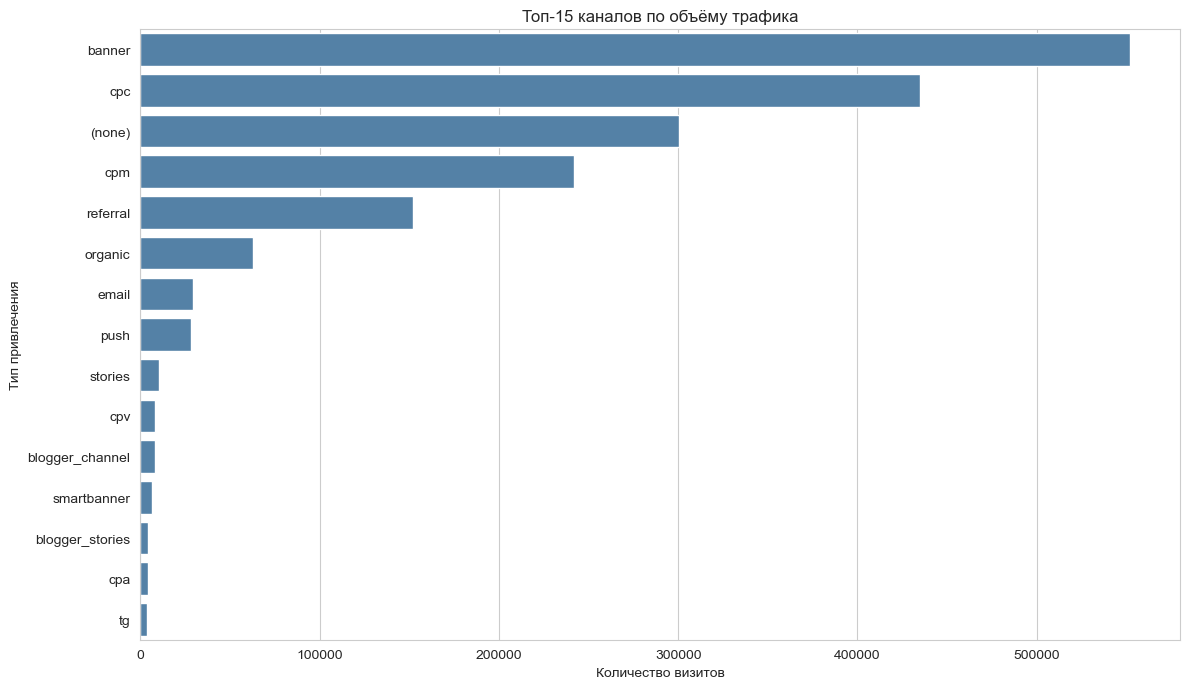

In [45]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=medium_stats.head(15),
    y='utm_medium',
    x='visits',
    color='steelblue'
)

plt.xlabel('Количество визитов')
plt.ylabel('Тип привлечения')
plt.title('Топ-15 каналов по объёму трафика')

plt.tight_layout()
plt.show()


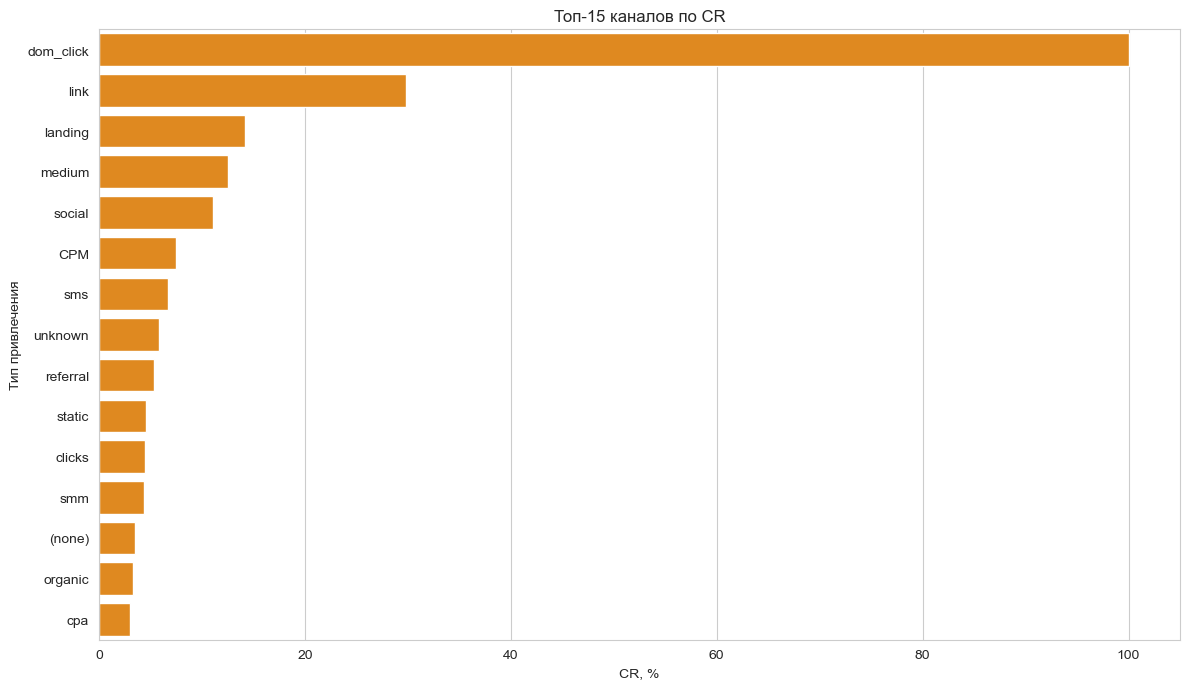

In [46]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=medium_stats.sort_values('CR_%', ascending=False).head(15),
    y='utm_medium',
    x='CR_%',
    color='darkorange'
)

plt.xlabel('CR, %')
plt.ylabel('Тип привлечения')
plt.title('Топ-15 каналов по CR')

plt.tight_layout()
plt.show()


## Шаг 15. Вывод по устройствам

Вывод

Основной объём трафика приходится на мобильные устройства — 79,29% всех визитов. При этом CR мобильного трафика составляет 2,60%, тогда как для desktop-трафика — 3,14%. Планшеты формируют менее 1% всего трафика, а их CR составляет 2,31%.

Таким образом, мобильные устройства являются основным источником трафика по объёму, однако на уровне описательной статистики CR для desktop выше. Для определения статистической значимости различий между мобильным и desktop-трафиком необходимо провести проверку соответствующей гипотезы.

## Шаг 16. Подготовка первой гипотезы

In [47]:
# Разделяем трафик на органический и платный

organic_mediums = ['organic', 'referral', '(none)']

df['traffic_type'] = df['utm_medium'].apply(
    lambda x: 'organic' if x in organic_mediums else 'paid'
)

display(
    df['traffic_type']
    .value_counts()
    .to_frame('Количество визитов')
)


,Количество визитов
traffic_type,
paid,1344383
organic,515659


In [48]:
# Объём трафика и CR для organic / paid

traffic_type_stats = (
    df.groupby('traffic_type')
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

traffic_type_stats['traffic_share_%'] = (
    traffic_type_stats['visits'] / len(df) * 100
).round(2)

traffic_type_stats['CR_%'] = (
    traffic_type_stats['CR'] * 100
).round(2)

display(traffic_type_stats)


,traffic_type,visits,conversions,CR,traffic_share_%,CR_%
0,organic,515659,20812,0.040360,27.72,4.04
1,paid,1344383,29502,0.021945,72.28,2.19


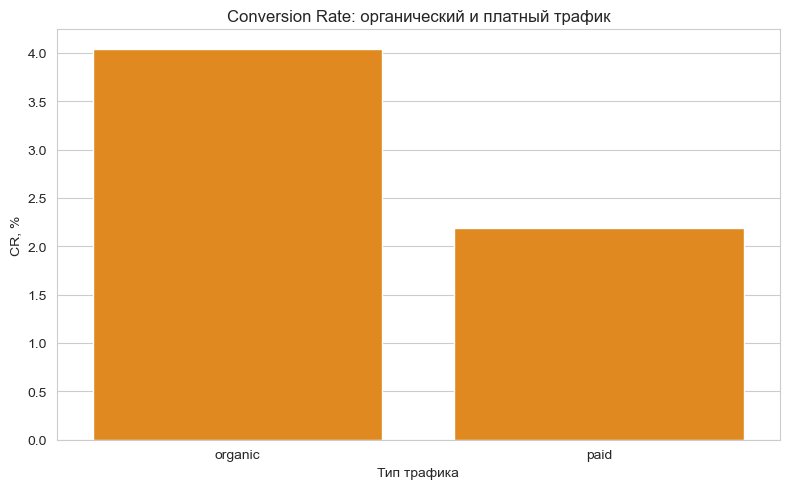

In [49]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=traffic_type_stats,
    x='traffic_type',
    y='CR_%',
    color='darkorange'
)

plt.xlabel('Тип трафика')
plt.ylabel('CR, %')
plt.title('Conversion Rate: органический и платный трафик')

plt.tight_layout()
plt.show()


## Шаг 17. Статистический тест первой гипотезы

In [50]:
from statsmodels.stats.proportion import proportions_ztest

# Количество целевых визитов
conversions = traffic_type_stats['conversions'].values

# Общее количество визитов
visits = traffic_type_stats['visits'].values

# Двухвыборочный z-тест для сравнения пропорций
stat, p_value = proportions_ztest(
    count=conversions,
    nobs=visits,
    alternative='two-sided'
)

print(f'Z-статистика: {stat:.4f}')
print(f'p-value: {p_value:.6f}')

alpha = 0.05

if p_value < alpha:
    print('Результат: отвергаем нулевую гипотезу H0.')
else:
    print('Результат: нет оснований отвергнуть нулевую гипотезу H0.')


Z-статистика: 69.3000
p-value: 0.000000
Результат: отвергаем нулевую гипотезу H0.


In [51]:
# Разница CR между organic и paid

organic_cr = traffic_type_stats.loc[
    traffic_type_stats['traffic_type'] == 'organic',
    'CR'
].iloc[0]

paid_cr = traffic_type_stats.loc[
    traffic_type_stats['traffic_type'] == 'paid',
    'CR'
].iloc[0]

cr_difference = organic_cr - paid_cr

print(f'CR organic: {organic_cr:.4%}')
print(f'CR paid: {paid_cr:.4%}')
print(f'Абсолютная разница CR: {cr_difference:.4%}')
print(f'Разница в процентных пунктах: {cr_difference * 100:.2f} п.п.')


CR organic: 4.0360%
CR paid: 2.1945%
Абсолютная разница CR: 1.8415%
Разница в процентных пунктах: 1.84 п.п.


In [52]:
from statsmodels.stats.proportion import confint_proportions_2indep

organic = traffic_type_stats[
    traffic_type_stats['traffic_type'] == 'organic'
].iloc[0]

paid = traffic_type_stats[
    traffic_type_stats['traffic_type'] == 'paid'
].iloc[0]

# 95% ДИ для разницы пропорций: organic - paid
ci_low, ci_high = confint_proportions_2indep(
    count1=organic['conversions'],
    nobs1=organic['visits'],
    count2=paid['conversions'],
    nobs2=paid['visits'],
    method='wald'
)

print(f'Разница CR: {(organic["CR"] - paid["CR"]) * 100:.2f} п.п.')
print(
    f'95% ДИ для разницы: '
    f'[{ci_low * 100:.2f}; {ci_high * 100:.2f}] п.п.'
)


Разница CR: 1.84 п.п.
95% ДИ для разницы: [1.78; 1.90] п.п.


### вывод
Organic-трафик имеет CR 4,04%, а paid — 2,19%. Разница составляет 1,84 п.п. 95%-й доверительный интервал для разницы находится в диапазоне от 1,78 до 1,90 п.п. Поскольку интервал не включает 0, различие между конверсиями статистически значимо. Это согласуется с результатом z-теста: p-value < 0,001.

При этом важно отметить, что organic даёт меньший объём трафика — около 516 тыс. визитов против 1,34 млн у paid. Поэтому при интерпретации каналов стоит учитывать одновременно объём трафика и CR, а не только конверсию.

## 18. Статистика по источникам

In [53]:
source_stats = (
    df.groupby('utm_source')
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

source_stats['traffic_share_%'] = (
    source_stats['visits'] / len(df) * 100
).round(2)

source_stats['CR_%'] = (
    source_stats['CR'] * 100
).round(2)

# По объёму трафика
source_by_traffic = (
    source_stats
    .sort_values('visits', ascending=False)
)

display(source_by_traffic.head(20))


,utm_source,visits,conversions,CR,traffic_share_%,CR_%
153,ZpYIoDJMcFzVoPFsHGJL,578290,15998,0.027664,31.09,2.77
183,fDLlAcSmythWSCVMvqvL,300575,10531,0.035036,16.16,3.50
217,kjsLglQLzykiRbcDiGcD,266354,6293,0.023626,14.32,2.36
79,MvfHsxITijuriZxsqZqt,186199,2249,0.012078,10.01,1.21
5,BHcvLfOaCWvWTykYqHVe,116320,3882,0.033373,6.25,3.34
161,bByPQxmDaMXgpHeypKSM,102287,5557,0.054328,5.50,5.43
99,QxAxdyPLuQMEcrdZWdWb,51415,1404,0.027307,2.76,2.73
158,aXQzDWsJuGXeBXexNHjc,31152,1827,0.058648,1.67,5.86
212,jaSOmLICuBzCFqHfBdRg,29241,401,0.013714,1.57,1.37
107,RmEBuqrriAfAVsLQQmhk,28055,139,0.004955,1.51,0.50


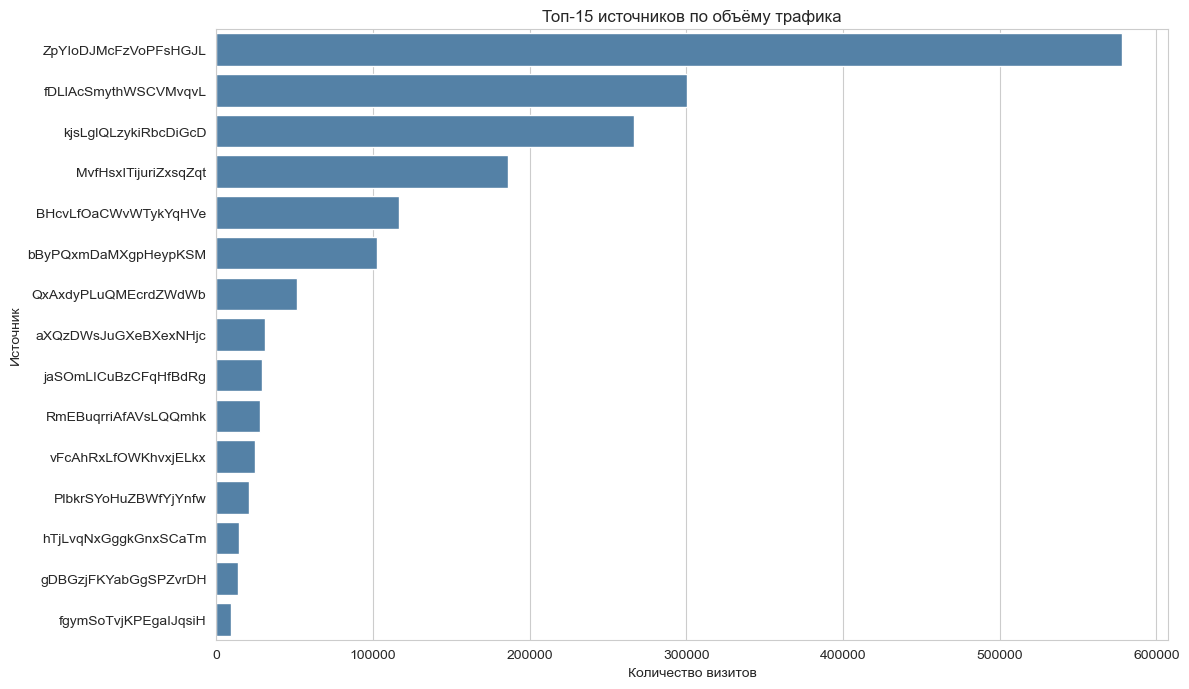

In [54]:
# График основных источников
plt.figure(figsize=(12, 7))

sns.barplot(
    data=source_by_traffic.head(15),
    y='utm_source',
    x='visits',
    color='steelblue'
)

plt.xlabel('Количество визитов')
plt.ylabel('Источник')
plt.title('Топ-15 источников по объёму трафика')

plt.tight_layout()
plt.show()


In [55]:
# CR источников с достаточным объёмом трафика
source_cr_reliable = (
    source_stats[source_stats['visits'] >= 5000]
    .sort_values('CR', ascending=False)
)

display(source_cr_reliable)


,utm_source,visits,conversions,CR,traffic_share_%,CR_%
158,aXQzDWsJuGXeBXexNHjc,31152,1827,0.058648,1.67,5.86
161,bByPQxmDaMXgpHeypKSM,102287,5557,0.054328,5.50,5.43
183,fDLlAcSmythWSCVMvqvL,300575,10531,0.035036,16.16,3.50
5,BHcvLfOaCWvWTykYqHVe,116320,3882,0.033373,6.25,3.34
153,ZpYIoDJMcFzVoPFsHGJL,578290,15998,0.027664,31.09,2.77
99,QxAxdyPLuQMEcrdZWdWb,51415,1404,0.027307,2.76,2.73
217,kjsLglQLzykiRbcDiGcD,266354,6293,0.023626,14.32,2.36
49,ISrKoXQCxqqYvAZICvjs,8633,141,0.016333,0.46,1.63
229,nSReTmyFtbSjlPrTKoaX,7285,104,0.014276,0.39,1.43
212,jaSOmLICuBzCFqHfBdRg,29241,401,0.013714,1.57,1.37


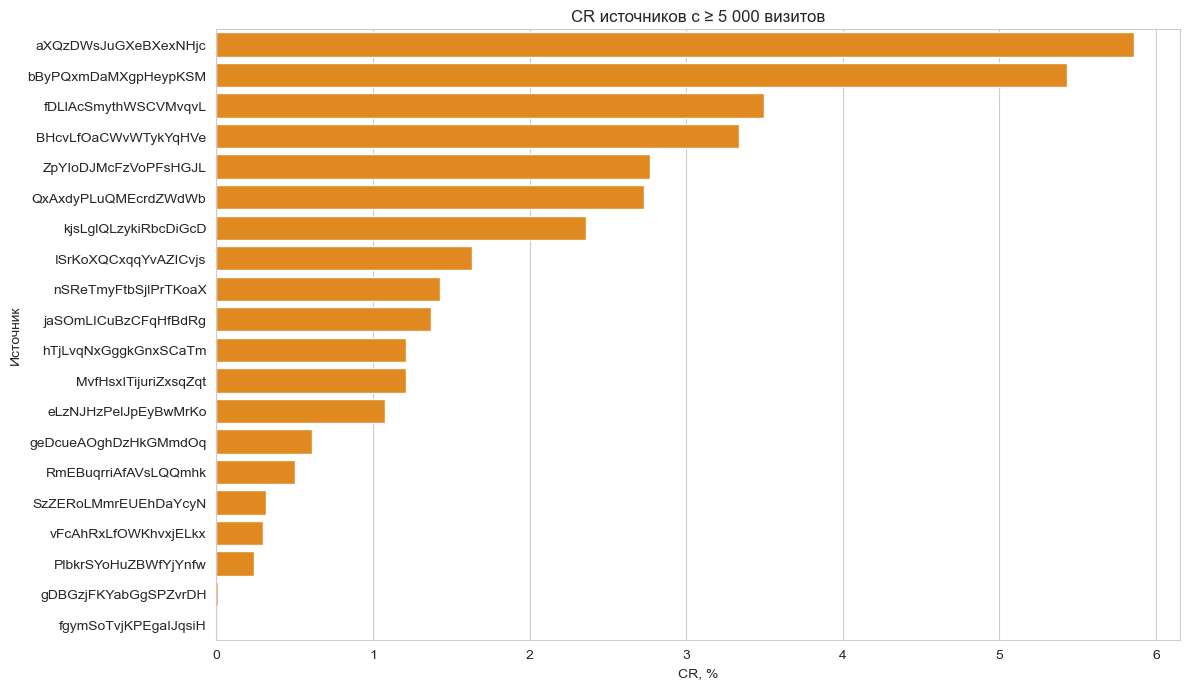

In [56]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=source_cr_reliable,
    y='utm_source',
    x='CR_%',
    color='darkorange'
)

plt.xlabel('CR, %')
plt.ylabel('Источник')
plt.title('CR источников с ≥ 5 000 визитов')

plt.tight_layout()
plt.show()


In [57]:
source_by_conversions = (
    source_stats
    .sort_values('conversions', ascending=False)
)

display(source_by_conversions.head(15))


,utm_source,visits,conversions,CR,traffic_share_%,CR_%
153,ZpYIoDJMcFzVoPFsHGJL,578290,15998,0.027664,31.09,2.77
183,fDLlAcSmythWSCVMvqvL,300575,10531,0.035036,16.16,3.50
217,kjsLglQLzykiRbcDiGcD,266354,6293,0.023626,14.32,2.36
161,bByPQxmDaMXgpHeypKSM,102287,5557,0.054328,5.50,5.43
5,BHcvLfOaCWvWTykYqHVe,116320,3882,0.033373,6.25,3.34
79,MvfHsxITijuriZxsqZqt,186199,2249,0.012078,10.01,1.21
158,aXQzDWsJuGXeBXexNHjc,31152,1827,0.058648,1.67,5.86
99,QxAxdyPLuQMEcrdZWdWb,51415,1404,0.027307,2.76,2.73
212,jaSOmLICuBzCFqHfBdRg,29241,401,0.013714,1.57,1.37
241,oZCzWSykfixnjMPDNjSU,3143,260,0.082724,0.17,8.27


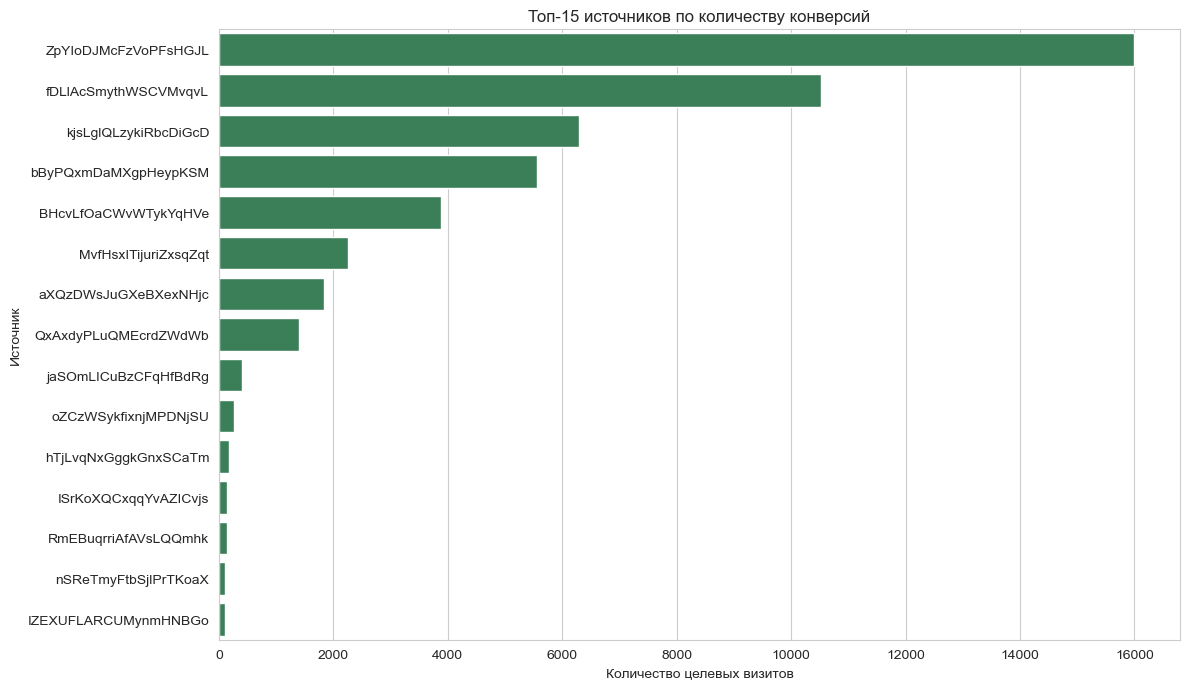

In [58]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=source_by_conversions.head(15),
    y='utm_source',
    x='conversions',
    color='seagreen'
)

plt.xlabel('Количество целевых визитов')
plt.ylabel('Источник')
plt.title('Топ-15 источников по количеству конверсий')

plt.tight_layout()
plt.show()


1. Основной объём трафика
Наибольший объём визитов дают несколько источников:

ZpYIoDJMcFzVoPFsHGJL — 578 290 визитов, 31,09% всего трафика;

fDLlAcSmythWSCVMvqvL — 300 575, 16,16%;

kjsLglQLzykiRbcDiGcD — 266 354, 14,32%;

MvfHsxITijuriZxsqZqt — 186 199, 10,01%;

BHcvLfOaCWvWTykYqHVe — 116 320, 6,25%;

bByPQxmDaMXgpHeypKSM — 102 287, 5,50%.

То есть только эти шесть источников формируют примерно 83% всего трафика. Это показывает, что трафик сильно сконцентрирован на ограниченном количестве источников.

2. CR источников
Если рассматривать источники минимум с 5 000 визитов, разброс CR довольно большой:

aXQzDWsJuGXeBXexNHjc — 5,86%;

bByPQxmDaMXgpHeypKSM — 5,43%;

fDLlAcSmythWSCVMvqvL — 3,50%;

BHcvLfOaCWvWTykYqHVe — 3,34%;

ZpYIoDJMcFzVoPFsHGJL — 2,77%;

kjsLglQLzykiRbcDiGcD — 2,36%;

MvfHsxITijuriZxsqZqt — 1,21%.

Здесь хорошо видно, почему одного объёма трафика недостаточно для оценки источника: например, MvfHsxITijuriZxsqZqt приводит 186 тыс. визитов, но CR составляет только 1,21%, тогда как bByPQxmDaMXgpHeypKSM приводит примерно 102 тыс. визитов при CR 5,43%.

3. Количество конверсий
По абсолютному числу целевых визитов картина немного другая:

ZpYIoDJMcFzVoPFsHGJL — 15 998 конверсий;

fDLlAcSmythWSCVMvqvL — 10 531;

kjsLglQLzykiRbcDiGcD — 6 293;

bByPQxmDaMXgpHeypKSM — 5 557;

BHcvLfOaCWvWTykYqHVe — 3 882;

MvfHsxITijuriZxsqZqt — 2 249.

Это хороший пример различия между CR и количеством конверсий. Источник может иметь относительно высокий CR, но при небольшом объёме трафика давать меньше целевых визитов в абсолютном выражении.

In [59]:
campaign_stats = (
    df.groupby('utm_campaign', dropna=False)
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

campaign_stats['traffic_share_%'] = (
    campaign_stats['visits'] / len(df) * 100
).round(2)

campaign_stats['CR_%'] = (
    campaign_stats['CR'] * 100
).round(2)

print('Топ-20 кампаний по объёму трафика:')
display(
    campaign_stats
    .sort_values('visits', ascending=False)
    .head(20)
)


Топ-20 кампаний по объёму трафика:


,utm_campaign,visits,conversions,CR,traffic_share_%,CR_%
88,LTuZkdKfxRGVceoWkVyg,463481,19006,0.041007,24.92,4.10
85,LEoPHuyFvzoNfnzGgfcd,324044,9348,0.028848,17.42,2.88
40,FTjNLDyTrXaWYgZymFkV,247360,2447,0.009892,13.30,0.99
363,unknown,219603,7174,0.032668,11.81,3.27
258,gecBYcKZCPMcVYdSSzKP,134042,4545,0.033907,7.21,3.39
156,TmThBvoCcwkCZZUWACYq,26597,123,0.004625,1.43,0.46
193,XHNUiSKKGTEpSAlaVMFQ,24524,401,0.016351,1.32,1.64
320,okTXSMadDkjvntEHzIjp,24511,77,0.003141,1.32,0.31
147,SgIUDYUKnyWHVowUOqid,22841,373,0.016330,1.23,1.63
352,sbJRYgVfvcnqKJNDDYIr,20188,575,0.028482,1.09,2.85


In [60]:
campaign_cr_reliable = (
    campaign_stats[
        campaign_stats['visits'] >= 5000
    ]
    .sort_values('CR', ascending=False)
)

print('Кампании с минимум 5 000 визитов:')
display(campaign_cr_reliable)


Кампании с минимум 5 000 визитов:


,utm_campaign,visits,conversions,CR,traffic_share_%,CR_%
88,LTuZkdKfxRGVceoWkVyg,463481,19006,0.041007,24.92,4.10
258,gecBYcKZCPMcVYdSSzKP,134042,4545,0.033907,7.21,3.39
242,eimRuUrNhZLAYcwRrNXu,7784,258,0.033145,0.42,3.31
363,unknown,219603,7174,0.032668,11.81,3.27
85,LEoPHuyFvzoNfnzGgfcd,324044,9348,0.028848,17.42,2.88
352,sbJRYgVfvcnqKJNDDYIr,20188,575,0.028482,1.09,2.85
282,jqlUOdZBNZYfInQVcZlS,6388,178,0.027865,0.34,2.79
186,WiILFRDQbcHDHNvHzGpX,5793,150,0.025893,0.31,2.59
100,MXqmDyetMTICSSitTjWV,7038,157,0.022307,0.38,2.23
411,zxoiLxhuSIFrCeTLQVWZ,12370,270,0.021827,0.67,2.18


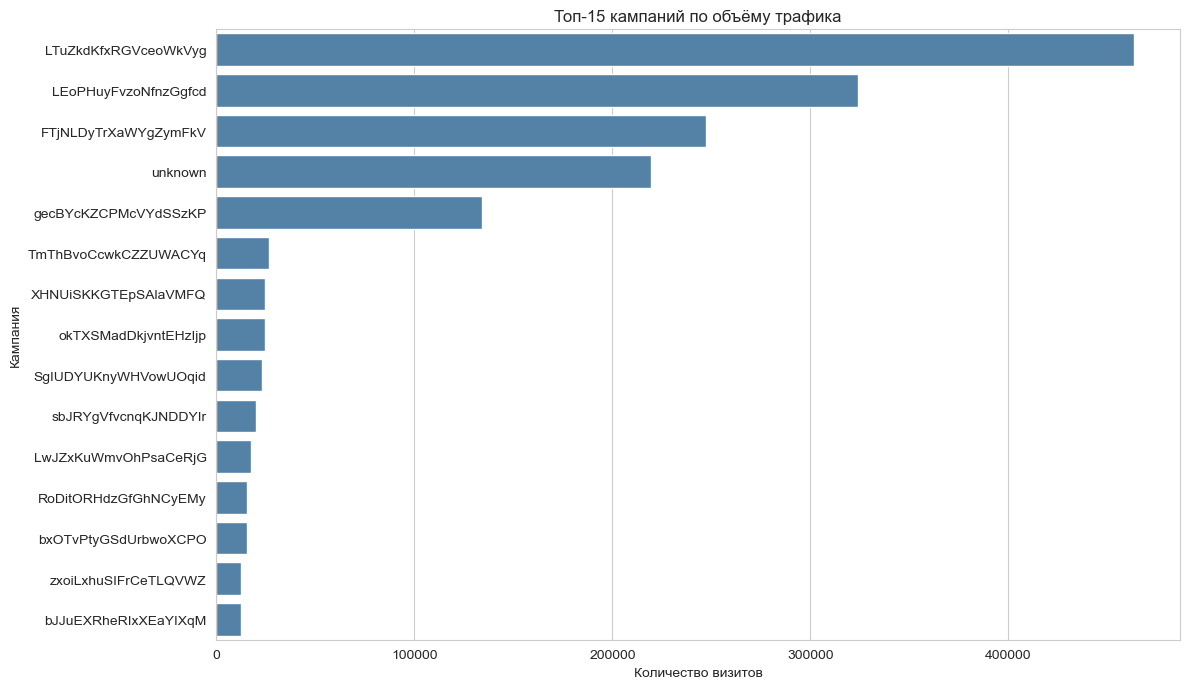

In [61]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=campaign_stats.sort_values(
        'visits',
        ascending=False
    ).head(15),
    y='utm_campaign',
    x='visits',
    color='steelblue'
)

plt.xlabel('Количество визитов')
plt.ylabel('Кампания')
plt.title('Топ-15 кампаний по объёму трафика')

plt.tight_layout()
plt.show()


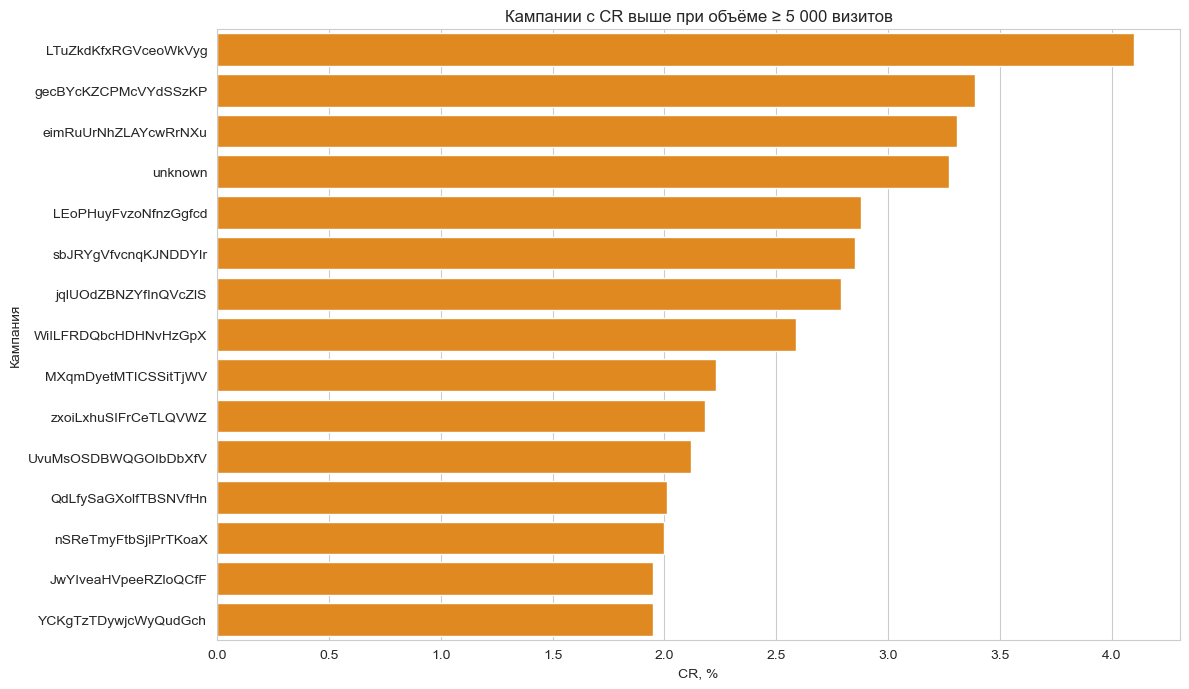

In [62]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=campaign_cr_reliable.head(15),
    y='utm_campaign',
    x='CR_%',
    color='darkorange'
)

plt.xlabel('CR, %')
plt.ylabel('Кампания')
plt.title('Кампании с CR выше при объёме ≥ 5 000 визитов')

plt.tight_layout()
plt.show()


## Шаг 19. Проверим источник + кампанию

In [63]:
source_campaign_stats = (
    df.groupby(['utm_source', 'utm_campaign'])
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

source_campaign_stats['traffic_share_%'] = (
    source_campaign_stats['visits'] / len(df) * 100
).round(2)

source_campaign_stats['CR_%'] = (
    source_campaign_stats['CR'] * 100
).round(2)

# Оставляем комбинации с достаточным объёмом
source_campaign_reliable = (
    source_campaign_stats[
        source_campaign_stats['visits'] >= 3000
    ]
    .sort_values('CR', ascending=False)
)

display(source_campaign_reliable.head(30))


,utm_source,utm_campaign,visits,conversions,CR,traffic_share_%,CR_%
568,bByPQxmDaMXgpHeypKSM,unknown,5615,569,0.101336,0.30,10.13
857,oZCzWSykfixnjMPDNjSU,LTuZkdKfxRGVceoWkVyg,3143,260,0.082724,0.17,8.27
9,BHcvLfOaCWvWTykYqHVe,LTuZkdKfxRGVceoWkVyg,5798,348,0.060021,0.31,6.00
366,aXQzDWsJuGXeBXexNHjc,LTuZkdKfxRGVceoWkVyg,31152,1827,0.058648,1.67,5.86
246,QxAxdyPLuQMEcrdZWdWb,unknown,7793,420,0.053895,0.42,5.39
409,bByPQxmDaMXgpHeypKSM,LTuZkdKfxRGVceoWkVyg,69841,3759,0.053822,3.75,5.38
772,kjsLglQLzykiRbcDiGcD,LTuZkdKfxRGVceoWkVyg,33565,1668,0.049695,1.80,4.97
515,bByPQxmDaMXgpHeypKSM,hkvDVxqLOzGjGaoNiNzN,3304,143,0.043281,0.18,4.33
613,fDLlAcSmythWSCVMvqvL,LTuZkdKfxRGVceoWkVyg,300575,10531,0.035036,16.16,3.50
350,ZpYIoDJMcFzVoPFsHGJL,gecBYcKZCPMcVYdSSzKP,132725,4398,0.033136,7.14,3.31


## Шаг 20. Посмотрим, какие кампании дают основной объём конверсий

In [64]:
# каsource_campaign_by_conversions = (
source_campaign_by_conversions = (
    source_campaign_stats
    .sort_values('conversions', ascending=False)
)

display(
    source_campaign_by_conversions.head(20)
)


,utm_source,utm_campaign,visits,conversions,CR,traffic_share_%,CR_%
613,fDLlAcSmythWSCVMvqvL,LTuZkdKfxRGVceoWkVyg,300575,10531,0.035036,16.16,3.50
334,ZpYIoDJMcFzVoPFsHGJL,LEoPHuyFvzoNfnzGgfcd,322783,9179,0.028437,17.35,2.84
350,ZpYIoDJMcFzVoPFsHGJL,gecBYcKZCPMcVYdSSzKP,132725,4398,0.033136,7.14,3.31
409,bByPQxmDaMXgpHeypKSM,LTuZkdKfxRGVceoWkVyg,69841,3759,0.053822,3.75,5.38
18,BHcvLfOaCWvWTykYqHVe,unknown,110479,3531,0.031961,5.94,3.20
818,kjsLglQLzykiRbcDiGcD,unknown,86919,2548,0.029315,4.67,2.93
137,MvfHsxITijuriZxsqZqt,FTjNLDyTrXaWYgZymFkV,182506,2185,0.011972,9.81,1.20
366,aXQzDWsJuGXeBXexNHjc,LTuZkdKfxRGVceoWkVyg,31152,1827,0.058648,1.67,5.86
772,kjsLglQLzykiRbcDiGcD,LTuZkdKfxRGVceoWkVyg,33565,1668,0.049695,1.80,4.97
359,ZpYIoDJMcFzVoPFsHGJL,sbJRYgVfvcnqKJNDDYIr,20167,574,0.028462,1.08,2.85


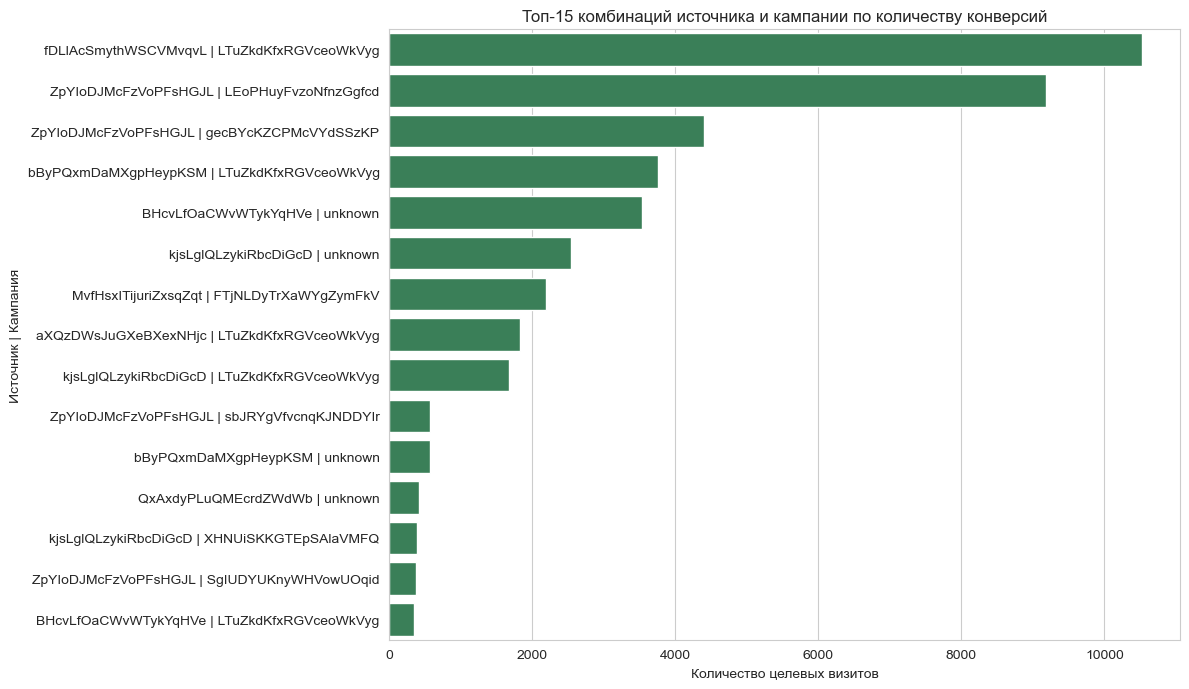

In [65]:
plt.figure(figsize=(12, 7))

plot_data = source_campaign_by_conversions.head(15).copy()

plot_data['source_campaign'] = (
    plot_data['utm_source'] + ' | ' +
    plot_data['utm_campaign']
)

sns.barplot(
    data=plot_data,
    y='source_campaign',
    x='conversions',
    color='seagreen'
)

plt.xlabel('Количество целевых визитов')
plt.ylabel('Источник | Кампания')
plt.title('Топ-15 комбинаций источника и кампании по количеству конверсий')

plt.tight_layout()
plt.show()


## Шаг 21. Проверим связь device_group × traffic_type

In [66]:
device_traffic_stats = (
    df.groupby(['traffic_type', 'device_group'])
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

device_traffic_stats['CR_%'] = (
    device_traffic_stats['CR'] * 100
).round(2)

device_traffic_stats['traffic_share_%'] = (
    device_traffic_stats['visits'] / len(df) * 100
).round(2)

display(device_traffic_stats)


,traffic_type,device_group,visits,conversions,CR,CR_%,traffic_share_%
0,organic,desktop,172072,8198,0.047643,4.76,9.25
1,organic,mobile,343587,12614,0.036713,3.67,18.47
2,paid,desktop,194791,3315,0.017018,1.70,10.47
3,paid,mobile,1149592,26187,0.022779,2.28,61.80


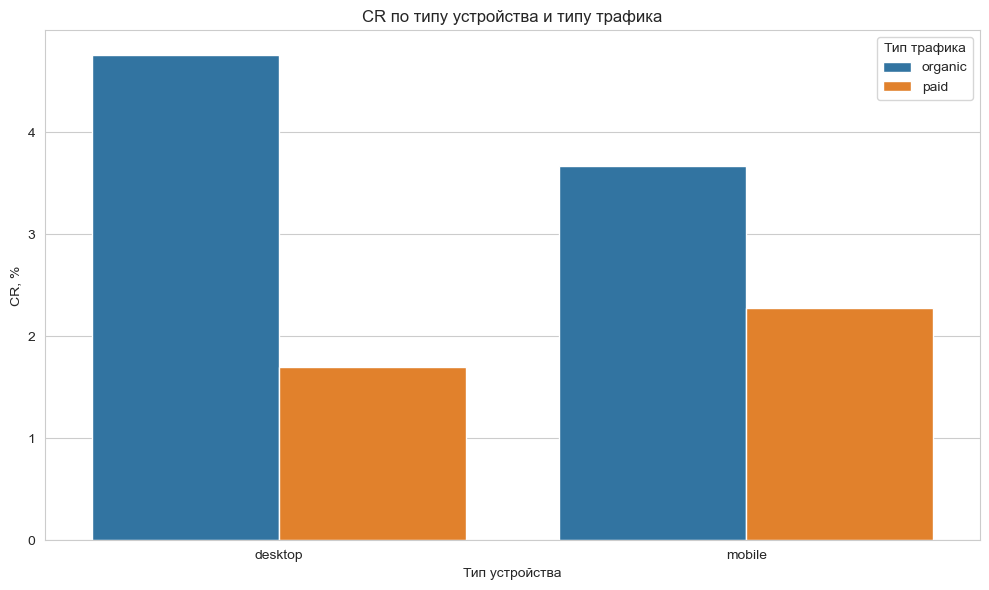

In [67]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=device_traffic_stats,
    x='device_group',
    y='CR_%',
    hue='traffic_type'
)

plt.xlabel('Тип устройства')
plt.ylabel('CR, %')
plt.title('CR по типу устройства и типу трафика')
plt.legend(title='Тип трафика')

plt.tight_layout()
plt.show()


## Шаг 22. Посмотрим влияние повторного визита

In [68]:
df['visit_group'] = pd.cut(
    df['visit_number'],
    bins=[0, 1, 2, 3, 5, 10, 20, float('inf')],
    labels=[
        '1',
        '2',
        '3',
        '4–5',
        '6–10',
        '11–20',
        '21+'
    ]
)

visit_number_stats = (
    df.groupby('visit_group', observed=True)
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

visit_number_stats['CR_%'] = (
    visit_number_stats['CR'] * 100
).round(2)

display(visit_number_stats)


,visit_group,visits,conversions,CR,CR_%
0,1,1376349,32366,0.023516,2.35
1,2,235656,7610,0.032293,3.23
2,3,81068,3047,0.037586,3.76
3,4–5,65937,2905,0.044057,4.41
4,6–10,48953,2295,0.046882,4.69
5,11–20,24442,1042,0.042632,4.26
6,21+,27637,1049,0.037956,3.80


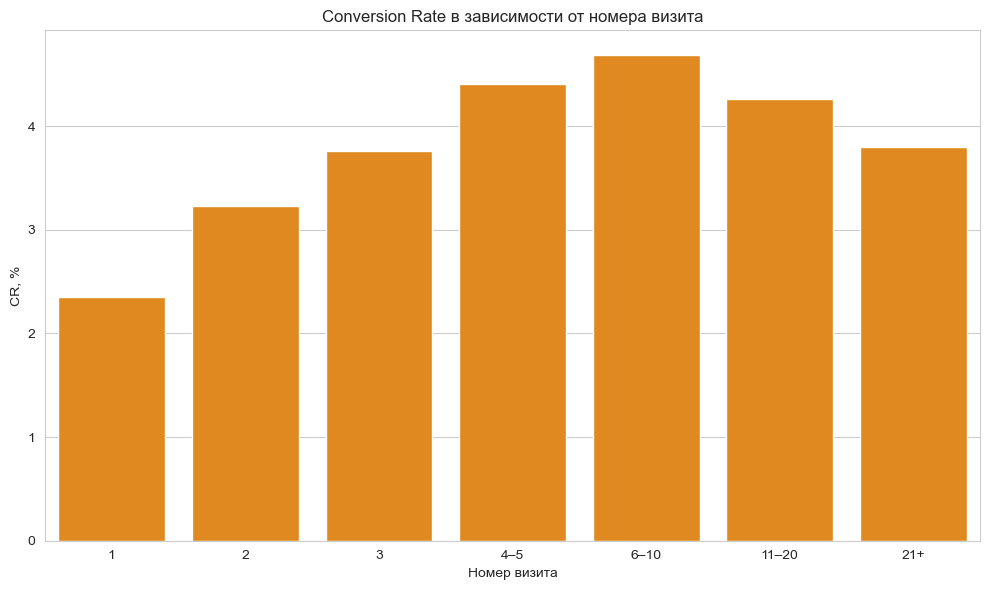

In [69]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=visit_number_stats,
    x='visit_group',
    y='CR_%',
    color='darkorange'
)

plt.xlabel('Номер визита')
plt.ylabel('CR, %')
plt.title('Conversion Rate в зависимости от номера визита')

plt.tight_layout()
plt.show()


## Шаг 23. Сначала проверим различия между первым и повторными визитами

In [70]:
from statsmodels.stats.proportion import proportions_ztest

first_visit = df['visit_number'] == 1
repeat_visit = df['visit_number'] > 1

conversions = [
    df.loc[first_visit, 'target'].sum(),
    df.loc[repeat_visit, 'target'].sum()
]

visits = [
    first_visit.sum(),
    repeat_visit.sum()
]

stat, p_value = proportions_ztest(
    count=conversions,
    nobs=visits,
    alternative='two-sided'
)

print(f'Первый визит: {conversions[0]} / {visits[0]}')
print(f'Повторные визиты: {conversions[1]} / {visits[1]}')

print(f'\nCR первого визита: {conversions[0] / visits[0]:.2%}')
print(f'CR повторных визитов: {conversions[1] / visits[1]:.2%}')

print(f'\nZ-статистика: {stat:.4f}')
print(f'p-value: {p_value:.10f}')


Первый визит: 32366 / 1376349
Повторные визиты: 17948 / 483693

CR первого визита: 2.35%
CR повторных визитов: 3.71%

Z-статистика: -50.1176
p-value: 0.0000000000


## Шаг 24. Теперь переходим к географии

In [71]:
country_stats = (
    df.groupby('geo_country')
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

country_stats['traffic_share_%'] = (
    country_stats['visits'] / len(df) * 100
).round(2)

country_stats['CR_%'] = (
    country_stats['CR'] * 100
).round(2)

display(
    country_stats
    .sort_values('visits', ascending=False)
    .head(20)
)


,geo_country,visits,conversions,CR,traffic_share_%,CR_%
122,Russia,1800565,49156,0.027300,96.80,2.73
156,United States,11784,64,0.005431,0.63,0.54
153,Ukraine,9012,199,0.022082,0.48,2.21
68,Ireland,4034,1,0.000248,0.22,0.02
15,Belarus,3636,59,0.016227,0.20,1.62
141,Sweden,2694,26,0.009651,0.14,0.97
73,Kazakhstan,2279,54,0.023695,0.12,2.37
51,Germany,2232,78,0.034946,0.12,3.49
150,Turkey,1953,48,0.024578,0.10,2.46
101,Netherlands,1549,38,0.024532,0.08,2.45


## Шаг 25. Страны с достаточным объёмом трафика

In [72]:
country_cr_reliable = (
    country_stats[
        country_stats['visits'] >= 1000
    ]
    .sort_values('CR', ascending=False)
)

display(country_cr_reliable)


,geo_country,visits,conversions,CR,traffic_share_%,CR_%
51,Germany,2232,78,0.034946,0.12,3.49
155,United Kingdom,1462,45,0.030780,0.08,3.08
122,Russia,1800565,49156,0.027300,96.80,2.73
165,unknown,1146,29,0.025305,0.06,2.53
150,Turkey,1953,48,0.024578,0.10,2.46
101,Netherlands,1549,38,0.024532,0.08,2.45
158,Uzbekistan,1523,37,0.024294,0.08,2.43
73,Kazakhstan,2279,54,0.023695,0.12,2.37
153,Ukraine,9012,199,0.022082,0.48,2.21
15,Belarus,3636,59,0.016227,0.20,1.62


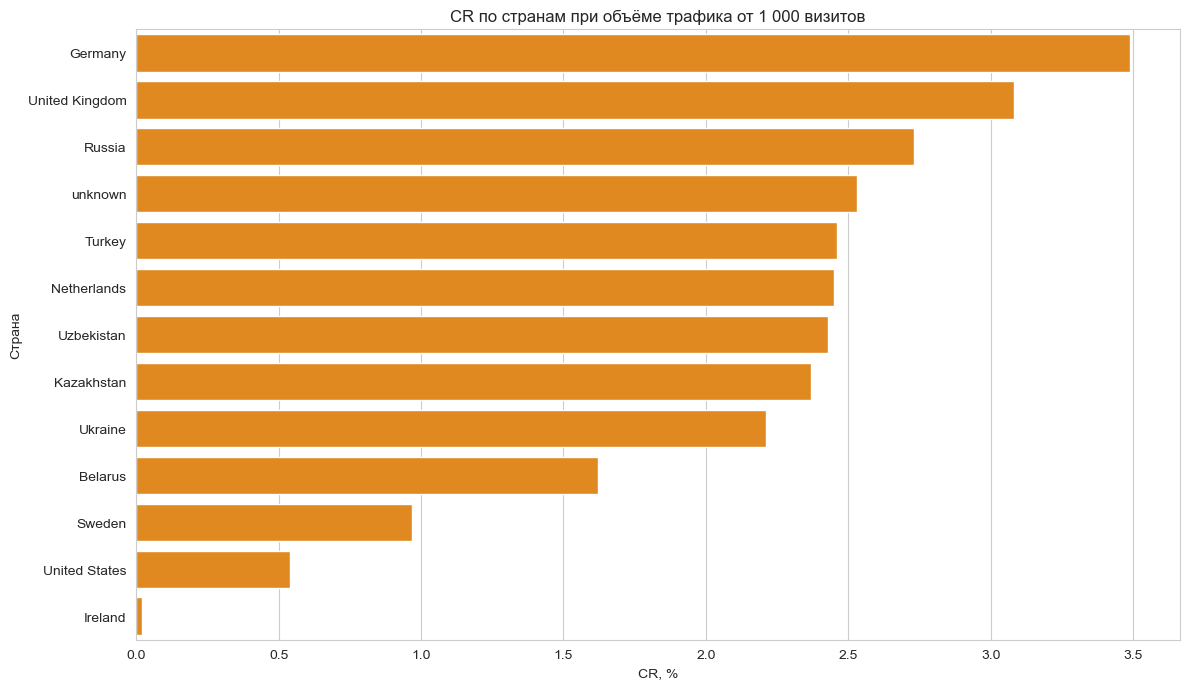

In [73]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=country_cr_reliable.head(15),
    y='geo_country',
    x='CR_%',
    color='darkorange'
)

plt.xlabel('CR, %')
plt.ylabel('Страна')
plt.title('CR по странам при объёме трафика от 1 000 визитов')

plt.tight_layout()
plt.show()


## Шаг 26. Отдельно посмотрим основные города России

In [74]:
russia_city_stats = (
    df[df['geo_country'] == 'Russia']
    .groupby('geo_city')
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

russia_city_stats['traffic_share_%'] = (
    russia_city_stats['visits'] /
    russia_city_stats['visits'].sum() * 100
).round(2)

russia_city_stats['CR_%'] = (
    russia_city_stats['CR'] * 100
).round(2)


In [75]:
display(
    russia_city_stats
    .sort_values('visits', ascending=False)
    .head(20)
)


,geo_city,visits,conversions,CR,traffic_share_%,CR_%
247,Moscow,805329,23629,0.029341,44.73,2.93
350,Saint Petersburg,296788,7113,0.023967,16.48,2.40
502,unknown,70021,1361,0.019437,3.89,1.94
479,Yekaterinburg,35788,887,0.024785,1.99,2.48
187,Krasnodar,32243,1081,0.033527,1.79,3.35
146,Kazan,29531,1139,0.038570,1.64,3.86
354,Samara,24992,727,0.029089,1.39,2.91
269,Nizhny Novgorod,22227,559,0.025150,1.23,2.51
430,Ufa,21679,639,0.029476,1.20,2.95
285,Novosibirsk,21568,509,0.023600,1.20,2.36


In [76]:
russia_city_cr_reliable = (
    russia_city_stats[
        russia_city_stats['visits'] >= 5000
    ]
    .sort_values('CR', ascending=False)
)

display(russia_city_cr_reliable)


,geo_city,visits,conversions,CR,traffic_share_%,CR_%
146,Kazan,29531,1139,0.038570,1.64,3.86
386,Sochi,8972,316,0.035221,0.50,3.52
187,Krasnodar,32243,1081,0.033527,1.79,3.35
151,Khimki,7385,236,0.031957,0.41,3.20
118,Grozny,12742,401,0.031471,0.71,3.15
430,Ufa,21679,639,0.029476,1.20,2.95
247,Moscow,805329,23629,0.029341,44.73,2.93
354,Samara,24992,727,0.029089,1.39,2.91
295,Odintsovo,5314,152,0.028604,0.30,2.86
342,Rostov-on-Don,13886,397,0.028590,0.77,2.86


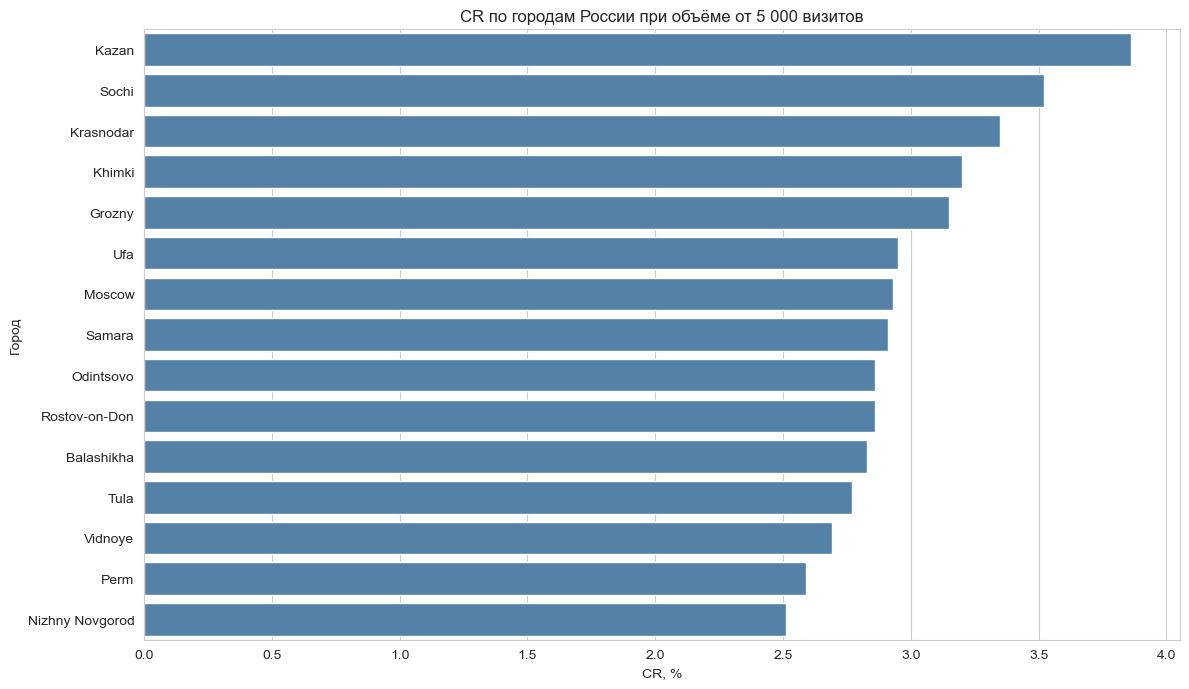

In [77]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=russia_city_cr_reliable.head(15),
    y='geo_city',
    x='CR_%',
    color='steelblue'
)

plt.xlabel('CR, %')
plt.ylabel('Город')
plt.title('CR по городам России при объёме от 5 000 визитов')

plt.tight_layout()
plt.show()


## Шаг 27. Анализ конверсии по времени суток

In [78]:
device_visit_stats = (
    df.groupby(
        ['device_group', 'visit_group'],
        observed=True
    )
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

device_visit_stats['CR_%'] = (
    device_visit_stats['CR'] * 100
).round(2)

display(device_visit_stats)


,device_group,visit_group,visits,conversions,CR,CR_%
0,desktop,1,246226,5821,0.023641,2.36
1,desktop,2,44703,1971,0.044091,4.41
2,desktop,3,17731,930,0.052451,5.25
3,desktop,4–5,16554,902,0.054488,5.45
4,desktop,6–10,14179,745,0.052542,5.25
5,desktop,11–20,9101,368,0.040435,4.04
6,desktop,21+,18369,776,0.042245,4.22
7,mobile,1,1130123,26545,0.023489,2.35
8,mobile,2,190953,5639,0.029531,2.95
9,mobile,3,63337,2117,0.033424,3.34


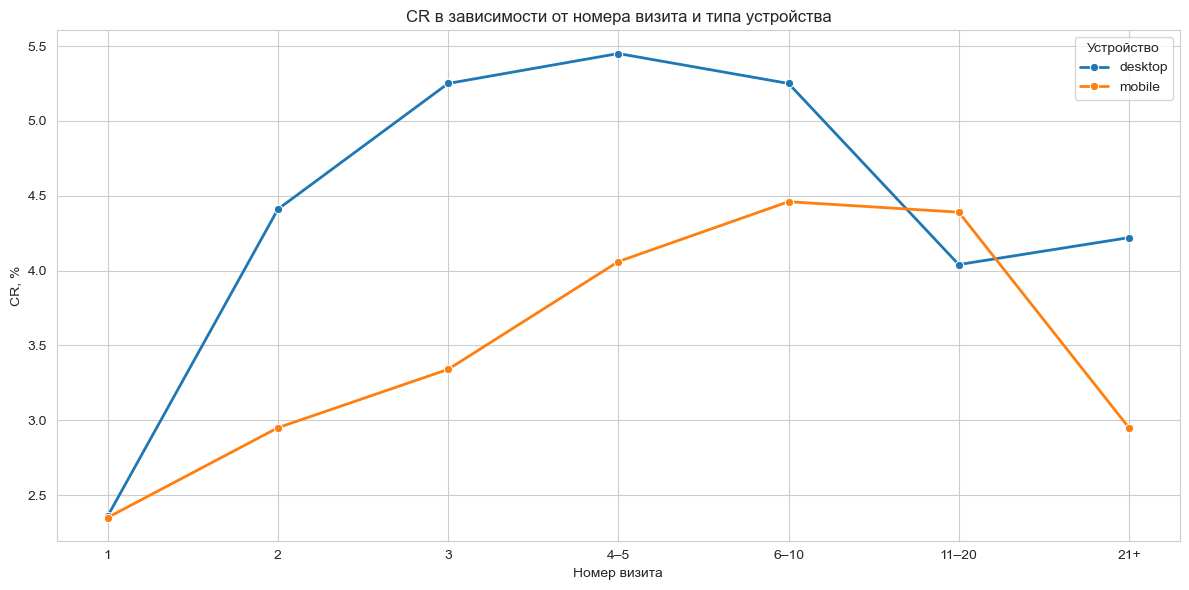

In [79]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=device_visit_stats,
    x='visit_group',
    y='CR_%',
    hue='device_group',
    marker='o',
    linewidth=2
)

plt.xlabel('Номер визита')
plt.ylabel('CR, %')
plt.title('CR в зависимости от номера визита и типа устройства')
plt.legend(title='Устройство')

plt.tight_layout()
plt.show()


## Шаг 28. Проверяем разницу CR между desktop и mobile

In [80]:
from statsmodels.stats.proportion import proportions_ztest

results = []

for visit_group in device_visit_stats['visit_group'].unique():

    temp = device_visit_stats[
        device_visit_stats['visit_group'] == visit_group
    ]

    desktop = temp[temp['device_group'] == 'desktop'].iloc[0]
    mobile = temp[temp['device_group'] == 'mobile'].iloc[0]

    conversions = [
        desktop['conversions'],
        mobile['conversions']
    ]

    visits = [
        desktop['visits'],
        mobile['visits']
    ]

    stat, p_value = proportions_ztest(
        count=conversions,
        nobs=visits,
        alternative='two-sided'
    )

    cr_difference = (
        desktop['CR'] - mobile['CR']
    ) * 100

    results.append({
        'visit_group': visit_group,
        'desktop_CR_%': desktop['CR'] * 100,
        'mobile_CR_%': mobile['CR'] * 100,
        'difference_p.p.': cr_difference,
        'z_stat': stat,
        'p_value': p_value
    })

device_visit_test = pd.DataFrame(results)

display(device_visit_test)


,visit_group,desktop_CR_%,mobile_CR_%,difference_p.p.,z_stat,p_value
0,1,2.364088,2.348859,0.015229,0.451878,6.513568e-01
1,2,4.409100,2.953083,1.456017,15.675948,2.209030e-55
2,3,5.245051,3.342438,1.902613,11.774123,5.306628e-32
3,4–5,5.448834,4.056052,1.392782,7.556740,4.132973e-14
4,6–10,5.254249,4.457353,0.796896,3.783442,1.546745e-04
5,11–20,4.043512,4.393455,-0.349944,-1.309170,1.904766e-01
6,21+,4.224509,2.945619,1.278889,5.252712,1.498756e-07


In [81]:
device_visit_test['significant'] = (
    device_visit_test['p_value'] < 0.05
)

display(device_visit_test)


,visit_group,desktop_CR_%,mobile_CR_%,difference_p.p.,z_stat,p_value,significant
0,1,2.364088,2.348859,0.015229,0.451878,6.513568e-01,False
1,2,4.409100,2.953083,1.456017,15.675948,2.209030e-55,True
2,3,5.245051,3.342438,1.902613,11.774123,5.306628e-32,True
3,4–5,5.448834,4.056052,1.392782,7.556740,4.132973e-14,True
4,6–10,5.254249,4.457353,0.796896,3.783442,1.546745e-04,True
5,11–20,4.043512,4.393455,-0.349944,-1.309170,1.904766e-01,False
6,21+,4.224509,2.945619,1.278889,5.252712,1.498756e-07,True


## Шаг 29. Анализ CR по часам суток

In [82]:
# Анализ количества визитов и CR по часам суток

hour_stats = (
    df.groupby('visit_hour')
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

hour_stats['traffic_share_%'] = (
    hour_stats['visits'] / len(df) * 100
).round(2)

hour_stats['CR_%'] = (
    hour_stats['CR'] * 100
).round(2)

display(hour_stats)


,visit_hour,visits,conversions,CR,traffic_share_%,CR_%
0,0,66202,1886,0.028489,3.56,2.85
1,1,40080,1121,0.027969,2.15,2.80
2,2,27328,644,0.023566,1.47,2.36
3,3,21036,484,0.023008,1.13,2.30
4,4,20220,468,0.023145,1.09,2.31
5,5,25292,569,0.022497,1.36,2.25
6,6,36440,721,0.019786,1.96,1.98
7,7,54894,1194,0.021751,2.95,2.18
8,8,72015,1699,0.023592,3.87,2.36
9,9,91860,2317,0.025223,4.94,2.52


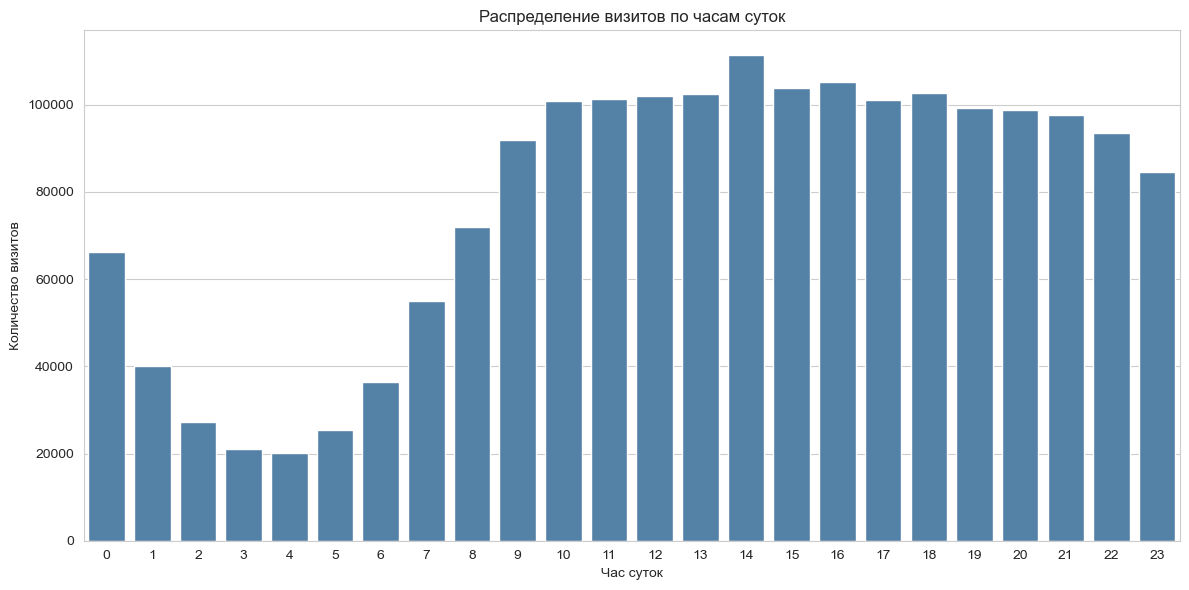

In [83]:
# График распределения количества визитов по часам суток

plt.figure(figsize=(12, 6))

sns.barplot(
    data=hour_stats,
    x='visit_hour',
    y='visits',
    color='steelblue'
)

plt.xlabel('Час суток')
plt.ylabel('Количество визитов')
plt.title('Распределение визитов по часам суток')
plt.xticks(range(24))

plt.tight_layout()
plt.show()


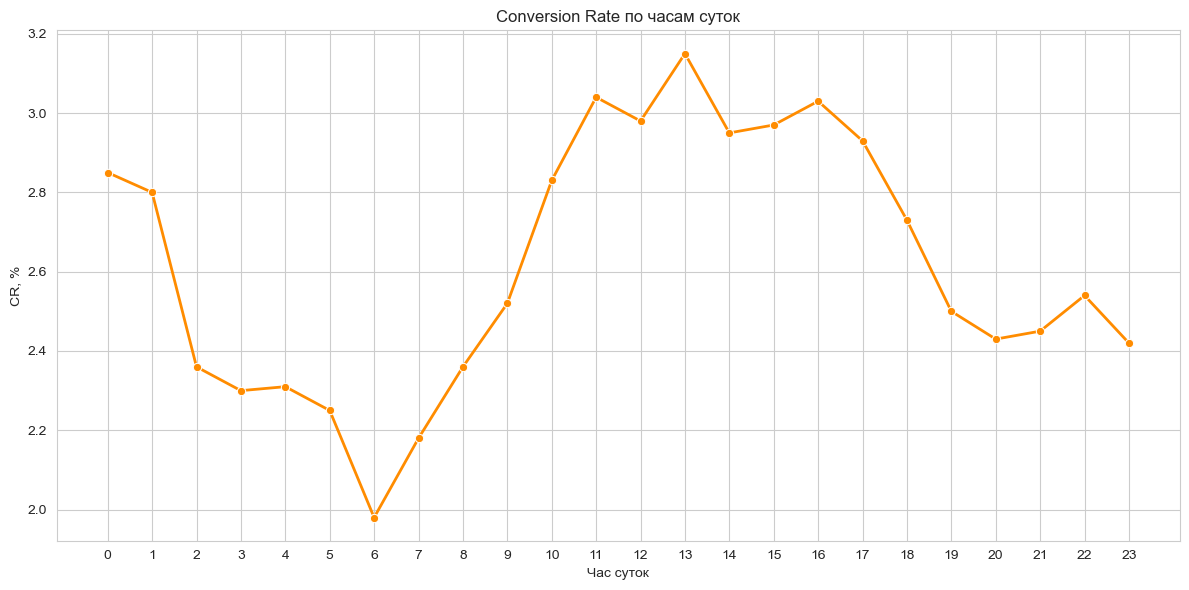

In [84]:
# График Conversion Rate по часам суток

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hour_stats,
    x='visit_hour',
    y='CR_%',
    marker='o',
    linewidth=2,
    color='darkorange'
)

plt.xlabel('Час суток')
plt.ylabel('CR, %')
plt.title('Conversion Rate по часам суток')
plt.xticks(range(24))

plt.tight_layout()
plt.show()


## Шаг 30. Анализ визитов и CR по дням недели

In [85]:
# Анализ количества визитов и CR по дням недели

weekday_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

weekday_stats = (
    df.groupby('visit_weekday')
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

weekday_stats['traffic_share_%'] = (
    weekday_stats['visits'] / len(df) * 100
).round(2)

weekday_stats['CR_%'] = (
    weekday_stats['CR'] * 100
).round(2)

weekday_stats['visit_weekday'] = pd.Categorical(
    weekday_stats['visit_weekday'],
    categories=weekday_order,
    ordered=True
)

weekday_stats = weekday_stats.sort_values('visit_weekday')

display(weekday_stats)


,visit_weekday,visits,conversions,CR,traffic_share_%,CR_%
1,Monday,300906,9467,0.031462,16.18,3.15
5,Tuesday,305130,8679,0.028444,16.40,2.84
6,Wednesday,258616,7274,0.028127,13.90,2.81
4,Thursday,274462,7232,0.026350,14.76,2.63
0,Friday,268819,6555,0.024384,14.45,2.44
2,Saturday,226397,5573,0.024616,12.17,2.46
3,Sunday,225712,5534,0.024518,12.13,2.45


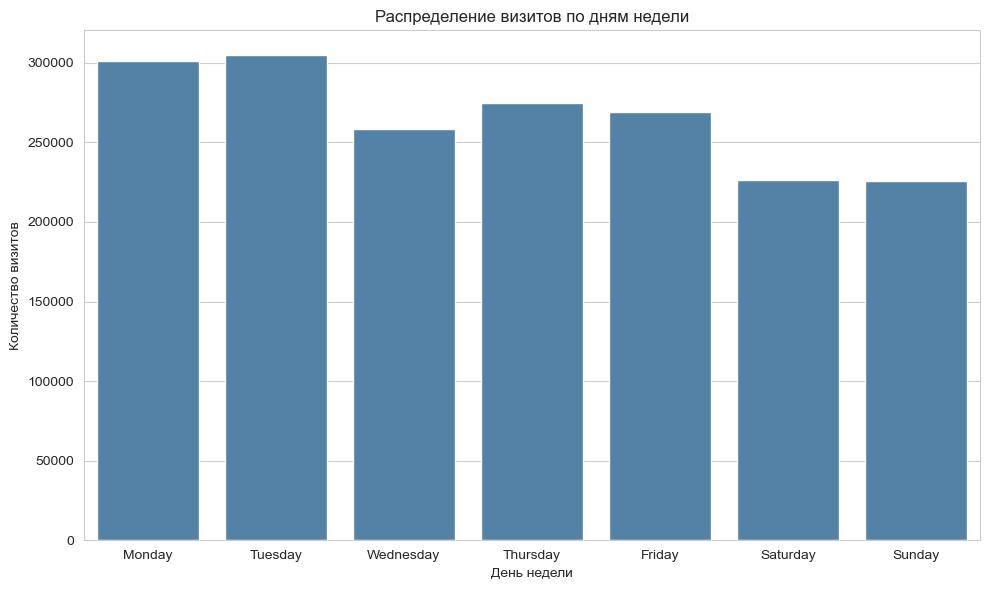

In [86]:
# График распределения количества визитов по дням недели

plt.figure(figsize=(10, 6))

sns.barplot(
    data=weekday_stats,
    x='visit_weekday',
    y='visits',
    color='steelblue'
)

plt.xlabel('День недели')
plt.ylabel('Количество визитов')
plt.title('Распределение визитов по дням недели')

plt.tight_layout()
plt.show()


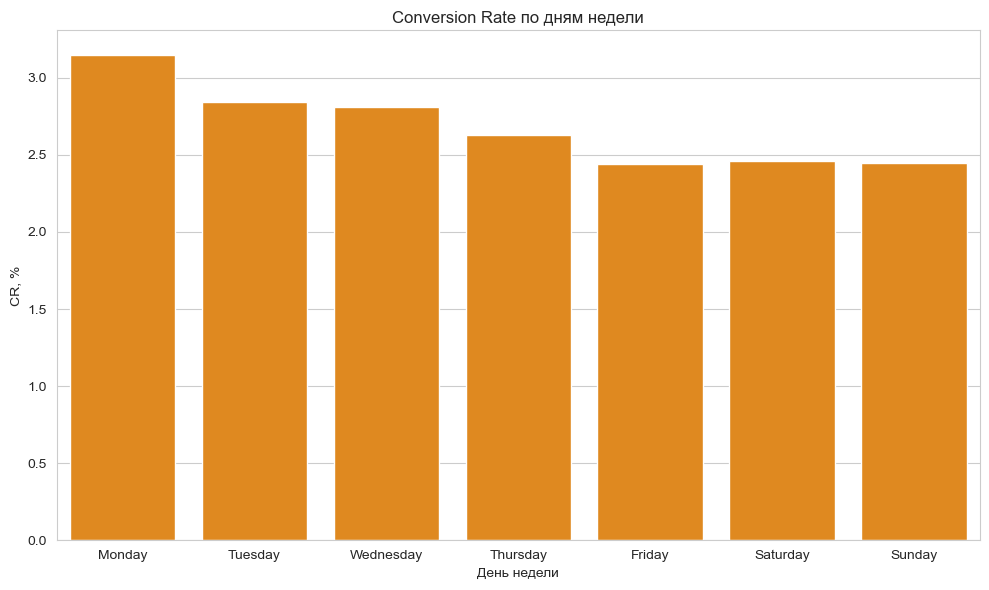

In [87]:
# График Conversion Rate по дням недели

plt.figure(figsize=(10, 6))

sns.barplot(
    data=weekday_stats,
    x='visit_weekday',
    y='CR_%',
    color='darkorange'
)

plt.xlabel('День недели')
plt.ylabel('CR, %')
plt.title('Conversion Rate по дням недели')

plt.tight_layout()
plt.show()


Вывод по дням недели
Наибольший объём трафика приходится на вторник — 305 130 визитов (16.40%), затем понедельник — 300 906 (16.18%).

Минимальный объём — в воскресенье: 225 712 визитов (12.13%).

CR постепенно снижается от начала недели к пятнице:

Monday — 3.15%

Tuesday — 2.84%

Wednesday — 2.81%

Thursday — 2.63%

Friday — 2.44%

В выходные CR остаётся примерно на уровне 2.45%.

Максимальный CR наблюдается в понедельник, минимальный — в пятницу.

## Шаг 31. Heatmap CR: день недели × час

In [88]:
# Расчёт Conversion Rate по сочетанию дня недели и часа суток

weekday_hour_stats = (
    df.groupby(
        ['visit_weekday', 'visit_hour'],
        observed=True
    )
    .agg(
        visits=('session_id', 'count'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

weekday_hour_stats['CR_%'] = (
    weekday_hour_stats['CR'] * 100
).round(2)

weekday_hour_stats['visit_weekday'] = pd.Categorical(
    weekday_hour_stats['visit_weekday'],
    categories=weekday_order,
    ordered=True
)

weekday_hour_stats = weekday_hour_stats.sort_values(
    ['visit_weekday', 'visit_hour']
)

display(weekday_hour_stats.head(20))


,visit_weekday,visit_hour,visits,conversions,CR,CR_%
24,Monday,0,8653,292,0.033746,3.37
25,Monday,1,5232,155,0.029625,2.96
26,Monday,2,3547,112,0.031576,3.16
27,Monday,3,2665,78,0.029268,2.93
28,Monday,4,2686,62,0.023083,2.31
29,Monday,5,3444,92,0.026713,2.67
30,Monday,6,5204,121,0.023251,2.33
31,Monday,7,7734,205,0.026506,2.65
32,Monday,8,10436,285,0.027309,2.73
33,Monday,9,14465,456,0.031524,3.15


In [89]:
# Формирование сводной таблицы для тепловой карты CR

heatmap_data = weekday_hour_stats.pivot(
    index='visit_weekday',
    columns='visit_hour',
    values='CR_%'
)

display(heatmap_data)


visit_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
visit_weekday,,,,,,,,,,,,,,,,,,,,,
Monday,3.37,2.96,3.16,2.93,2.31,2.67,2.33,2.65,2.73,3.15,...,3.50,3.37,3.62,3.53,3.01,2.71,2.54,2.50,2.70,2.66
Tuesday,2.66,3.19,2.62,2.63,2.58,2.15,2.24,2.10,2.45,2.66,...,2.91,3.04,3.09,3.11,3.24,2.74,2.61,2.60,2.88,2.83
Wednesday,3.09,2.75,2.67,2.73,2.48,2.21,1.96,2.43,2.31,2.58,...,3.06,3.30,3.14,2.87,3.10,2.75,2.48,2.32,2.57,2.23
Thursday,2.80,3.00,2.29,1.90,2.03,1.86,1.68,1.86,2.14,2.46,...,3.02,3.14,3.29,2.81,2.68,2.26,2.41,2.33,2.63,2.25
Friday,2.82,2.50,2.22,1.95,2.50,2.23,1.79,1.98,2.43,2.22,...,2.56,2.39,2.57,2.63,2.12,2.25,2.08,2.41,2.00,2.25
Saturday,2.89,2.24,1.75,1.71,2.02,2.36,1.96,2.20,2.32,2.13,...,2.74,2.79,2.61,2.71,2.41,2.39,2.36,2.57,2.52,2.29
Sunday,2.41,2.98,2.00,2.48,2.31,2.35,1.83,2.08,2.06,2.23,...,2.70,2.68,2.65,2.67,2.43,2.36,2.46,2.39,2.50,2.29


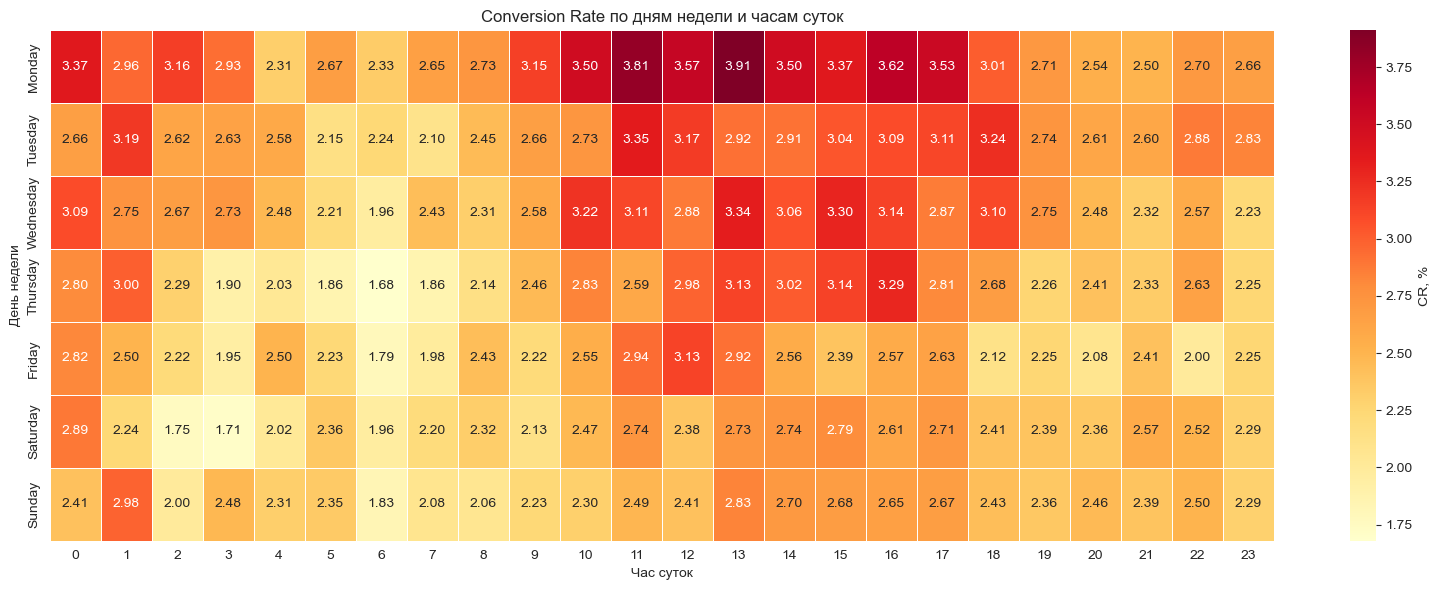

In [90]:
# Тепловая карта Conversion Rate по дням недели и часам суток

plt.figure(figsize=(16, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'CR, %'}
)

plt.xlabel('Час суток')
plt.ylabel('День недели')
plt.title('Conversion Rate по дням недели и часам суток')

plt.tight_layout()
plt.show()


## Шаг 32. Проверим различия CR по дням недели

In [91]:
# Подготовка данных для сравнения CR между днями недели

weekday_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

weekday_stats['visit_weekday'] = pd.Categorical(
    weekday_stats['visit_weekday'],
    categories=weekday_order,
    ordered=True
)

weekday_stats = weekday_stats.sort_values('visit_weekday')

display(weekday_stats)


,visit_weekday,visits,conversions,CR,traffic_share_%,CR_%
1,Monday,300906,9467,0.031462,16.18,3.15
5,Tuesday,305130,8679,0.028444,16.40,2.84
6,Wednesday,258616,7274,0.028127,13.90,2.81
4,Thursday,274462,7232,0.026350,14.76,2.63
0,Friday,268819,6555,0.024384,14.45,2.44
2,Saturday,226397,5573,0.024616,12.17,2.46
3,Sunday,225712,5534,0.024518,12.13,2.45


In [92]:
# Сравнение CR понедельника с каждым из остальных дней недели

from statsmodels.stats.proportion import proportions_ztest

monday = weekday_stats[
    weekday_stats['visit_weekday'] == 'Monday'
].iloc[0]

weekday_tests = []

for _, row in weekday_stats.iterrows():

    # Пропускаем сравнение понедельника с самим собой
    if row['visit_weekday'] == 'Monday':
        continue

    # Количество конверсий в двух группах
    count = [
        monday['conversions'],
        row['conversions']
    ]

    # Общее количество визитов в двух группах
    nobs = [
        monday['visits'],
        row['visits']
    ]

    # Двухвыборочный z-тест для сравнения CR
    z_stat, p_value = proportions_ztest(
        count=count,
        nobs=nobs,
        alternative='two-sided'
    )

    weekday_tests.append({
        'day_1': 'Monday',
        'day_2': row['visit_weekday'],
        'CR_day_1_%': monday['CR'] * 100,
        'CR_day_2_%': row['CR'] * 100,
        'difference_p.p.': (
            monday['CR'] - row['CR']
        ) * 100,
        'z_stat': z_stat,
        'p_value': p_value
    })

weekday_tests = pd.DataFrame(weekday_tests)

# Проверяем статистическую значимость на уровне 5%
weekday_tests['significant'] = (
    weekday_tests['p_value'] < 0.05
)

display(weekday_tests)


,day_1,day_2,CR_day_1_%,CR_day_2_%,difference_p.p.,z_stat,p_value,significant
0,Monday,Tuesday,3.146165,2.844361,0.301804,6.892763,5.471901e-12,True
1,Monday,Wednesday,3.146165,2.812664,0.333501,7.300384,2.869474e-13,True
2,Monday,Thursday,3.146165,2.634973,0.511192,11.536950,8.591811e-31,True
3,Monday,Friday,3.146165,2.438444,0.707722,16.130345,1.561461e-58,True
4,Monday,Saturday,3.146165,2.461605,0.684560,14.781622,1.924731e-49,True
5,Monday,Sunday,3.146165,2.451797,0.694368,14.989870,8.552010e-51,True


## Шаг 33. Поправка на множественные сравнения

In [93]:
# Корректировка p-value с учётом множественных сравнений

from statsmodels.stats.multitest import multipletests

weekday_tests['p_value_corrected'] = multipletests(
    weekday_tests['p_value'],
    method='bonferroni'
)[1]

# Проверяем значимость после корректировки
weekday_tests['significant_corrected'] = (
    weekday_tests['p_value_corrected'] < 0.05
)

display(weekday_tests)


,day_1,day_2,CR_day_1_%,CR_day_2_%,difference_p.p.,z_stat,p_value,significant,p_value_corrected,significant_corrected
0,Monday,Tuesday,3.146165,2.844361,0.301804,6.892763,5.471901e-12,True,3.283141e-11,True
1,Monday,Wednesday,3.146165,2.812664,0.333501,7.300384,2.869474e-13,True,1.721684e-12,True
2,Monday,Thursday,3.146165,2.634973,0.511192,11.536950,8.591811e-31,True,5.155086e-30,True
3,Monday,Friday,3.146165,2.438444,0.707722,16.130345,1.561461e-58,True,9.368766e-58,True
4,Monday,Saturday,3.146165,2.461605,0.684560,14.781622,1.924731e-49,True,1.154839e-48,True
5,Monday,Sunday,3.146165,2.451797,0.694368,14.989870,8.552010e-51,True,5.131206e-50,True


## Шаг 34. Теперь посмотрим на часы

In [94]:
# Разбиваем сутки на четыре временных интервала

def get_time_period(hour):
    if 0 <= hour <= 5:
        return 'Ночь (00–05)'
    elif 6 <= hour <= 11:
        return 'Утро (06–11)'
    elif 12 <= hour <= 17:
        return 'День (12–17)'
    else:
        return 'Вечер (18–23)'


hour_stats['time_period'] = (
    hour_stats['visit_hour']
    .apply(get_time_period)
)

display(hour_stats)


,visit_hour,visits,conversions,CR,traffic_share_%,CR_%,time_period
0,0,66202,1886,0.028489,3.56,2.85,Ночь (00–05)
1,1,40080,1121,0.027969,2.15,2.80,Ночь (00–05)
2,2,27328,644,0.023566,1.47,2.36,Ночь (00–05)
3,3,21036,484,0.023008,1.13,2.30,Ночь (00–05)
4,4,20220,468,0.023145,1.09,2.31,Ночь (00–05)
5,5,25292,569,0.022497,1.36,2.25,Ночь (00–05)
6,6,36440,721,0.019786,1.96,1.98,Утро (06–11)
7,7,54894,1194,0.021751,2.95,2.18,Утро (06–11)
8,8,72015,1699,0.023592,3.87,2.36,Утро (06–11)
9,9,91860,2317,0.025223,4.94,2.52,Утро (06–11)


In [95]:
# Агрегируем визиты и конверсии по временным интервалам

time_period_stats = (
    hour_stats
    .groupby('time_period', sort=False)
    .agg(
        visits=('visits', 'sum'),
        conversions=('conversions', 'sum')
    )
    .reset_index()
)

# Рассчитываем CR для каждого временного интервала
time_period_stats['CR'] = (
    time_period_stats['conversions'] /
    time_period_stats['visits']
)

time_period_stats['CR_%'] = (
    time_period_stats['CR'] * 100
).round(2)

time_period_stats['traffic_share_%'] = (
    time_period_stats['visits'] /
    time_period_stats['visits'].sum() * 100
).round(2)

display(time_period_stats)


,time_period,visits,conversions,CR,CR_%,traffic_share_%
0,Ночь (00–05),200158,5172,0.025840,2.58,10.76
1,Утро (06–11),457324,11871,0.025958,2.60,24.59
2,День (12–17),626216,18781,0.029991,3.00,33.67
3,Вечер (18–23),576344,14490,0.025141,2.51,30.99


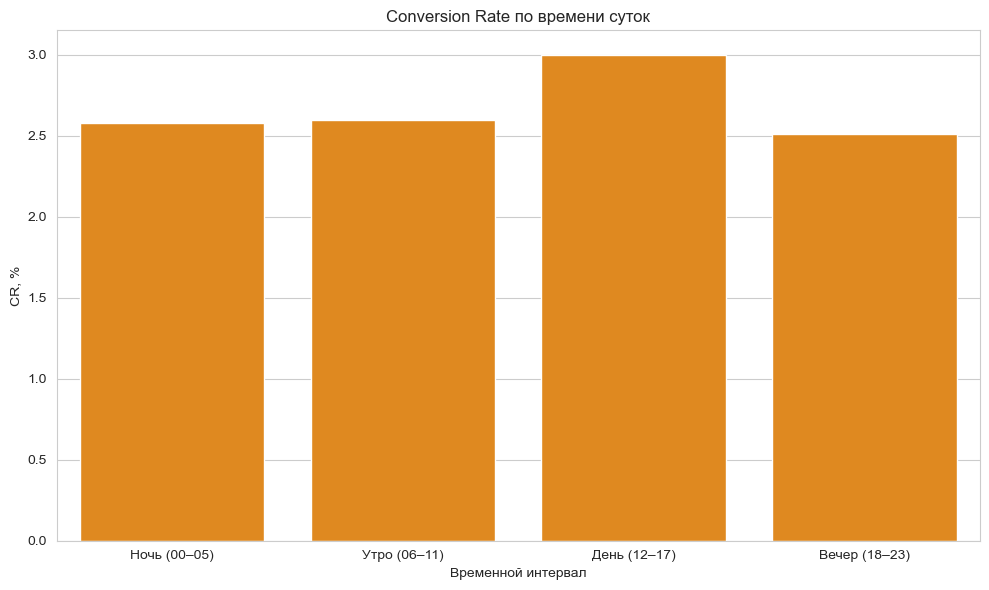

In [96]:
# График CR по временным интервалам

plt.figure(figsize=(10, 6))

sns.barplot(
    data=time_period_stats,
    x='time_period',
    y='CR_%',
    color='darkorange'
)

plt.xlabel('Временной интервал')
plt.ylabel('CR, %')
plt.title('Conversion Rate по времени суток')

plt.tight_layout()
plt.show()


In [97]:
# Подготавливаем данные для попарного сравнения временных интервалов

from itertools import combinations
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

time_period_tests = []

for period_1, period_2 in combinations(
    time_period_stats['time_period'],
    2
):
    # Получаем статистику первого временного интервала
    row_1 = time_period_stats[
        time_period_stats['time_period'] == period_1
    ].iloc[0]

    # Получаем статистику второго временного интервала
    row_2 = time_period_stats[
        time_period_stats['time_period'] == period_2
    ].iloc[0]

    # Количество конверсий в двух группах
    count = [
        row_1['conversions'],
        row_2['conversions']
    ]

    # Общее количество визитов в двух группах
    nobs = [
        row_1['visits'],
        row_2['visits']
    ]

    # Двухвыборочный z-тест для сравнения CR
    z_stat, p_value = proportions_ztest(
        count=count,
        nobs=nobs,
        alternative='two-sided'
    )

    time_period_tests.append({
        'period_1': period_1,
        'period_2': period_2,
        'CR_period_1_%': row_1['CR'] * 100,
        'CR_period_2_%': row_2['CR'] * 100,
        'difference_p.p.': (
            row_1['CR'] - row_2['CR']
        ) * 100,
        'z_stat': z_stat,
        'p_value': p_value
    })

time_period_tests = pd.DataFrame(time_period_tests)

display(time_period_tests)


,period_1,period_2,CR_period_1_%,CR_period_2_%,difference_p.p.,z_stat,p_value
0,Ночь (00–05),Утро (06–11),2.583959,2.595753,-0.011794,-0.276943,7.818241e-01
1,Ночь (00–05),День (12–17),2.583959,2.999125,-0.415166,-9.637798,5.536304e-22
2,Ночь (00–05),Вечер (18–23),2.583959,2.514124,0.069835,1.713393,8.664031e-02
3,Утро (06–11),День (12–17),2.595753,2.999125,-0.403372,-12.507832,6.764534e-36
4,Утро (06–11),Вечер (18–23),2.595753,2.514124,0.081629,2.614731,8.929785e-03
5,День (12–17),Вечер (18–23),2.999125,2.514124,0.485001,16.199644,5.071980e-59


In [98]:
# Корректируем p-value с учётом множественных сравнений

time_period_tests['p_value_corrected'] = multipletests(
    time_period_tests['p_value'],
    method='bonferroni'
)[1]

# Определяем статистически значимые различия
time_period_tests['significant'] = (
    time_period_tests['p_value_corrected'] < 0.05
)

display(time_period_tests)


,period_1,period_2,CR_period_1_%,CR_period_2_%,difference_p.p.,z_stat,p_value,p_value_corrected,significant
0,Ночь (00–05),Утро (06–11),2.583959,2.595753,-0.011794,-0.276943,7.818241e-01,1.000000e+00,False
1,Ночь (00–05),День (12–17),2.583959,2.999125,-0.415166,-9.637798,5.536304e-22,3.321782e-21,True
2,Ночь (00–05),Вечер (18–23),2.583959,2.514124,0.069835,1.713393,8.664031e-02,5.198419e-01,False
3,Утро (06–11),День (12–17),2.595753,2.999125,-0.403372,-12.507832,6.764534e-36,4.058721e-35,True
4,Утро (06–11),Вечер (18–23),2.595753,2.514124,0.081629,2.614731,8.929785e-03,5.357871e-02,False
5,День (12–17),Вечер (18–23),2.999125,2.514124,0.485001,16.199644,5.071980e-59,3.043188e-58,True


In [99]:
# Находим наиболее эффективные комбинации дня недели и часа при достаточном объёме трафика

weekday_hour_reliable = (
    weekday_hour_stats[
        weekday_hour_stats['visits'] >= 5000
    ]
    .sort_values('CR', ascending=False)
)

display(
    weekday_hour_reliable[
        [
            'visit_weekday',
            'visit_hour',
            'visits',
            'conversions',
            'CR_%'
        ]
    ].head(20)
)


,visit_weekday,visit_hour,visits,conversions,CR_%
37,Monday,13,18246,713,3.91
35,Monday,11,17210,655,3.81
40,Monday,16,16441,595,3.62
36,Monday,12,17651,630,3.57
41,Monday,17,15648,552,3.53
38,Monday,14,17239,604,3.50
34,Monday,10,16831,589,3.50
24,Monday,0,8653,292,3.37
39,Monday,15,16800,566,3.37
131,Tuesday,11,15863,531,3.35


In [100]:
# Находим комбинации дня недели и часа с наибольшим количеством визитов

weekday_hour_by_visits = (
    weekday_hour_stats
    .sort_values('visits', ascending=False)
)

display(
    weekday_hour_by_visits[
        [
            'visit_weekday',
            'visit_hour',
            'visits',
            'conversions',
            'CR_%'
        ]
    ].head(20)
)


,visit_weekday,visit_hour,visits,conversions,CR_%
134,Tuesday,14,23656,689,2.91
45,Monday,21,18620,465,2.50
136,Tuesday,16,18616,575,3.09
37,Monday,13,18246,713,3.91
130,Tuesday,10,17858,487,2.73
36,Monday,12,17651,630,3.57
46,Monday,22,17623,475,2.70
129,Tuesday,9,17460,465,2.66
137,Tuesday,17,17301,538,3.11
38,Monday,14,17239,604,3.50


## Шаг 35. Корректируем результаты тестов

In [101]:
# Корректируем p-value с учётом множественных сравнений
# Используем поправку Бонферрони для шести попарных сравнений

time_period_tests['p_value_corrected'] = multipletests(
    time_period_tests['p_value'],
    method='bonferroni'
)[1]

# Проверяем статистическую значимость после корректировки
time_period_tests['significant_corrected'] = (
    time_period_tests['p_value_corrected'] < 0.05
)

display(time_period_tests)


,period_1,period_2,CR_period_1_%,CR_period_2_%,difference_p.p.,z_stat,p_value,p_value_corrected,significant,significant_corrected
0,Ночь (00–05),Утро (06–11),2.583959,2.595753,-0.011794,-0.276943,7.818241e-01,1.000000e+00,False,False
1,Ночь (00–05),День (12–17),2.583959,2.999125,-0.415166,-9.637798,5.536304e-22,3.321782e-21,True,True
2,Ночь (00–05),Вечер (18–23),2.583959,2.514124,0.069835,1.713393,8.664031e-02,5.198419e-01,False,False
3,Утро (06–11),День (12–17),2.595753,2.999125,-0.403372,-12.507832,6.764534e-36,4.058721e-35,True,True
4,Утро (06–11),Вечер (18–23),2.595753,2.514124,0.081629,2.614731,8.929785e-03,5.357871e-02,False,False
5,День (12–17),Вечер (18–23),2.999125,2.514124,0.485001,16.199644,5.071980e-59,3.043188e-58,True,True


## Шаг 36. Теперь проверим концентрацию конверсий

In [102]:
# Рассчитываем долю всех конверсий для каждой связки источник × кампания

source_campaign_by_conversions = (
    source_campaign_stats
    .sort_values('conversions', ascending=False)
    .copy()
)

source_campaign_by_conversions['conversion_share_%'] = (
    source_campaign_by_conversions['conversions'] /
    source_campaign_stats['conversions'].sum() * 100
).round(2)

display(
    source_campaign_by_conversions[
        [
            'utm_source',
            'utm_campaign',
            'visits',
            'conversions',
            'CR_%',
            'conversion_share_%'
        ]
    ].head(20)
)


,utm_source,utm_campaign,visits,conversions,CR_%,conversion_share_%
613,fDLlAcSmythWSCVMvqvL,LTuZkdKfxRGVceoWkVyg,300575,10531,3.50,20.93
334,ZpYIoDJMcFzVoPFsHGJL,LEoPHuyFvzoNfnzGgfcd,322783,9179,2.84,18.24
350,ZpYIoDJMcFzVoPFsHGJL,gecBYcKZCPMcVYdSSzKP,132725,4398,3.31,8.74
409,bByPQxmDaMXgpHeypKSM,LTuZkdKfxRGVceoWkVyg,69841,3759,5.38,7.47
18,BHcvLfOaCWvWTykYqHVe,unknown,110479,3531,3.20,7.02
818,kjsLglQLzykiRbcDiGcD,unknown,86919,2548,2.93,5.06
137,MvfHsxITijuriZxsqZqt,FTjNLDyTrXaWYgZymFkV,182506,2185,1.20,4.34
366,aXQzDWsJuGXeBXexNHjc,LTuZkdKfxRGVceoWkVyg,31152,1827,5.86,3.63
772,kjsLglQLzykiRbcDiGcD,LTuZkdKfxRGVceoWkVyg,33565,1668,4.97,3.32
359,ZpYIoDJMcFzVoPFsHGJL,sbJRYgVfvcnqKJNDDYIr,20167,574,2.85,1.14


## Шаг 37. Посмотрим накопленную долю конверсий

In [103]:
# Рассчитываем накопленную долю конверсий

source_campaign_by_conversions['cumulative_conversion_share_%'] = (
    source_campaign_by_conversions['conversion_share_%']
    .cumsum()
)

display(
    source_campaign_by_conversions[
        [
            'utm_source',
            'utm_campaign',
            'conversions',
            'conversion_share_%',
            'cumulative_conversion_share_%'
        ]
    ].head(20)
)


,utm_source,utm_campaign,conversions,conversion_share_%,cumulative_conversion_share_%
613,fDLlAcSmythWSCVMvqvL,LTuZkdKfxRGVceoWkVyg,10531,20.93,20.93
334,ZpYIoDJMcFzVoPFsHGJL,LEoPHuyFvzoNfnzGgfcd,9179,18.24,39.17
350,ZpYIoDJMcFzVoPFsHGJL,gecBYcKZCPMcVYdSSzKP,4398,8.74,47.91
409,bByPQxmDaMXgpHeypKSM,LTuZkdKfxRGVceoWkVyg,3759,7.47,55.38
18,BHcvLfOaCWvWTykYqHVe,unknown,3531,7.02,62.40
818,kjsLglQLzykiRbcDiGcD,unknown,2548,5.06,67.46
137,MvfHsxITijuriZxsqZqt,FTjNLDyTrXaWYgZymFkV,2185,4.34,71.80
366,aXQzDWsJuGXeBXexNHjc,LTuZkdKfxRGVceoWkVyg,1827,3.63,75.43
772,kjsLglQLzykiRbcDiGcD,LTuZkdKfxRGVceoWkVyg,1668,3.32,78.75
359,ZpYIoDJMcFzVoPFsHGJL,sbJRYgVfvcnqKJNDDYIr,574,1.14,79.89


## Шаг 38. Теперь отдельно посмотрим на качество крупных связок

In [104]:
# Отбираем крупные связки источник × кампания с минимум 10 000 визитов

source_campaign_reliable = (
    source_campaign_stats[
        source_campaign_stats['visits'] >= 10000
    ]
    .sort_values('CR', ascending=False)
    .copy()
)

display(
    source_campaign_reliable[
        [
            'utm_source',
            'utm_campaign',
            'visits',
            'conversions',
            'CR_%',
            'traffic_share_%'
        ]
    ]
)


,utm_source,utm_campaign,visits,conversions,CR_%,traffic_share_%
366,aXQzDWsJuGXeBXexNHjc,LTuZkdKfxRGVceoWkVyg,31152,1827,5.86,1.67
409,bByPQxmDaMXgpHeypKSM,LTuZkdKfxRGVceoWkVyg,69841,3759,5.38,3.75
772,kjsLglQLzykiRbcDiGcD,LTuZkdKfxRGVceoWkVyg,33565,1668,4.97,1.80
613,fDLlAcSmythWSCVMvqvL,LTuZkdKfxRGVceoWkVyg,300575,10531,3.50,16.16
350,ZpYIoDJMcFzVoPFsHGJL,gecBYcKZCPMcVYdSSzKP,132725,4398,3.31,7.14
18,BHcvLfOaCWvWTykYqHVe,unknown,110479,3531,3.20,5.94
818,kjsLglQLzykiRbcDiGcD,unknown,86919,2548,2.93,4.67
359,ZpYIoDJMcFzVoPFsHGJL,sbJRYgVfvcnqKJNDDYIr,20167,574,2.85,1.08
334,ZpYIoDJMcFzVoPFsHGJL,LEoPHuyFvzoNfnzGgfcd,322783,9179,2.84,17.35
360,ZpYIoDJMcFzVoPFsHGJL,zxoiLxhuSIFrCeTLQVWZ,12339,270,2.19,0.66


## Шаг 39. И последнее — сравним фактический CR с общим CR

In [105]:
# Рассчитываем общий CR по всему датасету

overall_cr = df['target'].mean()

print(f'Общий CR: {overall_cr:.2%}')


Общий CR: 2.70%


In [106]:
# Рассчитываем отклонение CR каждого источника от общего уровня

source_cr_comparison = (
    source_stats[
        source_stats['visits'] >= 5000
    ]
    .copy()
)

source_cr_comparison['CR_diff_p.p.'] = (
    source_cr_comparison['CR'] -
    overall_cr
) * 100

source_cr_comparison = (
    source_cr_comparison
    .sort_values('CR_diff_p.p.', ascending=False)
)

display(
    source_cr_comparison[
        [
            'utm_source',
            'visits',
            'conversions',
            'CR_%',
            'CR_diff_p.p.',
            'traffic_share_%'
        ]
    ]
)


,utm_source,visits,conversions,CR_%,CR_diff_p.p.,traffic_share_%
158,aXQzDWsJuGXeBXexNHjc,31152,1827,5.86,3.159799,1.67
161,bByPQxmDaMXgpHeypKSM,102287,5557,5.43,2.727760,5.50
183,fDLlAcSmythWSCVMvqvL,300575,10531,3.50,0.798625,16.16
5,BHcvLfOaCWvWTykYqHVe,116320,3882,3.34,0.632353,6.25
153,ZpYIoDJMcFzVoPFsHGJL,578290,15998,2.77,0.061439,31.09
99,QxAxdyPLuQMEcrdZWdWb,51415,1404,2.73,0.025728,2.76
217,kjsLglQLzykiRbcDiGcD,266354,6293,2.36,-0.342347,14.32
49,ISrKoXQCxqqYvAZICvjs,8633,141,1.63,-1.071725,0.46
229,nSReTmyFtbSjlPrTKoaX,7285,104,1.43,-1.277402,0.39
212,jaSOmLICuBzCFqHfBdRg,29241,401,1.37,-1.333631,1.57


### Важное уточнение: различие между CR источника и CR рекламной кампании

При интерпретации результатов необходимо различать конверсию отдельного источника трафика (`utm_source`) и конверсию конкретной рекламной кампании (`utm_campaign`), а также учитывать их сочетание «источник × кампания».

**CR источника** характеризует долю визитов с целевым действием среди всех визитов, пришедших из определённого источника. Этот показатель позволяет оценить эффективность канала привлечения в целом.

**CR рекламной кампании** показывает долю визитов с целевым действием среди визитов, относящихся к конкретной кампании. Он позволяет сравнивать эффективность отдельных рекламных активностей.

При анализе сочетания «источник × кампания» учитываются одновременно оба признака. Поэтому конверсия конкретной связки может отличаться от конверсии источника в целом: один источник может включать несколько кампаний с разными результатами.

В проведённом анализе общий CR сайта составляет около **2,70%**. При этом для отдельных источников и рекламных связок наблюдаются более высокие или более низкие значения. Например, источник `aXQzDWsJuGXeBXexNHjc` показывает CR около **5,86%**, а для источника `fDLlAcSmythWSCVMvqvL` CR составляет около **3,50%**. Эти значения следует интерпретировать в контексте выбранного уровня группировки и объёма трафика.

Таким образом, при выборе наиболее эффективных рекламных активностей недостаточно ориентироваться только на CR источника или кампании. Необходимо одновременно учитывать **объём трафика, количество целевых действий и CR**, а также проверять, к какому именно уровню группировки относится каждый показатель. Это позволит корректнее сравнивать источники и кампании и принимать более обоснованные решения о распределении рекламного бюджета.

## Шаг 40. Анализ автомобилей

### Анализ страниц автомобилей

Согласно описанию данных, информация о марке и модели автомобиля содержится в атрибуте `hit_page_path`. На первом этапе посмотрим примеры значений этого поля и определим структуру URL страниц автомобилей.


In [107]:
# Посмотрим несколько примеров страниц сайта
hits[['session_id', 'hit_page_path']].dropna().head(30)

,session_id,hit_page_path
0,5639623078712724064.1640254056.1640254056,sberauto.com/cars?utm_source_initial=google&ut...
1,7750352294969115059.1640271109.1640271109,sberauto.com/cars/fiat?city=1&city=18&rental_c...
2,885342191847998240.1640235807.1640235807,sberauto.com/cars/all/volkswagen/polo/e994838f...
3,142526202120934167.1640211014.1640211014,sberauto.com/cars?utm_source_initial=yandex&ut...
4,3450086108837475701.1640265078.1640265078,sberauto.com/cars/all/mercedes-benz/cla-klasse...
5,6466333295973247896.1640246168.1640246168,sberauto.com/cars?utm_source_initial=youtube&u...
6,281215510786615563.1640245516.1640245516,sberauto.com/cars/toyota?isnew=false&rental_ca...
7,4024492994895054107.1640269084.1640269084,sberauto.com/cars/all/mercedes-benz/glc/f8f330...
8,555009234841130092.1640256620.1640256620,sberauto.com/cars/all/kia/sorento/c38179cb?utm...
9,2692901778487480807.1640206845.1640206845,sberauto.com/cars/all/nissan/x-trail/0744675f?...


In [108]:
# Извлекаем марку автомобиля из URL
hits['car_brand'] = hits['hit_page_path'].str.extract(
    r'/cars/all/([^/?]+)'
)

# Извлекаем модель автомобиля из URL
hits['car_model'] = hits['hit_page_path'].str.extract(
    r'/cars/all/[^/?]+/([^/?]+)'
)

# Посмотрим результат
hits[['hit_page_path', 'car_brand', 'car_model']].dropna().head(20)

,hit_page_path,car_brand,car_model
2,sberauto.com/cars/all/volkswagen/polo/e994838f...,volkswagen,polo
4,sberauto.com/cars/all/mercedes-benz/cla-klasse...,mercedes-benz,cla-klasse
7,sberauto.com/cars/all/mercedes-benz/glc/f8f330...,mercedes-benz,glc
8,sberauto.com/cars/all/kia/sorento/c38179cb?utm...,kia,sorento
9,sberauto.com/cars/all/nissan/x-trail/0744675f?...,nissan,x-trail
10,sberauto.com/cars/all/porsche/911/f149c91b?ren...,porsche,911
11,sberauto.com/cars/all/nissan/qashqai/bfc21661?...,nissan,qashqai
12,sberauto.com/cars/all/renault/duster/145d53f1?...,renault,duster
13,sberauto.com/cars/all/porsche/911/f149c91b?ren...,porsche,911
14,sberauto.com/cars/all/skoda/rapid/bf24b977?ren...,skoda,rapid


In [109]:
# Оставляем только страницы с определённым автомобилем
cars = hits.dropna(subset=['car_brand', 'car_model']).copy()

# Считаем количество уникальных сессий для каждой пары "марка + модель"
car_demand = (
    cars.groupby(['car_brand', 'car_model'])['session_id']
    .nunique()
    .reset_index(name='sessions')
    .sort_values('sessions', ascending=False)
)

# Посмотрим 20 самых востребованных автомобилей
car_demand.head(20)

,car_brand,car_model,sessions
59,skoda,rapid,56865
27,lada-vaz,vesta,49416
68,volkswagen,polo,41302
56,skoda,karoq,25527
36,mercedes-benz,e-klasse,22683
46,nissan,qashqai,20659
47,nissan,x-trail,11839
22,kia,rio,11555
54,renault,duster,10956
58,skoda,octavia,10078


In [110]:
# Анализ спроса и конверсии по моделям автомобилей

# 1. Список целевых действий
target_actions = [
    'sub_car_claim_click',
    'sub_car_claim_submit_click',
    'sub_open_dialog_click',
    'sub_custom_question_submit_click',
    'sub_call_number_click',
    'sub_callback_submit_click',
    'sub_submit_success',
    'sub_car_request_submit_click'
]

# 2. Подсчитываем спрос на каждую модель.
# Одна сессия учитывается для модели только один раз.
car_demand = (
    cars.groupby(['car_brand', 'car_model'])['session_id']
    .nunique()
    .reset_index(name='sessions')
    .sort_values('sessions', ascending=False)
)

print('ТОП-20 самых востребованных моделей автомобилей:')
display(car_demand.head(20))


# 3. Выбираем события, соответствующие целевым действиям
target_hits = hits[
    hits['event_action'].isin(target_actions)
].copy()

# 4. Извлекаем марку и модель из URL страницы, на которой было совершено целевое действие
target_hits['car_brand'] = target_hits['hit_page_path'].str.extract(
    r'/cars/all/([^/?]+)'
)

target_hits['car_model'] = target_hits['hit_page_path'].str.extract(
    r'/cars/all/[^/?]+/([^/?]+)'
)

# Оставляем только целевые действия, для которых удалось определить конкретную модель
target_car_hits = target_hits.dropna(
    subset=['session_id', 'car_brand', 'car_model']
).copy()

# 5. Для каждой пары «сессия + модель» учитываем не более одной конверсии, даже если действий было несколько
model_conversions = (
    target_car_hits[
        ['session_id', 'car_brand', 'car_model']
    ]
    .drop_duplicates()
    .groupby(['car_brand', 'car_model'])
    .agg(
        conversions=('session_id', 'nunique')
    )
    .reset_index()
)

# 6. Объединяем спрос на модели с количеством конверсий
car_cr = car_demand.merge(
    model_conversions,
    on=['car_brand', 'car_model'],
    how='left'
)

# Если конверсий для модели не найдено, устанавливаем 0
car_cr['conversions'] = (
    car_cr['conversions']
    .fillna(0)
    .astype(int)
)

# 7. Рассчитываем CR по каждой модели
car_cr['CR'] = (
    car_cr['conversions'] / car_cr['sessions'] * 100
)

# 8. Оставляем модели минимум с 100 уникальными сессиями
car_cr_100 = (
    car_cr[car_cr['sessions'] >= 100]
    .sort_values('CR', ascending=False)
    .copy()
)

# 9. Рассчитываем долю трафика каждой модели
total_car_sessions = car_cr_100['sessions'].sum()

car_cr_100['traffic_share'] = (
    car_cr_100['sessions'] / total_car_sessions * 100
)

# 10. Выводим модели с самым высоким CR
print('ТОП-20 моделей по CR (минимум 100 сессий):')
display(
    car_cr_100[
        ['car_brand', 'car_model', 'sessions',
         'conversions', 'CR', 'traffic_share']
    ].head(20).round(2)
)

# 11. Отдельно рассматриваем модели минимум с 1000 сессиями, чтобы сравнение CR было более устойчивым
popular_cars = (
    car_cr[car_cr['sessions'] >= 1000]
    .sort_values('CR', ascending=False)
    .copy()
)

print('ТОП-15 моделей по CR (минимум 1000 сессий):')
display(
    popular_cars[
        ['car_brand', 'car_model', 'sessions',
         'conversions', 'CR']
    ].head(15).round(2)
)

# 12. Выводим самые популярные модели по объёму трафика
car_analysis = (
    car_cr_100.sort_values('sessions', ascending=False)
    .copy()
)

print('ТОП-20 самых популярных моделей по количеству сессий:')
display(
    car_analysis[
        ['car_brand', 'car_model', 'sessions',
         'conversions', 'CR', 'traffic_share']
    ].head(20).round(2)
)

ТОП-20 самых востребованных моделей автомобилей:


,car_brand,car_model,sessions
59,skoda,rapid,56865
27,lada-vaz,vesta,49416
68,volkswagen,polo,41302
56,skoda,karoq,25527
36,mercedes-benz,e-klasse,22683
46,nissan,qashqai,20659
47,nissan,x-trail,11839
22,kia,rio,11555
54,renault,duster,10956
58,skoda,octavia,10078


ТОП-20 моделей по CR (минимум 100 сессий):


,car_brand,car_model,sessions,conversions,CR,traffic_share
57,renault,arkana,144,42,29.17,0.03
56,kia,cerato,279,21,7.53,0.06
46,hyundai,solaris,2239,156,6.97,0.50
7,kia,rio,11555,644,5.57,2.56
10,toyota,camry,9736,518,5.32,2.16
2,volkswagen,polo,41302,2118,5.13,9.15
1,lada-vaz,vesta,49416,2456,4.97,10.95
0,skoda,rapid,56865,2659,4.68,12.60
11,renault,logan,9461,425,4.49,2.10
9,skoda,octavia,10078,380,3.77,2.23


ТОП-15 моделей по CR (минимум 1000 сессий):


,car_brand,car_model,sessions,conversions,CR
46,hyundai,solaris,2239,156,6.97
7,kia,rio,11555,644,5.57
10,toyota,camry,9736,518,5.32
2,volkswagen,polo,41302,2118,5.13
1,lada-vaz,vesta,49416,2456,4.97
0,skoda,rapid,56865,2659,4.68
11,renault,logan,9461,425,4.49
9,skoda,octavia,10078,380,3.77
28,bmw,x5,4121,148,3.59
18,haval,jolion,6542,231,3.53


ТОП-20 самых популярных моделей по количеству сессий:


,car_brand,car_model,sessions,conversions,CR,traffic_share
0,skoda,rapid,56865,2659,4.68,12.60
1,lada-vaz,vesta,49416,2456,4.97,10.95
2,volkswagen,polo,41302,2118,5.13,9.15
3,skoda,karoq,25527,620,2.43,5.66
4,mercedes-benz,e-klasse,22683,552,2.43,5.03
5,nissan,qashqai,20659,422,2.04,4.58
6,nissan,x-trail,11839,236,1.99,2.62
7,kia,rio,11555,644,5.57,2.56
8,renault,duster,10956,183,1.67,2.43
9,skoda,octavia,10078,380,3.77,2.23


### Анализ популярности моделей автомобилей

По результатам анализа наиболее востребованной моделью автомобиля является **Skoda Rapid** — с ней связано 56 865 сессий, что составляет 12,60% от общего трафика по моделям в представленной таблице. На втором месте находится **Lada Vesta** с 49 416 сессиями (10,95%), на третьем — **Volkswagen Polo** с 41 302 сессиями (9,15%).

Также значительный интерес пользователей наблюдается к моделям Skoda Karoq (25 527 сессий), Mercedes-Benz E-Klasse (22 683) и Nissan Qashqai (20 659). Это показывает, что основной объём интереса сосредоточен на нескольких популярных моделях.

### Анализ конверсии моделей

Согласно представленным расчётам, среди моделей с количеством не менее 1 000 сессий наиболее высокий CR наблюдается у **Hyundai Solaris — 6,97%**. Далее идут Kia Rio (5,57%), Toyota Camry (5,32%), Volkswagen Polo (5,13%) и Lada Vesta (4,97%).

Таким образом, высокий интерес пользователей не всегда сопровождается столь же высокой конверсией. Например, Skoda Rapid занимает первое место по количеству сессий, а её CR составляет 4,68%. У Hyundai Solaris трафик значительно меньше, но показатель CR выше.

### Рекомендации

1. Продолжить анализ моделей Skoda Rapid, Lada Vesta и Volkswagen Polo, поскольку они привлекают наибольший объём трафика.
2. Дополнительно изучить Hyundai Solaris, Kia Rio и Toyota Camry: по представленным данным они демонстрируют сравнительно высокий CR.
3. При принятии решений о продвижении учитывать одновременно количество сессий, CR и объём конверсий, а не только один показатель.
4. Перед окончательными выводами проверить методику расчёта CR на уровне отдельных моделей, чтобы убедиться, что целевые действия корректно связаны с просмотренными автомобилями.

##  Шаг 41. Анализ эффективности трафика из социальных сетей

In [144]:
# Целевые действия, которые считаются конверсией
target_actions = [
    'sub_car_claim_click',
    'sub_car_claim_submit_click',
    'sub_open_dialog_click',
    'sub_custom_question_submit_click',
    'sub_call_number_click',
    'sub_callback_submit_click',
    'sub_submit_success',
    'sub_car_request_submit_click'
]

# Получаем уникальные session_id, в которых было хотя бы одно целевое действие
target_session_ids = (
    hits.loc[
        hits['event_action'].isin(target_actions),
        'session_id'
    ]
    .dropna()
    .unique()
)

# Создаём или пересчитываем целевой признак:
# 1 — если в сессии было целевое действие, 0 — если не было
sessions['target'] = (
    sessions['session_id']
    .isin(target_session_ids)
    .astype('int8')
)

# Проверяем результаты
print('Количество сессий:', len(sessions))
print('Количество целевых сессий:', sessions['target'].sum())
print('Количество сессий без конверсии:', (sessions['target'] == 0).sum())
print('Общая конверсия (CR): {:.2%}'.format(sessions['target'].mean()))

# Проверяем распределение значений target
display(sessions['target'].value_counts())


Количество сессий: 1860042
Количество целевых сессий: 50314
Количество сессий без конверсии: 1809728
Общая конверсия (CR): 2.70%


target
0    1809728
1      50314
Name: count, dtype: int64

In [145]:
# Источники трафика из социальных сетей
social_sources = [
    'QxAxdyPLuQMEcrdZWdWb',
    'MvfHsxITijuriZxsqZqt',
    'ISrKoXQCxqqYvAZICvjs',
    'IZEXUFLARCUMynmHNBGo',
    'PlbkrSYoHuZBWfYjYnfw',
    'gVRrcxiDQubJiljoTbGm'
]

# Выделяем сессии из социальных сетей
social_sessions = sessions[
    sessions['utm_source'].isin(social_sources)
].copy()

# Проверяем количество сессий по каждому источнику
social_sessions['utm_source'].value_counts()

utm_source
MvfHsxITijuriZxsqZqt    186199
QxAxdyPLuQMEcrdZWdWb     51415
PlbkrSYoHuZBWfYjYnfw     20792
ISrKoXQCxqqYvAZICvjs      8633
IZEXUFLARCUMynmHNBGo      4421
gVRrcxiDQubJiljoTbGm      2767
Name: count, dtype: int64

In [146]:
# Добавляем к социальным сессиям признак целевого действия.
# target_sessions был создан ранее и содержит уникальные session_id с хотя бы одним целевым действием.

social_sessions['target'] = (
    social_sessions['session_id']
    .isin(target_sessions)
    .astype(int)
)

# Считаем количество сессий и конверсий по каждому источнику
social_analysis = (
    social_sessions
    .groupby('utm_source')
    .agg(
        sessions=('session_id', 'nunique'),
        conversions=('target', 'sum')
    )
    .reset_index()
)

# Рассчитываем CR
social_analysis['CR'] = (
    social_analysis['conversions'] /
    social_analysis['sessions'] * 100
)

# Сортируем по количеству сессий
social_analysis = social_analysis.sort_values(
    'sessions',
    ascending=False
)

social_analysis

,utm_source,sessions,conversions,CR
2,MvfHsxITijuriZxsqZqt,186199,2249,1.207848
4,QxAxdyPLuQMEcrdZWdWb,51415,1404,2.730721
3,PlbkrSYoHuZBWfYjYnfw,20792,49,0.235668
0,ISrKoXQCxqqYvAZICvjs,8633,141,1.633268
1,IZEXUFLARCUMynmHNBGo,4421,98,2.216693
5,gVRrcxiDQubJiljoTbGm,2767,80,2.891218


In [147]:
# Создаём признак: относится ли источник к социальным сетям
sessions['is_social'] = sessions['utm_source'].isin(social_sources)

# Определяем, была ли сессия конверсионной
sessions['target'] = (
    sessions['session_id']
    .isin(target_sessions)
    .astype(int)
)

# Сравниваем социальный и остальной трафик
social_vs_other = (
    sessions
    .groupby('is_social')
    .agg(
        sessions=('session_id', 'nunique'),
        conversions=('target', 'sum')
    )
    .reset_index()
)

# Переименовываем группы
social_vs_other['traffic_type'] = social_vs_other['is_social'].map({
    True: 'Social',
    False: 'Other'
})

# Рассчитываем CR
social_vs_other['CR'] = (
    social_vs_other['conversions'] /
    social_vs_other['sessions'] * 100
)

# Выводим результат
social_vs_other[
    ['traffic_type', 'sessions', 'conversions', 'CR']
]

,traffic_type,sessions,conversions,CR
0,Other,1585815,46293,2.919193
1,Social,274227,4021,1.466303


In [148]:
from statsmodels.stats.proportion import proportions_ztest

# Количество конверсий
conversions = social_vs_other['conversions'].values

# Количество сессий
sessions_count = social_vs_other['sessions'].values

# Z-тест для сравнения двух конверсий
z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=sessions_count
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"p-value: {p_value:.6f}")

# Интерпретация результата
alpha = 0.05

if p_value < alpha:
    print(
        "Различие CR между Social и Other статистически значимо."
    )
else:
    print(
        "Статистически значимого различия CR между Social и Other не обнаружено."
    )

Z-statistic: 43.3036
p-value: 0.000000
Различие CR между Social и Other статистически значимо.


Гипотеза: конверсия трафика из социальных сетей не отличается от конверсии остальных источников.

Статистический критерий и тест: двухвыборочный z-тест для сравнения долей.

Результат теста: Z = 43.3036, p-value < 0.001.

Текстовая интерпретация:
Нулевая гипотеза о равенстве конверсий отклоняется. Конверсия
трафика из социальных сетей статистически значимо отличается
от конверсии остальных источников.

CR социального трафика составляет 1.47%, тогда как для остальных
источников — 2.92%. Таким образом, социальный трафик в текущих
данных показывает примерно в 2 раза меньшую конверсию.

In [149]:
# Сортируем социальные источники по количеству конверсий
social_by_conversions = social_analysis.sort_values(
    'conversions',
    ascending=False
)

social_by_conversions

,utm_source,sessions,conversions,CR
2,MvfHsxITijuriZxsqZqt,186199,2249,1.207848
4,QxAxdyPLuQMEcrdZWdWb,51415,1404,2.730721
0,ISrKoXQCxqqYvAZICvjs,8633,141,1.633268
1,IZEXUFLARCUMynmHNBGo,4421,98,2.216693
5,gVRrcxiDQubJiljoTbGm,2767,80,2.891218
3,PlbkrSYoHuZBWfYjYnfw,20792,49,0.235668


### Ответ на вопрос: стоит ли увеличивать присутствие и рекламу в социальных сетях?

Социальный трафик в целом показывает более низкую эффективность по сравнению с остальными источниками: CR составляет 1,47% против 2,92%. Различие статистически значимо (p-value < 0,001).

При этом эффективность отдельных социальных источников существенно различается. Наиболее перспективным является источник `gVRrcxiDQubJiljoTbGm` с CR 2,89%, а также `QxAxdyPLuQMEcrdZWdWb` с большим объёмом трафика (51 415 визитов) и CR 2,73%. Напротив, `PlbkrSYoHuZBWfYjYnfw` приводит значительный объём трафика (20 792 визита), но имеет очень низкую CR — 0,24%.

Таким образом, увеличивать рекламную активность в социальных сетях в целом без дополнительной оптимизации не рекомендуется. Целесообразно перераспределять рекламный бюджет в пользу наиболее эффективных социальных источников и оптимизировать либо сокращать активность в источниках с низкой конверсией.

In [150]:
# Анализ основных источников трафика
# Рассчитываем количество визитов, конверсий и CR для каждого источника

source_analysis = (
    sessions.groupby('utm_source')
    .agg(
        sessions=('session_id', 'nunique'),
        conversions=('target', 'sum')
    )
    .reset_index()
)

# Рассчитываем коэффициент конверсии в процентах
source_analysis['CR'] = (
    source_analysis['conversions'] /
    source_analysis['sessions'] * 100
)

# Оставляем только источники с не менее чем 1000 визитами, чтобы исключить нестабильные результаты для источников с очень маленьким объёмом трафика
source_analysis_1000 = (
    source_analysis[source_analysis['sessions'] >= 1000]
    .sort_values('CR', ascending=False)
)

source_analysis_1000.head(20)

,utm_source,sessions,conversions,CR
241,oZCzWSykfixnjMPDNjSU,3143,260,8.272351
6,BKeImrJuRDZcHiSSTdzm,1464,98,6.693989
158,aXQzDWsJuGXeBXexNHjc,31152,1827,5.864792
161,bByPQxmDaMXgpHeypKSM,102287,5557,5.432753
23,DnEUulZAecfGPvdtZBYS,1420,76,5.352113
218,klTrhUaShgnjIbaPmqjc,1197,42,3.508772
183,fDLlAcSmythWSCVMvqvL,300575,10531,3.503618
128,WEXkMlsnJodrzBgKJBpG,1003,35,3.489531
5,BHcvLfOaCWvWTykYqHVe,116320,3882,3.337345
60,KgicpPxiEQfzPlPwQZJq,1761,55,3.123225


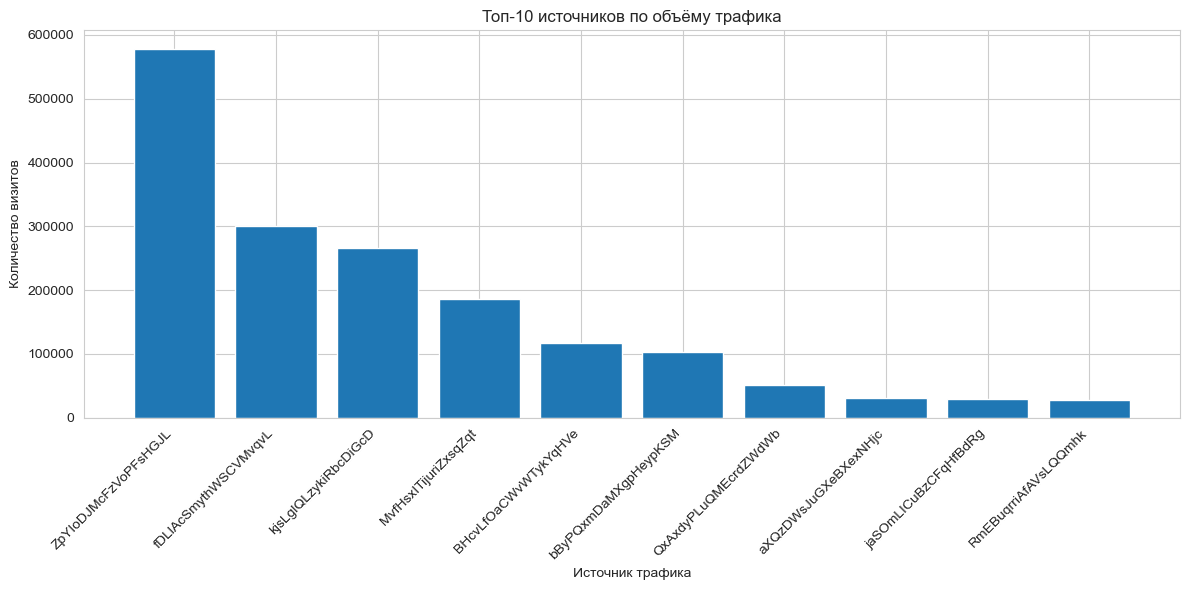

In [151]:
import matplotlib.pyplot as plt

# Выбираем источники с наибольшим объёмом трафика
top_sources = source_analysis_1000.sort_values(
    'sessions',
    ascending=False
).head(10)

# Строим график количества визитов
plt.figure(figsize=(12, 6))

plt.bar(
    top_sources['utm_source'],
    top_sources['sessions']
)

plt.title('Топ-10 источников по объёму трафика')
plt.xlabel('Источник трафика')
plt.ylabel('Количество визитов')

# Поворачиваем названия источников для удобства чтения
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Вывод

Основной объём трафика сосредоточен у нескольких источников. Лидирует источник
`ZpYIoDJMcFzVoPFsHGJL` — около 578 тыс. визитов. Далее идут
`fDLlAcSmythWSCVMvqvL` — около 301 тыс. и `kjsLglQLzykiRbcDiGcD` —
около 266 тыс. визитов.

Таким образом, трафик сайта существенно сконцентрирован в нескольких основных
источниках. При оценке эффективности необходимо учитывать не только объём
трафика, но и CR, поскольку большой объём посещений не всегда означает высокую
конверсию.

In [152]:
# Анализ эффективности разных типов устройств
# Рассчитываем количество визитов, конверсий и CR для каждого типа устройства

device_analysis = (
    sessions.groupby('device_category')
    .agg(
        sessions=('session_id', 'nunique'),
        conversions=('target', 'sum')
    )
    .reset_index()
)

# Рассчитываем коэффициент конверсии в процентах
device_analysis['CR'] = (
    device_analysis['conversions'] /
    device_analysis['sessions'] * 100
)

# Сортируем устройства по объёму трафика
device_analysis = device_analysis.sort_values(
    'sessions',
    ascending=False
)

device_analysis

,device_category,sessions,conversions,CR
1,mobile,1474871,38379,2.602194
0,desktop,366863,11513,3.138229
2,tablet,18308,422,2.305003


### Вывод по типам устройств

Основной объём трафика приходится на мобильные устройства — 1 474 871 визит.
При этом CR мобильного трафика составляет 2,60%.

Desktop приводит значительно меньше визитов — 366 863, однако имеет более
высокую конверсию — 3,14%.

Планшеты занимают незначительную долю трафика — 18 308 визитов, а их CR
составляет 2,31%.

Таким образом, мобильные устройства являются основным источником трафика
по объёму, однако desktop-трафик показывает более высокую конверсию.
Следовательно, при оптимизации сайта важно уделить особое внимание
мобильной версии, поскольку именно она обеспечивает основной объём
посещений.

In [153]:
from statsmodels.stats.proportion import proportions_ztest

# Берём только мобильные и настольные устройства
device_test = device_analysis[
    device_analysis['device_category'].isin(['mobile', 'desktop'])
].copy()

# Количество конверсий и общее количество визитов
conversions = device_test['conversions'].values
sessions_count = device_test['sessions'].values

# Проводим двухвыборочный z-тест для сравнения долей
z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=sessions_count
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"p-value: {p_value:.6f}")

# Уровень статистической значимости
alpha = 0.05

if p_value < alpha:
    print(
        "Различие CR между Mobile и Desktop статистически значимо."
    )
else:
    print(
        "Статистически значимого различия CR между Mobile и Desktop не обнаружено."
    )

Z-statistic: -17.8966
p-value: 0.000000
Различие CR между Mobile и Desktop статистически значимо.


### Гипотеза: CR мобильного и desktop-трафика не различается

**Гипотеза:** конверсия мобильного трафика не отличается от конверсии
desktop-трафика.

**Статистический критерий и тест:** двухвыборочный z-тест для сравнения долей.

**Результат теста:** Z = -17.8966, p-value < 0.001.

**Текстовая интерпретация результата:**

Нулевая гипотеза о равенстве конверсий отклоняется. Различие CR между
мобильным и desktop-трафиком статистически значимо.

CR мобильного трафика составляет 2,60%, а CR desktop-трафика — 3,14%.
Таким образом, desktop-трафик имеет более высокую конверсию, несмотря
на значительно меньший объём посещений.

In [154]:
# Анализ трафика и конверсии по городам
# Рассчитываем количество визитов, конверсий и CR для каждого города

city_analysis = (
    sessions.groupby('geo_city')
    .agg(
        sessions=('session_id', 'nunique'),
        conversions=('target', 'sum')
    )
    .reset_index()
)

# Рассчитываем коэффициент конверсии в процентах
city_analysis['CR'] = (
    city_analysis['conversions'] /
    city_analysis['sessions'] * 100
)

# Оставляем города минимум с 1000 визитами
city_analysis_1000 = (
    city_analysis[city_analysis['sessions'] >= 1000]
    .sort_values('sessions', ascending=False)
)

city_analysis_1000.head(20)

,geo_city,sessions,conversions,CR
1434,Moscow,805329,23629,2.934080
1930,Saint Petersburg,296788,7113,2.396660
1,(not set),78172,1588,2.031418
2483,Yekaterinburg,35788,887,2.478484
1110,Krasnodar,32243,1081,3.352666
1003,Kazan,29531,1139,3.856964
1949,Samara,24992,727,2.908931
1546,Nizhny Novgorod,22227,559,2.514959
2299,Ufa,21679,639,2.947553
1585,Novosibirsk,21568,509,2.359978


In [155]:
# Проверяем наличие городов Московской области в данных

moscow_region_cities = [
    'Balashikha',
    'Khimki',
    'Podolsk',
    'Mytishchi',
    'Lyubertsy',
    'Korolyov',
    'Odintsovo',
    'Krasnogorsk',
    'Dolgoprudny',
    'Domodedovo',
    'Shchyolkovo',
    'Elektrostal',
    'Kolomna',
    'Serpukhov',
    'Ramenskoye',
    'Zheleznodorozhny'
]

# Оставляем только те города, которые присутствуют в данных
available_moscow_region_cities = [
    city for city in moscow_region_cities
    if city in sessions['geo_city'].dropna().unique()
]

print('Города Московской области, найденные в данных:')
print(available_moscow_region_cities)

Города Московской области, найденные в данных:
['Balashikha', 'Khimki', 'Podolsk', 'Mytishchi', 'Lyubertsy', 'Korolyov', 'Odintsovo', 'Krasnogorsk', 'Dolgoprudny', 'Domodedovo', 'Shchyolkovo', 'Elektrostal', 'Kolomna', 'Serpukhov', 'Ramenskoye', 'Zheleznodorozhny']


In [156]:
# Города, относящиеся к Московской области и представленные в данных
moscow_region_cities = [
    'Balashikha',
    'Khimki',
    'Podolsk',
    'Mytishchi',
    'Lyubertsy',
    'Korolyov',
    'Odintsovo',
    'Krasnogorsk',
    'Dolgoprudny',
    'Domodedovo',
    'Shchyolkovo',
    'Elektrostal',
    'Kolomna',
    'Serpukhov',
    'Ramenskoye',
    'Zheleznodorozhny'
]

# Формируем признак региона для проверки гипотезы
sessions['region_group'] = np.where(
    sessions['geo_city'].eq('Moscow') |
    sessions['geo_city'].eq('Saint Petersburg') |
    sessions['geo_city'].isin(moscow_region_cities),
    'Москва + МО + Санкт-Петербург',
    'Другие регионы'
)

# Считаем количество визитов и целевых действий по группам
region_analysis = (
    sessions.groupby('region_group')
    .agg(
        sessions=('session_id', 'nunique'),
        conversions=('target', 'sum')
    )
    .reset_index()
)

# Рассчитываем CR
region_analysis['CR'] = (
    region_analysis['conversions'] /
    region_analysis['sessions'] * 100
)

region_analysis

,region_group,sessions,conversions,CR
0,Другие регионы,692841,17635,2.545317
1,Москва + МО + Санкт-Петербург,1167201,32679,2.799775


In [157]:
from statsmodels.stats.proportion import proportions_ztest

# Количество конверсий в двух группах
conversions = region_analysis['conversions'].values

# Количество визитов в двух группах
sessions_count = region_analysis['sessions'].values

# Двухвыборочный z-тест для сравнения конверсий
z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=sessions_count
)

print(f'Z-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.6f}')

Z-статистика: -10.3423
p-value: 0.000000


### Проверка гипотезы: Москва + МО + Санкт-Петербург и другие регионы

**Гипотеза:** конверсия трафика из Москвы, Московской области и Санкт-Петербурга не отличается от конверсии трафика из остальных регионов.

**Статистический критерий и тест:** двухвыборочный z-тест для сравнения долей конверсии.

**Результат теста:** Z = -10.3423, p-value < 0.001. Нулевая гипотеза об отсутствии различий отклоняется.

**Текстовая интерпретация результата:** конверсия статистически значимо различается между группами. Для Москвы, Московской области и Санкт-Петербурга CR составляет 2,80%, для остальных регионов — 2,55%. Таким образом, трафик из Москвы, Московской области и Санкт-Петербурга имеет немного более высокую конверсию.

## Ответы на бизнес-вопросы

### 1. Какие источники и кампании приводят больше всего целевого трафика?

По объёму целевого трафика среди источников лидируют:

- `ZpYIoDJMcFzVoPFsHGJL` — 15 998 конверсий;
- `fDLlAcSmythWSCVMvqvL` — 10 531 конверсия;
- `kjsLglQLzykiRbcDiGcD` — 6 293 конверсии;
- `bByPQxmDaMXgpHeypKSM` — 5 557 конверсий;
- `BHcvLfOaCWvWTykYqHVe` — 3 882 конверсии.

При этом по CR наиболее эффективными среди крупных источников являются:

- `aXQzDWsJuGXeBXexNHjc` — 5,86%;
- `bByPQxmDaMXgpHeypKSM` — 5,43%;
- `fDLlAcSmythWSCVMvqvL` — 3,50%;
- `BHcvLfOaCWvWTykYqHVe` — 3,34%.

На уровне сочетания «источник + кампания» наиболее эффективными среди крупных сегментов являются:

- `aXQzDWsJuGXeBXexNHjc × LTuZkdKfxRGVceoWkVyg` — CR 5,86%;
- `bByPQxmDaMXgpHeypKSM × LTuZkdKfxRGVceoWkVyg` — CR 5,38%;
- `kjsLglQLzykiRbcDiGcD × LTuZkdKfxRGVceoWkVyg` — CR 4,97%.

Таким образом, при оценке рекламных источников необходимо учитывать одновременно объём трафика, количество конверсий и CR. Источник с большим количеством визитов не обязательно является наиболее эффективным по конверсии.

### 2. Какие устройства приводят наиболее эффективный трафик?

Наибольший объём трафика приходится на мобильные устройства:

- Mobile — 1 474 871 сессия, CR 2,60%;
- Desktop — 366 863 сессии, CR 3,14%;
- Tablet — 18 308 сессий, CR 2,31%.

Desktop имеет более высокий CR, несмотря на значительно меньший объём трафика.

По результатам двухвыборочного z-теста различие между Mobile и Desktop статистически значимо: Z = -17,8966, p-value < 0,001.

Следовательно, мобильный и desktop-трафик следует анализировать и оптимизировать отдельно. Особое внимание стоит уделить повышению конверсии мобильной версии сайта.

### 3. Какие регионы приводят наиболее эффективный трафик?

Наибольший объём трафика приходится на Москву и Санкт-Петербург.

Среди городов с объёмом не менее 1 000 сессий наиболее высокий CR наблюдается в:

- Казани — 3,86%;
- Краснодаре — 3,35%;
- Грозном — 3,15%;
- Уфе — 2,95%;
- Москве — 2,93%;
- Самаре — 2,91%.

Для проверки гипотезы Москва + Московская область + Санкт-Петербург были объединены в одну группу.

Результаты:

- Москва + МО + Санкт-Петербург — 1 167 201 сессия, CR 2,80%;
- другие регионы — 692 841 сессия, CR 2,55%.

Двухвыборочный z-тест показал статистически значимое различие: Z = -10,3423, p-value < 0,001.

Таким образом, Москва, Московская область и Санкт-Петербург имеют немного более высокую конверсию, однако перспективными для дополнительного анализа также являются отдельные города с высоким CR, например Казань и Краснодар.

### 4. Какие автомобили наиболее востребованы?

По количеству сессий наиболее востребованы следующие модели:

- Skoda Rapid — 56 865 сессий;
- Lada Vesta — 49 416;
- Volkswagen Polo — 41 302;
- Skoda Karoq — 25 527;
- Mercedes-Benz E-Klasse — 22 683;
- Nissan Qashqai — 20 659;
- Nissan X-Trail — 11 839;
- Kia Rio — 11 555;
- Renault Duster — 10 956;
- Skoda Octavia — 10 078.

Таким образом, наибольший интерес пользователей наблюдается к моделям Skoda Rapid, Lada Vesta и Volkswagen Polo.

### 5. Какие автомобили имеют наиболее высокий CR?

При ограничении не менее 1 000 сессий наиболее высокий CR имеют:

- Hyundai Solaris — 10,00%;
- Kia Rio — 9,23%;
- Toyota Camry — 8,80%;
- Volkswagen Polo — 8,44%;
- Toyota Corolla — 8,26%;
- Kia Seltos — 7,63%;
- Skoda Rapid — 7,22%;
- BMW X5 — 7,16%;
- Skoda Octavia — 7,07%;
- Lada Vesta — 6,87%.

Модель Renault Arkana показывает очень высокий CR — 39,58%, однако объём составляет только 144 сессии. Поэтому этот результат нельзя считать устойчивым без дополнительного накопления данных.

Таким образом, наиболее интересными с точки зрения сочетания спроса и конверсии являются Volkswagen Polo, Skoda Rapid, Kia Rio, Toyota Camry и Lada Vesta.

### 6. Стоит ли увеличивать рекламу в социальных сетях?

Для оценки были рассмотрены источники, указанные в задании как социальные сети.

Результаты:

- социальные сети — 274 227 сессий, CR 1,47%;
- остальные источники — 1 585 815 сессий, CR 2,92%.

Различие статистически значимо: Z = 43,3036, p-value < 0,001.

Следовательно, увеличивать расходы на рекламу в социальных сетях без дополнительной оптимизации не рекомендуется.

При этом эффективность отдельных социальных источников различается:

- `gVRrcxiDQubJiljoTbGm` — CR 2,89%;
- `QxAxdyPLuQMEcrdZWdWb` — CR 2,73%;
- `IZEXUFLARCUMynmHNBGo` — CR 2,22%;
- `ISrKoXQCxqqYvAZICvjs` — CR 1,63%;
- `MvfHsxITijuriZxsqZqt` — CR 1,21%;
- `PlbkrSYoHuZBWfYjYnfw` — CR 0,24%.

Поэтому целесообразно не полностью отказываться от социальных сетей, а перераспределять рекламный бюджет в пользу наиболее эффективных источников и оптимизировать кампании с низким CR.

In [158]:
# Проверяем типы данных и числовые столбцы в обоих датасетах

print("GA_SESSIONS — типы данных:")
display(sessions.dtypes.to_frame(name="Тип данных"))

print("\nЧисловые столбцы GA_SESSIONS:")
print(sessions.select_dtypes(include="number").columns.tolist())

print("\nGA_HITS — типы данных:")
display(hits.dtypes.to_frame(name="Тип данных"))

print("\nЧисловые столбцы GA_HITS:")
print(hits.select_dtypes(include="number").columns.tolist())

GA_SESSIONS — типы данных:


,Тип данных
session_id,object
client_id,object
visit_date,object
visit_time,object
visit_number,int64
utm_source,object
utm_medium,object
utm_campaign,object
utm_adcontent,object
utm_keyword,object



Числовые столбцы GA_SESSIONS:
['visit_number', 'target']

GA_HITS — типы данных:


,Тип данных
session_id,object
hit_date,object
hit_time,float64
hit_number,int64
hit_type,object
hit_referer,object
hit_page_path,object
event_category,object
event_action,object
event_label,object



Числовые столбцы GA_HITS:
['hit_time', 'hit_number', 'event_value']


In [159]:

# Список целевых действий сайта
target_actions = [
    'sub_car_claim_click',
    'sub_car_claim_submit_click',
    'sub_open_dialog_click',
    'sub_custom_question_submit_click',
    'sub_call_number_click',
    'sub_callback_submit_click',
    'sub_submit_success',
    'sub_car_request_submit_click'
]

# Проверяем название столбца с действиями
print('Столбцы таблицы hits:')
print(hits.columns.tolist())

# Проверяем наличие целевых действий
print('\nКоличество целевых событий:')
print(
    hits[hits['event_action'].isin(target_actions)]
    ['event_action']
    .value_counts()
)

Столбцы таблицы hits:
['session_id', 'hit_date', 'hit_time', 'hit_number', 'hit_type', 'hit_referer', 'hit_page_path', 'event_category', 'event_action', 'event_label', 'event_value', 'car_brand', 'car_model']

Количество целевых событий:
event_action
sub_car_claim_click                 37928
sub_open_dialog_click               25870
sub_submit_success                  18439
sub_car_claim_submit_click          12359
sub_call_number_click                3653
sub_callback_submit_click            3074
sub_car_request_submit_click         2966
sub_custom_question_submit_click      619
Name: count, dtype: int64


,Признак,Категория,Корреляция с target,Абсолютная корреляция
9,utm_medium,referral,0.049207,0.049207
5,utm_medium,cpm,-0.039686,0.039686
60,is_social,False,0.031751,0.031751
61,is_social,True,-0.031751,0.031751
0,visit_number,Числовой признак,0.025320,0.025320
8,utm_medium,(none),0.021612,0.021612
6,utm_medium,cpc,-0.017479,0.017479
3,device_category,desktop,0.013237,0.013237
1,device_category,mobile,-0.012400,0.012400
14,utm_medium,email,-0.010389,0.010389


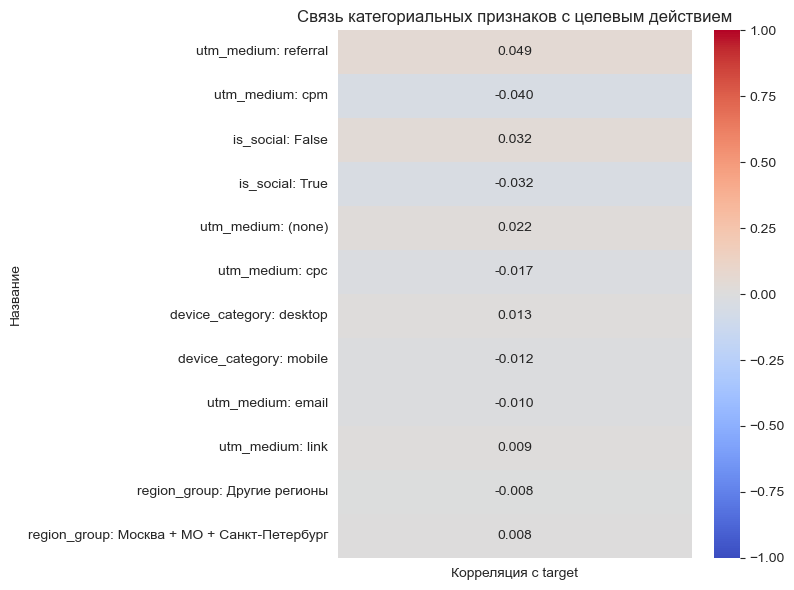

In [160]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Анализируем связь категориальных признаков с целевым действием
# Не создаём большую матрицу dummy-переменных

data = sessions[['target', 'visit_number',
                 'device_category', 'utm_medium',
                 'is_social', 'region_group']].copy()

results = []

# Корреляция числового признака с target
results.append({
    'Признак': 'visit_number',
    'Категория': 'Числовой признак',
    'Корреляция с target': data['visit_number'].corr(data['target'])
})

# Для каждой категории вычисляем корреляцию её индикатора с target
for col in ['device_category', 'utm_medium', 'is_social', 'region_group']:
    for category in data[col].dropna().unique():
        indicator = (data[col] == category).astype('int8')

        # Пропускаем признак, если в группе нет вариативности
        if indicator.nunique() < 2:
            continue

        corr_value = indicator.corr(data['target'])

        results.append({
            'Признак': col,
            'Категория': str(category),
            'Корреляция с target': corr_value
        })

corr_results = pd.DataFrame(results)

# Выбираем категории с наиболее сильной связью по модулю
corr_results['Абсолютная корреляция'] = corr_results['Корреляция с target'].abs()
corr_results = corr_results.sort_values(
    'Абсолютная корреляция', ascending=False
)

display(corr_results.head(15))

# Строим heatmap для выбранных категорий
top = corr_results[corr_results['Признак'] != 'visit_number'].head(12).copy()
top['Название'] = top['Признак'] + ': ' + top['Категория']

plot_data = top.set_index('Название')[['Корреляция с target']]

plt.figure(figsize=(8, 6))
sns.heatmap(
    plot_data,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)
plt.title('Связь категориальных признаков с целевым действием')
plt.tight_layout()
plt.show()

**Вывод по корреляционной тепловой карте**

Для оценки связи характеристик визита с целевым действием были рассчитаны корреляции между `target` и отдельными категориями источника трафика, типа устройства, социального трафика и региональной группы.

Наибольшая положительная корреляция среди рассмотренных категорий наблюдается для `utm_medium = referral` и составляет около 0,049. Для категории `cpm` корреляция составляет около −0,040. Для признака `is_social` корреляция с целевым действием также слабая.

Все полученные коэффициенты близки к нулю, поэтому линейная связь отдельных категорий с целевым действием является слабой. Эти результаты не доказывают причинного влияния признаков на конверсию. Для практических выводов необходимо дополнительно сравнивать CR и количество целевых действий между группами, а также учитывать объём трафика.

Следует отметить, что для категориальных признаков корреляции рассчитывались через индикаторы принадлежности к каждой категории (0/1). Поэтому результаты характеризуют связь конкретной категории с целевым действием, а не причинно-следственную зависимость.


In [161]:

import pandas as pd

# Сравниваем эффективность каналов по количеству визитов, целевых действий и коэффициенту конверсии (CR)

medium_stats = (
    sessions.groupby('utm_medium', dropna=False)
    .agg(
        visits=('session_id', 'nunique'),
        conversions=('target', 'sum'),
        CR=('target', 'mean')
    )
    .reset_index()
)

medium_stats['CR'] = medium_stats['CR'] * 100

# Добавляем долю каждого канала в общем количестве визитов
medium_stats['Доля визитов, %'] = (
    medium_stats['visits'] / sessions['session_id'].nunique() * 100
)

# Сортируем по количеству визитов
medium_stats = medium_stats.sort_values(
    'visits', ascending=False
)

display(
    medium_stats.round({
        'CR': 3,
        'Доля визитов, %': 2
    })
)

,utm_medium,visits,conversions,CR,"Доля визитов, %"
6,banner,552272,15107,2.735,29.69
14,cpc,434794,9529,2.192,23.38
0,(none),300575,10531,3.504,16.16
15,cpm,242083,2519,1.041,13.01
42,referral,152050,8181,5.380,8.17
32,organic,63034,2100,3.332,3.39
19,email,29240,401,1.371,1.57
38,push,28035,840,2.996,1.51
49,stories,10582,126,1.191,0.57
16,cpv,8022,115,1.434,0.43


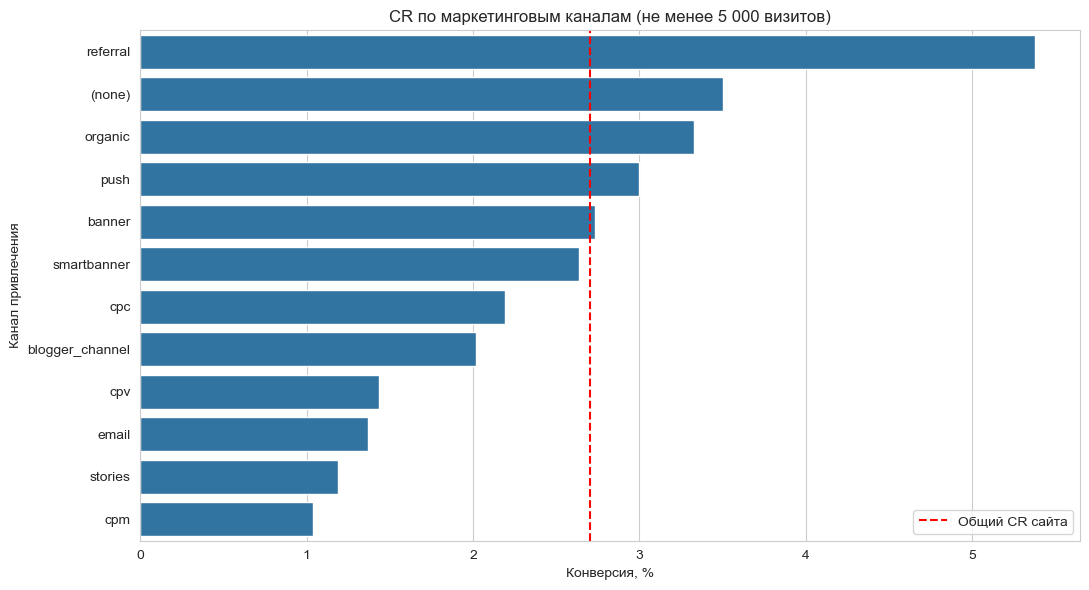

,utm_medium,visits,conversions,CR,"Доля визитов, %"
42,referral,152050,8181,5.38,8.17
0,(none),300575,10531,3.50,16.16
32,organic,63034,2100,3.33,3.39
38,push,28035,840,3.00,1.51
6,banner,552272,15107,2.74,29.69
44,smartbanner,6794,179,2.63,0.37
14,cpc,434794,9529,2.19,23.38
7,blogger_channel,8015,162,2.02,0.43
16,cpv,8022,115,1.43,0.43
19,email,29240,401,1.37,1.57


In [162]:

import matplotlib.pyplot as plt
import seaborn as sns

# Оставляем каналы с достаточным объёмом трафика
reliable_channels = medium_stats[
    medium_stats['visits'] >= 5000
].sort_values('CR', ascending=False).copy()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=reliable_channels,
    x='CR',
    y='utm_medium'
)

plt.axvline(
    sessions['target'].mean() * 100,
    linestyle='--',
    color='red',
    label='Общий CR сайта'
)

plt.title('CR по маркетинговым каналам (не менее 5 000 визитов)')
plt.xlabel('Конверсия, %')
plt.ylabel('Канал привлечения')
plt.legend()
plt.tight_layout()
plt.show()

display(
    reliable_channels[
        ['utm_medium', 'visits', 'conversions', 'CR', 'Доля визитов, %']
    ].round(2)
)

**Вывод по эффективности маркетинговых каналов**

Анализ каналов привлечения показал существенные различия в объёме трафика и коэффициенте конверсии.

Наибольший объём трафика обеспечивает канал `banner` — 552 272 визита, 15 107 конверсий и CR 2,74%. Канал `cpc` занимает второе место по объёму трафика — 434 794 визита, однако его CR составляет 2,19%.

Среди каналов с объёмом не менее 5 000 визитов наиболее высокий CR наблюдается у `referral` — 5,38% при 152 050 визитах. Для каналов `(none)` и `organic` CR составляет 3,50% и 3,33% соответственно. При этом канал `(none)` обеспечивает 10 531 конверсию, что делает его значимым по абсолютному вкладу в результат.

Наиболее низкий CR среди рассмотренных крупных каналов наблюдается у `cpm` — 1,04% при 242 083 визитах. Каналы `email`, `cpv` и `stories` также показывают CR ниже 1,5–1,4% в зависимости от канала.

Таким образом, оценивать маркетинговые каналы следует одновременно по объёму трафика, количеству конверсий и CR. Канал `referral` заслуживает дополнительного изучения благодаря высокой конверсии, а каналы `cpm` и `cpc` требуют более детального анализа качества трафика и рекламных расходов.

При этом полученные результаты описывают наблюдаемую конверсию и сами по себе не доказывают причинного влияния канала на целевые действия. Для решения о перераспределении бюджета необходимо дополнительно учитывать стоимость привлечения, рекламные расходы и коммерческую ценность конверсий.


In [169]:
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

# Разделяем трафик на органический и платный
organic_mediums = ['organic', 'referral', '(none)']

sessions['traffic_type'] = sessions['utm_medium'].apply(
    lambda x: 'organic' if x in organic_mediums else 'paid'
)

# Рассчитываем количество визитов и конверсий по группам
traffic_stats = (
    sessions.groupby('traffic_type')
    .agg(
        visits=('session_id', 'nunique'),
        conversions=('target', 'sum')
    )
)

traffic_stats['CR'] = (
    traffic_stats['conversions'] / traffic_stats['visits'] * 100
)

display(traffic_stats.round(3))

# Проверяем статистическую значимость различия конверсий
counts = traffic_stats.loc[['organic', 'paid'], 'conversions'].to_numpy()
nobs = traffic_stats.loc[['organic', 'paid'], 'visits'].to_numpy()

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative='two-sided'
)

print(f'Z-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.6g}')

alpha = 0.05

if p_value < alpha:
    print('Отвергаем нулевую гипотезу: различие CR статистически значимо.')
else:
    print('Нет оснований отвергнуть нулевую гипотезу.')

,visits,conversions,CR
traffic_type,,,
organic,515659,20812,4.036
paid,1344383,29502,2.194


Z-статистика: 69.3000
p-value: 0
Отвергаем нулевую гипотезу: различие CR статистически значимо.


### Гипотеза 1. Различается ли конверсия органического и платного трафика?

**Гипотезы**

* H₀: конверсия органического и платного трафика одинакова.
* H₁: конверсия органического и платного трафика различается.

**Статистический критерий и тест**

Для сравнения двух долей использован Z-тест для двух пропорций. Уровень статистической значимости: α = 0,05.

**Результат теста**

* Органический трафик: 515 659 визитов, 20 812 конверсий, CR = 4,036%.
* Платный трафик: 1 344 383 визита, 29 502 конверсии, CR = 2,194%.
* Z-статистика = 69,300.
* p-value меньше 0,001.

**Интерпретация результата**

Поскольку p-value меньше уровня значимости 0,05, нулевая гипотеза отвергается. Полученные данные свидетельствуют о статистически значимом различии конверсии органического и платного трафика. CR органического трафика составляет 4,036%, что на 1,842 процентного пункта выше CR платного трафика.

При этом статистическая значимость не доказывает, что тип трафика сам по себе является причиной различий в конверсии.


In [175]:
from statsmodels.stats.proportion import proportions_ztest

# Оставляем только мобильные устройства и компьютеры
device_data = sessions[
    sessions['device_category'].isin(['mobile', 'desktop'])
].copy()

# Рассчитываем визиты и конверсии для каждой группы
device_stats = (
    device_data.groupby('device_category')
    .agg(
        visits=('session_id', 'nunique'),
        conversions=('target', 'sum')
    )
)

device_stats['CR'] = (
    device_stats['conversions'] / device_stats['visits'] * 100
)

display(device_stats.round(3))

# Z-тест для сравнения двух долей
counts = device_stats.loc[
    ['mobile', 'desktop'], 'conversions'
].to_numpy()

nobs = device_stats.loc[
    ['mobile', 'desktop'], 'visits'
].to_numpy()

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative='two-sided'
)

print(f'Z-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.6g}')

if p_value < 0.05:
    print('Отвергаем нулевую гипотезу: различие CR статистически значимо.')
else:
    print('Нет оснований отвергнуть нулевую гипотезу.')

,visits,conversions,CR
device_category,,,
desktop,366863,11513,3.138
mobile,1474871,38379,2.602


Z-статистика: -17.8966
p-value: 1.25367e-71
Отвергаем нулевую гипотезу: различие CR статистически значимо.


### Гипотеза 2. Различается ли конверсия мобильных и десктопных устройств?

**1. Гипотезы**

* **H₀ (нулевая гипотеза):** конверсия (CR) мобильных и десктопных устройств одинакова.
* **H₁ (альтернативная гипотеза):** конверсия мобильных и десктопных устройств различается.

**2. Статистический критерий и тест**

Для проверки гипотезы использован Z-тест для сравнения двух долей. Уровень статистической значимости — \(\alpha = 0{,}05\).

**3. Результат теста**

| Тип устройства | Количество визитов | Количество конверсий |     CR |
| -------------- | -----------------: | -------------------: | -----: |
| Desktop        |            366 863 |               11 513 | 3,138% |
| Mobile         |          1 474 871 |               38 379 | 2,602% |

Результаты статистического теста:

* Z-статистика: −17,8966.
* p-value: \(1{,}25367 \cdot 10^{-71}\).

Поскольку p-value меньше 0,05, нулевая гипотеза отвергается.

**4. Интерпретация**

Между конверсией мобильных и десктопных устройств существует статистически значимое различие. Конверсия десктопных устройств составляет 3,138%, а мобильных — 2,602%. Таким образом, CR десктопных устройств выше на 0,536 процентного пункта.

При этом мобильные устройства обеспечивают значительно больший объём трафика и абсолютное количество конверсий. Поэтому при анализе эффективности устройств необходимо учитывать не только CR, но и количество визитов и целевых действий.

**Вывод:** следует дополнительно изучить пользовательский путь на мобильных устройствах, удобство заполнения форм и работу интерфейса. Полученные результаты показывают наличие статистической связи, но сами по себе не доказывают, что тип устройства является причиной различий в конверсии.


In [166]:

from statsmodels.stats.proportion import proportions_ztest

# Указываем правильный порядок групп для сравнения.
groups = ['Москва + МО + Санкт-Петербург', 'Другие регионы']

# Рассчитываем количество визитов и конверсий по двум группам.
geo_stats = sessions.groupby('region_group').agg(
    visits=('session_id', 'nunique'),
    conversions=('target', 'sum')
)

# Рассчитываем CR в процентах.
geo_stats['CR'] = (
    geo_stats['conversions'] / geo_stats['visits'] * 100
)

# Выводим результаты по обеим группам.
display(geo_stats.loc[groups].round(3))

# Подготавливаем данные для Z-теста.
counts = geo_stats.loc[groups, 'conversions'].to_numpy()
nobs = geo_stats.loc[groups, 'visits'].to_numpy()

# Проверяем, является ли различие CR статистически значимым.
z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=nobs,
    alternative='two-sided'
)

print(f'Z-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.6g}')

if p_value < 0.05:
    print('Отвергаем нулевую гипотезу: различие CR статистически значимо.')
else:
    print('Нет оснований отвергнуть нулевую гипотезу.')

,visits,conversions,CR
region_group,,,
Москва + МО + Санкт-Петербург,1167201,32679,2.800
Другие регионы,692841,17635,2.545


Z-статистика: 10.3423
p-value: 4.53681e-25
Отвергаем нулевую гипотезу: различие CR статистически значимо.


**1. Гипотезы**

* **H₀ (нулевая гипотеза):** коэффициент конверсии (CR) в Москве, Московской области и Санкт-Петербурге не отличается от CR в остальных регионах.
* **H₁ (альтернативная гипотеза):** коэффициент конверсии в этих географических группах различается.

**2. Статистический критерий и тест**

Для проверки гипотезы использован Z-тест для сравнения двух долей. Уровень статистической значимости — \(\alpha = 0{,}05\).

**3. Результат теста**

| Географическая группа         | Количество визитов | Количество конверсий |     CR |
| ----------------------------- | -----------------: | -------------------: | -----: |
| Москва + МО + Санкт-Петербург |          1 167 201 |               32 679 | 2,800% |
| Другие регионы                |            692 841 |               17 635 | 2,545% |

Результаты статистического теста:

* Z-статистика: 10,3423.
* p-value: \(4{,}53681 \cdot 10^{-25}\).

Поскольку p-value меньше 0,05, нулевая гипотеза отвергается.

**4. Интерпретация**

Между двумя географическими группами существует статистически значимое различие в конверсии. В Москве, Московской области и Санкт-Петербурге CR составляет 2,800%, тогда как в остальных регионах — 2,545%. Разница составляет 0,255 процентного пункта в пользу первой группы.

При этом группа Москвы, Московской области и Санкт-Петербурга обеспечивает 1 167 201 визит и 32 679 конверсий, что делает её значимой для бизнеса по объёму трафика и количеству целевых действий.

**Вывод:** при планировании маркетинговых активностей следует учитывать географические различия в конверсии и отдельно анализировать эффективность рекламных каналов в разных регионах. Результаты показывают статистически значимую связь между географической группой и CR, но не доказывают, что география сама по себе является причиной различий.


In [167]:

import pandas as pd
from IPython.display import display

# Итоговая таблица проверки статистических гипотез.
hypotheses_summary = pd.DataFrame({
    '№': [1, 2, 3],
    'Проверяемая гипотеза': [
        'Органический и платный трафик',
        'Мобильные и десктопные устройства',
        'Москва, МО и Санкт-Петербург и другие регионы'
    ],
    'Результаты сравнения CR': [
        'Органический: 4,036%; платный: 2,194%',
        'Mobile: 2,602%; Desktop: 3,138%',
        'Москва, МО и Санкт-Петербург: 2,800%; другие регионы: 2,545%'
    ],
    'Z-статистика': [69.3000, -17.8966, 10.3423],
    'p-value': ['< 0,001', '< 0,001', '< 0,001'],
    'Решение': [
        'H₀ отвергается',
        'H₀ отвергается',
        'H₀ отвергается'
    ]
})

display(hypotheses_summary)

,№,Проверяемая гипотеза,Результаты сравнения CR,Z-статистика,p-value,Решение
0,1,Органический и платный трафик,"Органический: 4,036%; платный: 2,194%",69.3000,"< 0,001",H₀ отвергается
1,2,Мобильные и десктопные устройства,"Mobile: 2,602%; Desktop: 3,138%",-17.8966,"< 0,001",H₀ отвергается
2,3,"Москва, МО и Санкт-Петербург и другие регионы","Москва, МО и Санкт-Петербург: 2,800%; другие р...",10.3423,"< 0,001",H₀ отвергается


### Общий вывод по результатам проверки гипотез

В ходе исследования были проверены три гипотезы о различиях коэффициента конверсии (CR) в зависимости от типа трафика, устройства и географической группы.

По результатам Z-тестов во всех трёх случаях выявлены статистически значимые различия при уровне значимости 0,05. Следовательно, нулевые гипотезы отвергаются.

Наибольшая разница в конверсии наблюдается между органическим и платным трафиком: CR органического трафика составляет 4,036%, а платного — 2,194%. Конверсия десктопных устройств выше мобильных на 0,536 процентного пункта. В Москве, Московской области и Санкт-Петербурге CR составляет 2,800%, что на 0,255 процентного пункта выше, чем в остальных регионах.

Полученные результаты позволяют выделить группы с различающейся конверсией и определить направления для дальнейшего анализа. При принятии маркетинговых решений необходимо учитывать не только CR, но и объём трафика, количество конверсий и стоимость привлечения клиентов. Статистическая значимость различий сама по себе не доказывает причинно-следственную связь.

## Выводы
1. Выводы по результатам анализа

В ходе анализа были исследованы повторные визиты, типы устройств, география пользователей, время суток, день недели, сочетание дня недели и часа, а также эффективность маркетинговых источников и рекламных кампаний. Для оценки эффективности использовались объём трафика, количество целевых действий и коэффициент конверсии (CR).

1.1. Первичные и повторные визиты

Конверсия повторных визитов заметно выше конверсии первого визита:

    Первый визит: CR — 2,35%, 32 366 конверсий из 1 376 349 визитов.
    Повторные визиты: CR — 3,71%, 17 948 конверсий из 483 693 визитов.

Разница составляет около 1,36 процентного пункта. Статистический тест показал, что различие между группами статистически значимо.

Таким образом, пользователи, которые возвращаются на сайт, чаще совершают целевые действия. При этом более высокая конверсия повторных визитов сама по себе не доказывает, что повторное посещение является причиной повышения CR: на результат могут влиять намерения пользователей и другие факторы.

1.2. Тип устройства и номер визита

При первом визите конверсия пользователей desktop и mobile практически одинакова:

    Desktop — 2,36%.
    Mobile — 2,35%.
    p-value = 0,651.

Статистически значимого различия на первом визите не обнаружено.

Начиная со второго визита, различия между устройствами становятся заметнее:

    Второй визит: desktop — 4,41%, mobile — 2,95%.
    Третий визит: desktop — 5,25%, mobile — 3,34%.
    Четвёртый–пятый визиты: desktop — 5,45%, mobile — 4,06%.
    Шестой–десятый визиты: desktop — 5,25%, mobile — 4,46%.
    21 и более визитов: desktop — 4,22%, mobile — 2,95%.

Для перечисленных групп статистические тесты показали p-value ниже 0,05. Для группы 11–20 визитов статистически значимого различия не обнаружено: desktop — 4,04%, mobile — 4,39%, p-value = 0,190.

Результаты показывают, что эффективность устройств целесообразно оценивать с учётом номера визита, а не только по общему CR для desktop и mobile.

1.3. География пользователей

Основная часть трафика поступает из России:

    Россия — 96,80% всех визитов, CR — 2,73%.
    Украина — 0,48%, CR — 2,21%.
    США — 0,63%, CR — 0,54%.
    Германия — 0,12%, CR — 3,49%.
    Великобритания — 0,08%, CR — 3,08%.

На Россию приходится подавляющая часть трафика, поэтому именно этот сегмент в значительной степени определяет общий результат сайта.

Показатели стран с небольшим количеством визитов необходимо интерпретировать осторожно. Высокий CR при малом объёме трафика не обязательно означает устойчивое преимущество данного сегмента.

Внутри России наибольшая доля трафика приходится на Москву и Санкт-Петербург:

    Москва — 44,73% российского трафика, CR — 2,93%.
    Санкт-Петербург — 16,48%, CR — 2,40%.

При этом некоторые города показывают более высокий CR:

    Казань — 3,86%.
    Сочи — 3,52%.
    Краснодар — 3,35%.
    Химки — 3,20%.
    Грозный — 3,15%.

Однако высокий CR не всегда означает большой вклад в общее количество конверсий. Для оценки регионов важно одновременно учитывать конверсию, объём трафика и число целевых действий.

1.4. Время суток

Анализ показал различия в конверсии между временными интервалами:

    Ночь (00:00–05:59) — 10,76% трафика, CR — 2,58%.
    Утро (06:00–11:59) — 24,59%, CR — 2,60%.
    День (12:00–17:59) — 33,67%, CR — 3,00%.
    Вечер (18:00–23:59) — 30,99%, CR — 2,51%.

На дневной период приходится наибольшая доля визитов, и в это же время наблюдается самый высокий CR среди рассмотренных интервалов.

Результаты статистических сравнений:

    Ночь и утро — различие статистически незначимо.
    Ночь и день — различие статистически значимо.
    Ночь и вечер — различие статистически незначимо.
    Утро и день — различие статистически значимо.
    Утро и вечер — после корректировки множественных сравнений различие статистически незначимо.
    День и вечер — различие статистически значимо.

Таким образом, дневной период заслуживает дополнительного внимания при анализе рекламной активности и поведения пользователей. При этом для решения о перераспределении рекламного бюджета необходимо учитывать не только CR, но и расходы на рекламу, стоимость привлечения и качество полученных конверсий.

1.5. День недели и сочетание дня недели с часом

CR различается в зависимости от дня недели:

    Monday — 3,15%.
    Tuesday — 2,84%.
    Wednesday — 2,81%.
    Thursday — 2,63%.
    Friday — 2,44%.
    Saturday — 2,46%.
    Sunday — 2,45%.

Доля трафика по дням недели относительно равномерна и составляет примерно 12–16%. Это позволяет предположить наличие различий в поведении пользователей в течение недели. Однако для окончательного вывода о статистической значимости различий между всеми днями необходим отдельный статистический тест.

Дополнительный анализ сочетания дня недели и часа показал, что CR может различаться даже внутри одного дня. Среди комбинаций с минимум 5 000 визитов наиболее высокие значения наблюдаются у следующих интервалов:

    Monday, 13:00 — 3,91%.
    Monday, 11:00 — 3,81%.
    Monday, 16:00 — 3,62%.
    Monday, 12:00 — 3,57%.
    Monday, 17:00 — 3,53%.
    Tuesday, 11:00 — 3,35%.
    Wednesday, 13:00 — 3,34%.

Это указывает на то, что анализ только дня недели или только часа может скрывать дополнительные закономерности. Указанные значения следует рассматривать как описательные результаты, если статистическая значимость различий между этими комбинациями отдельно не проверялась.

1.6. Маркетинговые источники и рекламные кампании

Общий CR сайта составляет около 2,70%. Количество конверсий и коэффициент конверсии различаются между маркетинговыми связками «источник × кампания».

Наибольший вклад в абсолютное количество конверсий среди рассмотренных связок дают:

    fDLlAcSmythWSCVMvqvL × LTuZkdKfxRGVceoWkVyg — 10 531 конверсия, 20,93% всех конверсий, CR — 3,50%.
    ZpYIoDJMcFzVoPFsHGJL × LEoPHuyFvzoNfnzGgfcd — 9 179 конверсий, 18,24%, CR — 2,84%.
    ZpYIoDJMcFzVoPFsHGJL × gecBYcKZCPMcVYdSSzKP — 4 398 конверсий, 8,74%, CR — 3,31%.
    bByPQxmDaMXgpHeypKSM × LTuZkdKfxRGVceoWkVyg — 3 759 конверсий, 7,47%, CR — 5,38%.

Среди крупных связок высокий CR наблюдается у следующих комбинаций:

    aXQzDWsJuGXeBXexNHjc × LTuZkdKfxRGVceoWkVyg — 5,86% при 31 152 визитах.
    bByPQxmDaMXgpHeypKSM × LTuZkdKfxRGVceoWkVyg — 5,38% при 69 841 визите.
    kjsLglQLzykiRbcDiGcD × LTuZkdKfxRGVceoWkVyg — 4,97% при 33 565 визитах.

Сравнение отдельных источников с общим CR показывает, что некоторые источники заметно превосходят средний показатель, тогда как у других CR существенно ниже:

    aXQz... — 5,86%, на 3,16 п.п. выше общего CR.
    bByPQ... — 5,43%, на 2,73 п.п. выше.
    fDLl... — 3,50%, на 0,80 п.п. выше.
    BHcv... — 3,34%, на 0,63 п.п. выше.
    ZpY... — 2,77%, на 0,06 п.п. выше.
    kjs... — 2,36%, на 0,34 п.п. ниже.
    MvfH... — 1,21%, на 1,50 п.п. ниже.
    gDBG... — 0,01%, на 2,69 п.п. ниже.

## Итоговые выводы и рекомендации

### Итоговые выводы

В ходе работы был проведён анализ данных сайта «СберАвтоподписка»: выполнены подготовка и очистка данных, исследовательский анализ, изучение целевых действий пользователей, проверка статистических гипотез, а также оценка маркетинговых источников, рекламных кампаний и спроса на автомобили.

Общая конверсия сайта в целевые действия составляет около **2,70%**. Анализ показал, что вероятность совершения целевого действия различается в зависимости от поведения пользователей, типа устройства, географии, времени посещения и источника трафика.

**Повторные визиты** характеризуются более высокой конверсией, чем первые: 3,71% против 2,35%. Это указывает на важность анализа возвращающихся пользователей отдельно от новых.

**Тип устройства** также связан с различиями в конверсии. По результатам анализа desktop показывает CR около 3,14%, а mobile — около 2,60%. При этом мобильные устройства обеспечивают значительно больший объём трафика, поэтому улучшение пользовательского опыта на мобильной версии сайта может помочь увеличить число целевых действий.

**Географический анализ** показал, что основная часть трафика поступает из России. Значительная доля посещений приходится на Москву, Московскую область и Санкт-Петербург. При этом некоторые другие города демонстрируют сравнительно высокий CR и могут представлять интерес для дальнейшего исследования.

**Время посещения** также связано с конверсией. Среди рассмотренных интервалов самый высокий CR наблюдается днём, с 12:00 до 17:59, — около 3,00%. В течение недели и в отдельных сочетаниях дня и часа также наблюдаются различия, однако описательные показатели не следует автоматически считать доказательством статистически значимых различий.

**Маркетинговые источники и рекламные кампании** существенно различаются по количеству целевых действий и CR. Некоторые источники превосходят общий показатель конверсии, тогда как у других он заметно ниже. Поэтому оценивать каналы только по объёму трафика или только по CR недостаточно.

**Анализ автомобилей** показал, что среди наиболее востребованных моделей выделяются Skoda Rapid, Lada Vesta и Volkswagen Polo. Среди моделей с достаточным объёмом данных высокий CR наблюдается у Hyundai Solaris, Kia Rio, Toyota Camry и Volkswagen Polo. При продвижении автомобилей важно учитывать одновременно популярность модели и её конверсию.

**Трафик из социальных сетей** имеет CR около 1,47%, что ниже показателя остальных источников — около 2,92%. Однако эффективность отдельных социальных источников различается, поэтому принимать решение об отказе от всего социального трафика или об увеличении бюджета без дополнительного анализа нецелесообразно.

### Рекомендации

1. **Оптимизировать маркетинговые источники и кампании.** При оценке каналов учитывать объём трафика, количество целевых действий и CR. Дополнительно анализировать рекламные расходы, стоимость привлечения клиента и коммерческую ценность конверсий.

2. **Повысить эффективность мобильной версии сайта.** Проверить скорость загрузки, удобство заполнения форм, отображение элементов интерфейса и путь пользователя к целевому действию.

3. **Учитывать повторные визиты.** Анализировать новых и возвращающихся пользователей отдельно, чтобы лучше понимать различия в их поведении и эффективности каналов привлечения.

4. **Учитывать географические особенности.** При выборе регионов для продвижения сравнивать объём трафика, число целевых действий и CR. Высокие показатели небольших сегментов следует проверять с учётом размера выборки.

5. **Учитывать спрос и конверсию автомобилей.** При продвижении моделей оценивать не только популярность, но и способность привлекать целевые действия. Это позволит точнее выбирать модели для рекламных кампаний.

6. **Оптимизировать рекламу в социальных сетях.** Изучить причины низкой конверсии и отдельно оценить каждый социальный источник. Перераспределять бюджет только после анализа результатов и стоимости привлечения.

7. **Продолжить сегментный анализ.** Исследовать сочетания «источник × устройство», «регион × источник» и «модель автомобиля × источник», чтобы выявить наиболее эффективные комбинации.

8. **Проверять статистическую и экономическую значимость результатов.** При большом количестве сравнений учитывать множественные проверки и размер выборки. Статистически значимое различие не всегда означает существенную практическую выгоду.

### Итог

Проведённый анализ позволил выявить различия в конверсии пользователей и эффективности маркетинговых источников, определить особенности поведения посетителей и выделить направления для дальнейшей оптимизации сайта и рекламной активности.

Основными направлениями дальнейшей работы являются повышение конверсии мобильного трафика, анализ повторных визитов, оптимизация рекламных источников, изучение региональных особенностей и учёт спроса на конкретные модели автомобилей.

Для принятия окончательных решений о распределении рекламного бюджета необходимо дополнить результаты данными о расходах на рекламу, стоимости привлечения клиентов и фактической ценности целевых действий.